<div style="background:linear-gradient(120deg,#0B1B33 0%,#1d4f91 62%,#FF7A1A 150%);padding:34px 38px;border-radius:16px;color:#fff;font-family:system-ui,Segoe UI,Roboto,sans-serif">
<div style="font-size:12px;letter-spacing:.18em;text-transform:uppercase;color:#FFB347;font-weight:600">UCI Machine Learning Repository &nbsp;·&nbsp; Steel Industry Energy Consumption</div>
<div style="font-size:36px;font-weight:800;margin:8px 0 8px;color:#fff;line-height:1.15">Steel Plant Energy: Analysis, Forecasting &amp; Prediction Website</div>
<div style="font-size:16px;color:#d6e4f7;max-width:780px;line-height:1.5">One steel plant, <b>35,040 meter readings</b> (every 15 minutes through 2018): explored, forecast, clustered, screened for anomalies, and finally packaged into a website where you type in readings and get a prediction.</div>
</div>

### What is inside

| Part | What you get |
|---|---|
| **1 · Setup & data quality** | Loading, timestamp repair, lag features, validation checks |
| **2 · Executive dashboard** | KPI cards and a one-page picture of the whole year |
| **3 · Usage patterns** | Hour / weekday / month rhythms, heat-maps, calendar view, peaks, correlations, autocorrelation, hypothesis H1 |
| **4 · Load types & power factor** | Load-type behaviour, H2, power-factor compliance, capacitor sizing hint |
| **5 · Forecasting (H3)** | Models vs simple guesses, honest chronological testing, **model deep-dive** (errors, importance) |
| **6 · Grouping similar days (H4)** | K-means day types, PCA map, calendar of day types |
| **7 · Unusual readings (H5)** | Forecast-error anomaly screening and events |
| **8 · Savings what-if** | Energy and CO₂ savings with sensitivity analysis |
| **9 · Meter readings → energy** | A second model: estimate kWh and load type from reactive power and power factor |
| **10 · Conclusions & website** | Hypothesis scorecard, and one cell that trains and exports everything the website uses |

> **How to run:** *Run All*. On Kaggle the dataset is picked up automatically; locally keep `Steel_industry_data.csv` in `../data/` (as in the project folder) or next to this notebook. Every chart is also saved as a PNG in `outputs/figures/`.

<div style="background:linear-gradient(90deg,#0B1B33,#2F6DB5);padding:16px 22px;border-radius:12px;color:#fff;margin:26px 0 8px;font-family:system-ui,Segoe UI,Roboto,sans-serif"><div style="font-size:11px;letter-spacing:.16em;text-transform:uppercase;color:#FFB347;font-weight:600">Part 1</div><div style="font-size:22px;font-weight:700;margin:2px 0 4px;color:#fff">Setup & data quality</div><div style="font-size:13.5px;color:#d6e4f7">Load the data, repair the midnight timestamps, build lag features and validate everything.</div></div>

In [1]:
import os
import sys
import json
import time
import shutil
import calendar
import subprocess
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import sklearn
import scipy
from IPython.display import display, Markdown, HTML

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

---
## Importing Required Libraries

- `os`  - interact with operating system files and directories.
- `sys` - access Python interpreter settings and system-related functionality.
- `calendar` - calendar-related operations, including month names and dates.
- `warnings` - manages warning messages generated during code execution.
- `numpy` (`np`) - numerical calculations and mathematical operations.
- `pandas` (`pd`) - tools for data manipulation, cleaning, and analysis.
- `matplotlib.pyplot` (`plt`) - creates charts, graphs, and data visualizations.
- `matplotlib.dates` (`mdates`) - date formatting and plotting on axes.
- `sklearn` - machine learning algorithms, preprocessing, and evaluation tools.
- `scipy` - scientific computing, statistics, and mathematical functions.
- `display` - renders DataFrames and other objects directly inside Jupyter notebooks.
- `Markdown` - displays formatted Markdown content directly inside notebook outputs.
- `warnings.filterwarnings()` - controls which warning messages Python displays.
- `FutureWarning` - indicates potential changes to functionality in future library versions.
- Ignoring `FutureWarning` keeps notebook outputs cleaner and easier to read.
- `seaborn` (`sns`) - statistical graphics such as heat-maps and violin plots with attractive defaults.
- `json`, `time`, `shutil`, `subprocess` - save web-app data, time long steps, copy files, and run the website training script.
- `HTML` - renders styled KPI cards directly inside notebook outputs.
---


In [2]:
SEED = 42

# Dataset: added on Kaggle (Add Input), or kept next to this notebook / in the website's data folder
KAGGLE_PATH = "/kaggle/input/datasets/pruthviprasads/steel-industry-energy-consumption-2018/Steel_industry_data.csv"
_candidates = [KAGGLE_PATH, "Steel_industry_data.csv", "data/Steel_industry_data.csv",
               "../data/Steel_industry_data.csv", "steel_energy_app/data/Steel_industry_data.csv"]
if os.path.isdir("/kaggle/input"):
    import glob
    _candidates += glob.glob("/kaggle/input/**/Steel_industry_data.csv", recursive=True)
file_path = next((p for p in _candidates if os.path.exists(p)), KAGGLE_PATH)

OUTPUT_DIR = "outputs"
ASSUMED_CO2_KG_PER_KWH = 0.455
SAVING_FRACTION = 0.10
IDLE_THRESHOLD_KWH = 5

# Months used to choose the best model / best simple guess
SELECTION_MONTHS = ["Jun", "Jul", "Aug", "Sep"]

FINAL_TEST_START, FINAL_TEST_END = pd.Timestamp("2018-10-01"), pd.Timestamp("2019-01-01")

---

## Configuration and Project Settings

## Reproducibility and Experimental Settings

- `SEED = 42` ensures reproducible random results across experiments.
- A fixed seed makes **comparisons between model runs more reliable**.
- It helps **prevent random variations** from affecting experimental conclusions.

## Carbon Emission Estimation

- `ASSUMED_CO2_KG_PER_KWH = 0.455` estimates **emissions per consumed kilowatt-hour**.
- It **converts electricity consumption** into **estimated carbon dioxide emissions.**
- It enables approximate environmental impact calculations from energy consumption.

## Energy Saving Assumption

- `SAVING_FRACTION = 0.10` represents a hypothetical ten-percent energy reduction.
- It estimates achievable savings without changing the original consumption data.
- Ten percent provides a simple scenario for evaluating potential improvements.
- It helps quantify possible energy and emission reductions.

## Idle Consumption Threshold

- `IDLE_THRESHOLD_KWH = 5` defines the threshold for **identifying low consumption**.
- Readings below **5 kWh** are considered **potential idle consumption**.
- It helps identify energy consumed during **low-activity operating periods**.
- The threshold simplifies idle-energy analysis using a fixed consumption boundary.

## Model Selection Period

- `SELECTION_MONTHS` specifies **months used** for model-selection evaluation.
- **June, July, August, and September are selected for comparisons**.
- These months help compare forecasting models before final testing.
- **Model selection avoids using the final test period for tuning**.

## Final Testing Period

- `FINAL_TEST_START` marks the beginning of the final evaluation period.
- October 1st, 2018, begins the final testing period.
- `FINAL_TEST_END` marks the exclusive ending boundary of final evaluation.
- January 1st, 2019, excludes January observations from the test period.
- Final testing therefore includes **October, November, and December 2018.**
- **This separation evaluates model performance on unseen chronological data**.
---

In [3]:
np.random.seed(SEED)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | scipy {scipy.__version__}")

# Check whether the uploaded dataset exists
assert os.path.exists(file_path), f"Dataset not found: {file_path}"

print("Reading:", file_path)

Python 3.12.3 | pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1 | scipy 1.18.1
Reading: ../data/Steel_industry_data.csv


---
## Environment Setup and Dataset Validation

### Reproducibility
- `np.random.seed(SEED)` sets NumPy's random generator to a fixed starting state.
- `SEED` is set to `42`, **so the same seed is used every time**.
- NumPy uses this seed to generate a predictable sequence of random numbers.
- Normally, **random operations can produce different values** during different executions.
- Setting a seed makes random results repeatable when code runs again.
- This helps maintain consistency when performing experiments or testing models.
- It allows **fair comparisons between models** by reducing random variation.

### Library Version Verification
- `sys.version.split()[0]` - extracts the installed Python version.
- `pd.__version__` - displays the installed pandas version.
- `np.__version__` - displays the installed NumPy version.
- `sklearn.__version__` - displays the installed scikit-learn version.
- `scipy.__version__` - displays the installed SciPy version.
- Version information helps identify software compatibility issues.
- Different library versions may produce different behaviors or results.
---

<div style="background:linear-gradient(90deg,#0B1B33,#2F6DB5);padding:16px 22px;border-radius:12px;color:#fff;margin:26px 0 8px;font-family:system-ui,Segoe UI,Roboto,sans-serif"><div style="font-size:11px;letter-spacing:.16em;text-transform:uppercase;color:#FFB347;font-weight:600">Design system</div><div style="font-size:22px;font-weight:700;margin:2px 0 4px;color:#fff">A consistent look for every chart</div><div style="font-size:13.5px;color:#d6e4f7">One palette, one set of fonts and helpers, so every figure in the notebook looks like part of the same report.</div></div>

- **Palette** - steel blue for normal/weekday, ember orange for highlights/weekend/peaks, teal and violet for supporting series.
- `style_title(ax, title, subtitle)` - left-aligned bold title with a grey one-line takeaway underneath.
- `finish(fig, name)` - tidy layout, save a PNG into `outputs/figures/`, then show the figure.
- `kpi_cards([...])` - styled headline numbers. `finding(text)` - the "What we found" boxes.

In [4]:
# ---------- Palette ----------
C = dict(navy="#0B1B33", steel="#2F6DB5", sky="#6AB0F0", ember="#FF7A1A", gold="#FFB347",
         teal="#14B8A6", rose="#E5484D", violet="#7C5CFC", slate="#64748B", mist="#EEF3FA", ink="#1E293B")
BLUE, ORANGE, TEAL, VIOLET, ROSE, GOLD, SLATE = C["steel"], C["ember"], C["teal"], C["violet"], C["rose"], C["gold"], C["slate"]

LOAD_ORDER = ["Light_Load", "Medium_Load", "Maximum_Load"]
LOAD_LABELS = ["Light", "Medium", "Maximum"]
LOAD_COLORS = {"Light_Load": C["sky"], "Medium_Load": C["gold"], "Maximum_Load": C["ember"]}
GROUP_COLORS = {"Quiet": C["sky"], "Normal": C["teal"], "Busy": C["ember"]}
DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
MONTH_NAMES = list(calendar.month_abbr)[1:]

from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
CMAP_HEAT = LinearSegmentedColormap.from_list("ember", ["#F6F9FD", "#FFE0BD", "#FFA24D", "#E8590C", "#7A1F0B"])
CMAP_COOL = LinearSegmentedColormap.from_list("steel", ["#F6F9FD", "#BBD7F3", "#6AB0F0", "#2F6DB5", "#0B1B33"])
CMAP_DIV = sns.diverging_palette(230, 25, as_cmap=True)

# ---------- Matplotlib look ----------
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "white",
    "axes.facecolor": "#FBFCFE", "axes.edgecolor": "#CBD5E1", "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": "#E6ECF5", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10.5, "axes.labelcolor": C["ink"],
    "xtick.color": C["slate"], "ytick.color": C["slate"], "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "legend.frameon": False, "legend.fontsize": 9.5, "lines.linewidth": 2.2,
    "axes.prop_cycle": mpl.cycler(color=[C["steel"], C["ember"], C["teal"], C["violet"], C["rose"], C["gold"]]),
})

FIG_DIR = os.path.join(OUTPUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)


def style_title(ax, title, subtitle=None):
    """Bold left-aligned title with an optional grey takeaway line underneath."""
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=C["navy"], pad=25 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.018, subtitle, transform=ax.transAxes, fontsize=9.5, color=C["slate"], va="bottom")


def finish(fig, name=None):
    """Tidy the layout, save a PNG (if a name is given) and show the figure."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        fig.tight_layout()
    if name:
        fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()


def kpi_cards(items):
    """items = [(label, value, note, colour), ...]"""
    cards = "".join(
        f'<div style="flex:1 1 170px;min-width:170px;background:#fff;border:1px solid #E2E8F0;border-left:5px solid {color};'
        f'border-radius:12px;padding:14px 16px;box-shadow:0 2px 8px rgba(15,30,60,.06)">'
        f'<div style="font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#64748B;font-weight:600">{label}</div>'
        f'<div style="font-size:26px;font-weight:700;color:#0B1B33;margin:2px 0">{value}</div>'
        f'<div style="font-size:12px;color:#64748B">{note}</div></div>'
        for label, value, note, color in items)
    display(HTML('<div style="display:flex;flex-wrap:wrap;gap:12px;margin:8px 0 16px;'
                 f'font-family:system-ui,Segoe UI,Roboto,sans-serif">{cards}</div>'))


def finding(text, title="What we found"):
    display(Markdown(f"### 🔎 {title}\n\n{text}"))


print("Design system ready.")

Design system ready.


In [5]:
# Load dataset
df = pd.read_csv(file_path)

assert df.shape[1] == 11, f"Expected 11 columns, found {df.shape[1]}. Check the separator."

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (35040, 11)


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


---

### Successful Loading Output
- `Dataset loaded successfully!` confirms the assertion passed.
- `Shape: (35040, 11)` => dataset contains **35,040 observations across 11 columns**.

### Interpreting the Displayed Columns
- `date` - timestamps representing when each observation was recorded.
- `Usage_kWh` - electricity consumption for each observation.
- `Lagging_Current_Reactive.Power_kVarh` - lagging reactive energy.
- `Leading_Current_Reactive_Power_kVarh` - leading reactive energy.
- `CO2(tCO2)` - carbon dioxide emission measurements in tonnes.
- `Lagging_Current_Power_Factor` - lagging power-factor measurements.
- `Leading_Current_Power_Factor` - leading power-factor measurements.
- `NSM` - the number of seconds since midnight.
- `WeekStatus` - observations as weekday or weekend.
- `Day_of_week` - the day of the week for each record.
- `Load_Type` - classifies consumption into light, medium, or maximum load conditions.
---

## Understanding Reactive Energy and Power Factor

### Lagging Reactive Energy
- `Lagging_Current_Reactive.Power_kVarh` measures lagging reactive energy consumption.
- Reactive energy supports **magnetic fields in inductive electrical equipment**.
- It is required by motors, transformers, and other inductive devices.
- **Inductive equipment causes current to lag behind voltage.**
- Reactive energy is measured in **kilovolt-ampere reactive hours (kVARh).**
- **High lagging reactive energy** => inefficient electrical power utilization.
- Increases burden on electrical infrastructure without producing useful work directly.

### Leading Reactive Energy
- `Leading_Current_Reactive_Power_kVarh` measures leading reactive energy.
- Leading reactive energy occurs when **current leads voltage.**
- **Capacitors** commonly produce leading reactive power in electrical systems.
- Capacitor banks **compensate** for inductive reactive power consumed by motors.
- Excessive leading reactive energy may indicate **overcompensation.**
- Reactive energy is measured in **kilovolt-ampere reactive hours (kVARh).**

#### => Both leading and lagging reactive energy affect electrical system power characteristics.
---
### Lagging Power Factor
- `Lagging_Current_Power_Factor` measures power factor under lagging conditions.
- Describes how effectively **electrical power is converted into useful work.**
- Lagging power factor commonly occurs with **inductive industrial equipment.**
- Motors and transformers frequently cause lagging power-factor behavior.
- Power factor ranges from **zero to one, or zero to 100%**
- Values closer to one indicate better utilization of supplied electrical power.
- Lower lagging power factor can **increase current** for equivalent useful power.
- This can **increase electrical losses and equipment loading.**

### Leading Power Factor
- `Leading_Current_Power_Factor` measures power factor under leading conditions.
- Leading power factor occurs when **current leads voltage.**
- **Capacitive equipment** commonly produces leading power-factor behavior.
- Capacitor banks can improve power factor when inductive loads dominate.
- **Excessive capacitance** can cause the system to become overly leading.
- Leading power factor also describes **voltage-current phase relationships.**
- Values closer to one indicate a power factor magnitude closer to unity.

#### => Both leading and lagging conditions matter for industrial electrical management.
---

In [6]:
print("Rows and columns:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df["date"].duplicated().sum())

print("\nMissing values in each column:")
print(df.isna().sum())

Rows and columns: (35040, 11)
Duplicate rows: 0
Duplicate timestamps: 0

Missing values in each column:
date                                    0
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
CO2(tCO2)                               0
Lagging_Current_Power_Factor            0
Leading_Current_Power_Factor            0
NSM                                     0
WeekStatus                              0
Day_of_week                             0
Load_Type                               0
dtype: int64


---
## Dataset Quality Checks

### Duplicate Row Check
- `Duplicate rows: 0` indicates no identical rows were found.
- Duplicate records could incorrectly inflate counts and statistical results.
- Reduces the risk of repeated observations affecting analysis.

### Duplicate Timestamp Check
- `Duplicate timestamps: 0` indicates every timestamp is unique.
- Unique timestamps prevent multiple records sharing the same recorded time.
- Can maintain a consistent chronological sequence for time-series analysis.

### Missing Value Check
- Missing values represent absent or unrecorded data entries.
- The output shows zero missing values across all eleven columns.
- Completeness reduces complications during statistical analysis and model training.
---

In [7]:
assert len(df) == 365 * 96

original_time = pd.to_datetime(df["date"], format="%d-%m-%Y %H:%M", errors="coerce")
if original_time.isna().any():
    original_time = pd.to_datetime(df["date"], format="%d/%m/%Y %H:%M")

---
## Correcting Midnight Timestamp Errors

- Original timestamps incorrectly label midnight readings with the **previous date.**
- Rebuilds timestamps starting from January 1, 2018, at 00:15.
- Adds 15 minutes per row to create a continuous timeline.

---
  
- `interval_day` assigns midnight readings to the preceding consumption day.
- This preserves the final 15-minute interval in daily energy totals.
- `pd.to_datetime()` converts timestamp strings into datetime objects.
- `%d-%m-%Y %H:%M` parses day-month-year timestamps with time.
---
- A fallback parser accommodates slash-separated dates in alternate dataset copies.
- Correct timestamps ensure reliable time-based aggregation and forecasting.
---

In [8]:
df["timestamp"] = pd.date_range(
    start="2018-01-01 00:15",
    periods=len(df),
    freq="15min"
)

---
## Reconstructing the Timestamp Sequence

- `pd.date_range()` generates a continuous sequence of timestamps.
- `start="2018-01-01 00:15"` sets the first timestamp.
- `periods=len(df)` generates one timestamp per dataset row.
- `freq="15min"` sets the interval between consecutive timestamps.
- The generated timestamps replace the original values in `df["timestamp"]`.
- This corrects **midnight date errors** and ensures consistent chronological spacing.
---

In [9]:
df["interval_day"] = (
    df["timestamp"] - pd.Timedelta(minutes=15)
).dt.normalize()

---
## Assigning Consumption Dates

- `pd.Timedelta(minutes=15)` represents one 15-minute interval.
- Subtracting 15 minutes shifts timestamps to interval start times.
- `.dt.normalize()` removes the time component, retaining only the date.
- `interval_day` stores the date associated with each consumption interval.
- **Midnight readings** are assigned to the **previous day's consumption.**
- This ensures accurate daily energy aggregation across midnight.
---

In [10]:
seconds_from_midnight = (
    df["timestamp"].dt.hour * 3600 + df["timestamp"].dt.minute * 60
)

---
## Calculating Seconds from Midnight

- `.dt.hour` extracts the hour from each timestamp.
- Multiplying hours by `3600` converts them into seconds.
- `.dt.minute` extracts the minute component from each timestamp.
- Multiplying minutes by `60` converts them into seconds.
- Adding both values calculates seconds elapsed since midnight.
- `seconds_from_midnight` stores the calculated time offset in seconds.
- This represents each observation's position **within its day.**
- It supports time-based analysis without using full timestamps.
---

In [11]:
assert seconds_from_midnight.eq(df["NSM"]).all()

readings_per_day = df.groupby("interval_day").size()
assert len(readings_per_day) == 365
assert readings_per_day.eq(96).all()

changed = int((df["timestamp"] != original_time).sum())

print("Timestamps corrected:", changed)
print("First timestamp:", df["timestamp"].iloc[0])
print("Last timestamp:", df["timestamp"].iloc[-1])
print("Days with 96 readings:", readings_per_day.eq(96).sum())

# Show the rows just before and after the first midnight.
df.loc[93:97, ["date", "timestamp", "interval_day", "Usage_kWh"]]

Timestamps corrected: 365
First timestamp: 2018-01-01 00:15:00
Last timestamp: 2019-01-01 00:00:00
Days with 96 readings: 365


,date,timestamp,interval_day,Usage_kWh
93,01/01/2018 23:30,2018-01-01 23:30:00,2018-01-01,3.24
94,01/01/2018 23:45,2018-01-01 23:45:00,2018-01-01,3.67
95,01/01/2018 00:00,2018-01-02 00:00:00,2018-01-01,3.42
96,02/01/2018 00:15,2018-01-02 00:15:00,2018-01-02,3.20
97,02/01/2018 00:30,2018-01-02 00:30:00,2018-01-02,3.85


---

## Validating Timestamp Corrections

### Seconds-from-Midnight Validation
- `seconds_from_midnight.eq(df["NSM"])` compares calculated seconds with original `NSM`.
- `.all()` verifies that every comparison returns `True`.
- `assert` confirms reconstructed timestamps match the original time-of-day values.
- This validates timestamp reconstruction against the dataset's existing time information.

### Daily Reading Validation
- `df.groupby("interval_day").size()` counts observations for each consumption day.
- `readings_per_day` stores the daily observation counts.
- `len(readings_per_day) == 365` verifies 365 distinct consumption days.
- `readings_per_day.eq(96).all()` checks exactly 96 readings per day.
- 96 readings correspond to 24 hours at 15-minute intervals.
- These checks confirm consistent daily coverage across the dataset.

### Timestamp Correction Count
- `df["timestamp"] != original_time` identifies timestamps changed during reconstruction.
- `.sum()` counts the timestamps that differ from their original values.
- `int()` converts the count into a standard integer.
- `changed` stores the total number of corrected timestamps.
- The output reports **365 corrected timestamps**.

### Verification Output
- The first timestamp is `2018-01-01 00:15:00`.
- The last timestamp is `2019-01-01 00:00:00`.
- All 365 days contain exactly 96 readings.
- The assertions pass, confirming the reconstructed timeline's consistency.

### Inspecting Midnight Boundary Rows
- `df.loc[93:97, [...]]` selects rows surrounding the first midnight.
- Selected columns show original dates, corrected timestamps, consumption dates, and usage.
- Row 95 records midnight as `2018-01-02 00:00:00`.
- Its `interval_day` remains `2018-01-01`.
- This preserves the final 15-minute interval of January 1.
- Row 96 correctly begins January 2's consumption day.
- The boundary inspection confirms midnight assignment works as intended.
---

---
## Adding Time-Based and Lag Features

- Extract time-based features: hour, day, month, and weekday status.
- These features capture **temporal patterns** in electricity consumption.
- Add lag features using previous electricity consumption readings.
- A lag represents an **earlier consumption value** used as a predictor.
- A 96-row lag corresponds to the same time, previous day.
- **Lag features** help models learn recurring daily consumption patterns.
- Initial lag values may be missing without earlier observations.
- `Load_Type`, CO₂, and power-factor columns remain available.
- These support exploratory analysis and potential energy-saving estimations.
---

In [12]:
df["hour"] = df["timestamp"].dt.hour
df["minute"] = df["timestamp"].dt.minute
df["day_of_week"] = df["interval_day"].dt.dayofweek
df["is_weekday"] = (df["day_of_week"] < 5).astype(int)
df["month"] = df["interval_day"].dt.month

df["usage_lag_15min"] = df["Usage_kWh"].shift(1)
df["usage_lag_24h"] = df["Usage_kWh"].shift(96)
df["usage_lag_48h"] = df["Usage_kWh"].shift(192)
df["usage_lag_7d"] = df["Usage_kWh"].shift(672)

daily_mean = df.groupby("interval_day")["Usage_kWh"].mean()
df["previous_day_mean_kwh"] = df["interval_day"].map(daily_mean.shift(1))

df.to_csv(os.path.join(OUTPUT_DIR, "steel_step1_cleaned.csv"), index=False)

print("Cleaned dataset saved.")
df[["timestamp", "Usage_kWh", "usage_lag_24h", "previous_day_mean_kwh"]].iloc[95:99]

Cleaned dataset saved.


,timestamp,Usage_kWh,usage_lag_24h,previous_day_mean_kwh
95,2018-01-02 00:00:00,3.42,NaN,NaN
96,2018-01-02 00:15:00,3.20,3.17,3.665208
97,2018-01-02 00:30:00,3.85,4.00,3.665208
98,2018-01-02 00:45:00,3.28,3.24,3.665208


---
## Creating Time-Based and Lag Features

### Time-Based Features
- `.dt.hour` extracts the hour from each timestamp.
- `hour` captures hourly consumption patterns.
- `.dt.minute` extracts the minute component.
- `minute` distinguishes readings within each hour.
- `.dt.dayofweek` assigns weekdays as integers from 0 to 6.
- Monday is 0, and Sunday is 6.
- `is_weekday` assigns 1 to weekdays and 0 to weekends.
- `.astype(int)` converts Boolean values into integer indicators.
- `.dt.month` extracts the month number from each consumption date.
- `month` supports analysis of seasonal consumption patterns.

### Creating Consumption Lag Features
- `.shift(1)` retrieves consumption from the previous 15-minute interval.
- `usage_lag_15min` captures short-term consumption behavior.
- `.shift(96)` retrieves consumption from 24 hours earlier.
- `usage_lag_24h` captures previous-day consumption at the same time.
- `.shift(192)` retrieves consumption from 48 hours earlier.
- `usage_lag_48h` captures consumption patterns from two days earlier.
- `.shift(672)` retrieves consumption from 7 days earlier.
- `usage_lag_7d` captures weekly recurring consumption patterns.
- Shift operations **create missing values where historical readings are unavailable.**
- These features provide historical consumption information for forecasting.

### Previous-Day Average Consumption
- `groupby("interval_day")` groups observations by consumption date.
- `["Usage_kWh"].mean()` calculates each day's average interval consumption.
- `daily_mean` stores the average consumption for every day.
- `.shift(1)` moves daily averages forward by one day.
- `previous_day_mean_kwh` assigns the preceding day's average to each row.
- `.map()` matches each consumption date with its shifted daily average.
- This feature provides previous-day consumption context for every observation.
- The first day lacks a previous-day average.

### Saving the Cleaned Dataset
- `os.path.join()` combines the output directory and filename.
- The cleaned dataset is saved as `steel_step1_cleaned.csv`.
- `index=False` prevents Pandas row indices from being exported.
- This file preserves the cleaned data and engineered features.
- It enables reuse without repeating the preprocessing steps.

### Inspecting Lag Feature Values
- `.iloc[95:99]` selects rows at positions 95 through 98.
- Selected columns display timestamps and current consumption.
- `usage_lag_24h` shows previous-day consumption at matching times.
- `previous_day_mean_kwh` shows the preceding day's average consumption.
- This inspection verifies that lag features align correctly.
---

## Data Cleaning Summary

- The dataset contains **35,040 readings across 365 days.**
- **No missing values** or duplicate rows were detected.
- **365 midnight timestamps** were corrected during reconstruction.
- All observations were retained without removing any readings.
- Each day contains exactly **96 chronological readings**.
- Timestamp validation confirmed **consistent 15-minute intervals.**
- The cleaned dataset was saved for subsequent analysis.

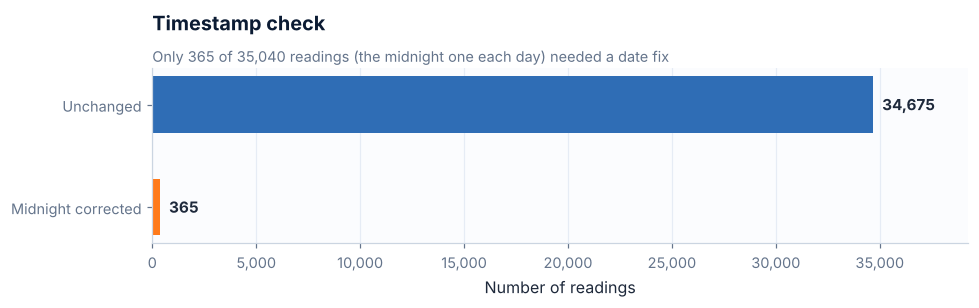

In [13]:
labels = ["Unchanged", "Midnight corrected"]
counts = [len(df) - changed, changed]

fig, ax = plt.subplots(figsize=(9, 2.9))
bars = ax.barh(labels, counts, color=[BLUE, ORANGE], height=.55)
ax.bar_label(bars, labels=[f"{count:,}" for count in counts], padding=6, fontweight="bold", color=C["ink"])
ax.invert_yaxis()
ax.set_xlim(0, len(df) * 1.12)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_xlabel("Number of readings")
ax.grid(axis="y", visible=False)
style_title(ax, "Timestamp check", f"Only {changed} of {len(df):,} readings (the midnight one each day) needed a date fix")
finish(fig, "01_timestamp_check")

---
## Timestamp Correction Visualization

- The chart compares unchanged timestamps with midnight-corrected timestamps.
- **34,675 timestamps** remained unchanged after reconstruction.
- **365 timestamps** were corrected to fix midnight errors.
- Corrected timestamps represent approximately 1.04% of all readings.
- Unchanged timestamps represent approximately 98.96% of all readings.
- Exactly one midnight timestamp was corrected per day.
- **This confirms timestamp corrections were limited to midnight mislabeling**.
---

<div style="background:linear-gradient(90deg,#0B1B33,#1d4f91);padding:16px 22px;border-radius:12px;color:#fff;margin:26px 0 8px;font-family:system-ui,Segoe UI,Roboto,sans-serif"><div style="font-size:11px;letter-spacing:.16em;text-transform:uppercase;color:#FFB347;font-weight:600">Part 2</div><div style="font-size:22px;font-weight:700;margin:2px 0 4px;color:#fff">Executive dashboard</div><div style="font-size:13.5px;color:#d6e4f7">The whole year at a glance: headline numbers first, then a one-page picture.</div></div>

### Headline numbers

In [14]:
daily = df.groupby("interval_day")["Usage_kWh"].sum()
is_wd = daily.index.dayofweek < 5
lag_pf_col = "Lagging_Current_Power_Factor"
peak_row = df.loc[df["Usage_kWh"].idxmax()]

kpi_cards([
    ("Total energy", f"{df['Usage_kWh'].sum() / 1000:,.0f} MWh", f"{df['Usage_kWh'].mean():.1f} kWh per 15-min reading", BLUE),
    ("CO₂ emitted", f"{df['CO2(tCO2)'].sum():,.0f} t", "from the dataset's CO₂ column", TEAL),
    ("Peak demand", f"{df['Usage_kWh'].max():.0f} kWh", f"{peak_row['timestamp']:%d %b, %H:%M}", ROSE),
    ("Load factor", f"{100 * df['Usage_kWh'].mean() / df['Usage_kWh'].max():.1f}%", "average ÷ peak demand", VIOLET),
    ("Weekday vs weekend", f"{daily[is_wd].mean() / daily[~is_wd].mean():.1f}×", "more energy per day on weekdays", ORANGE),
    ("Poor power factor", f"{100 * (df[lag_pf_col] < 90).mean():.0f}%", "of readings below 90% lagging", GOLD),
])
kpi_cards([
    ("Readings", f"{len(df):,}", "one every 15 minutes", BLUE),
    ("Days covered", f"{daily.shape[0]}", "96 readings every day", TEAL),
    ("Missing values", f"{int(df.isna().sum().sum())}", "across all columns", C["sky"]),
    ("Timestamps repaired", f"{changed}", "midnight readings re-dated", ORANGE),
])

### The year on one page

Six panels: daily usage, energy by load type, a typical day, month by month with CO₂, and the power-factor distribution.

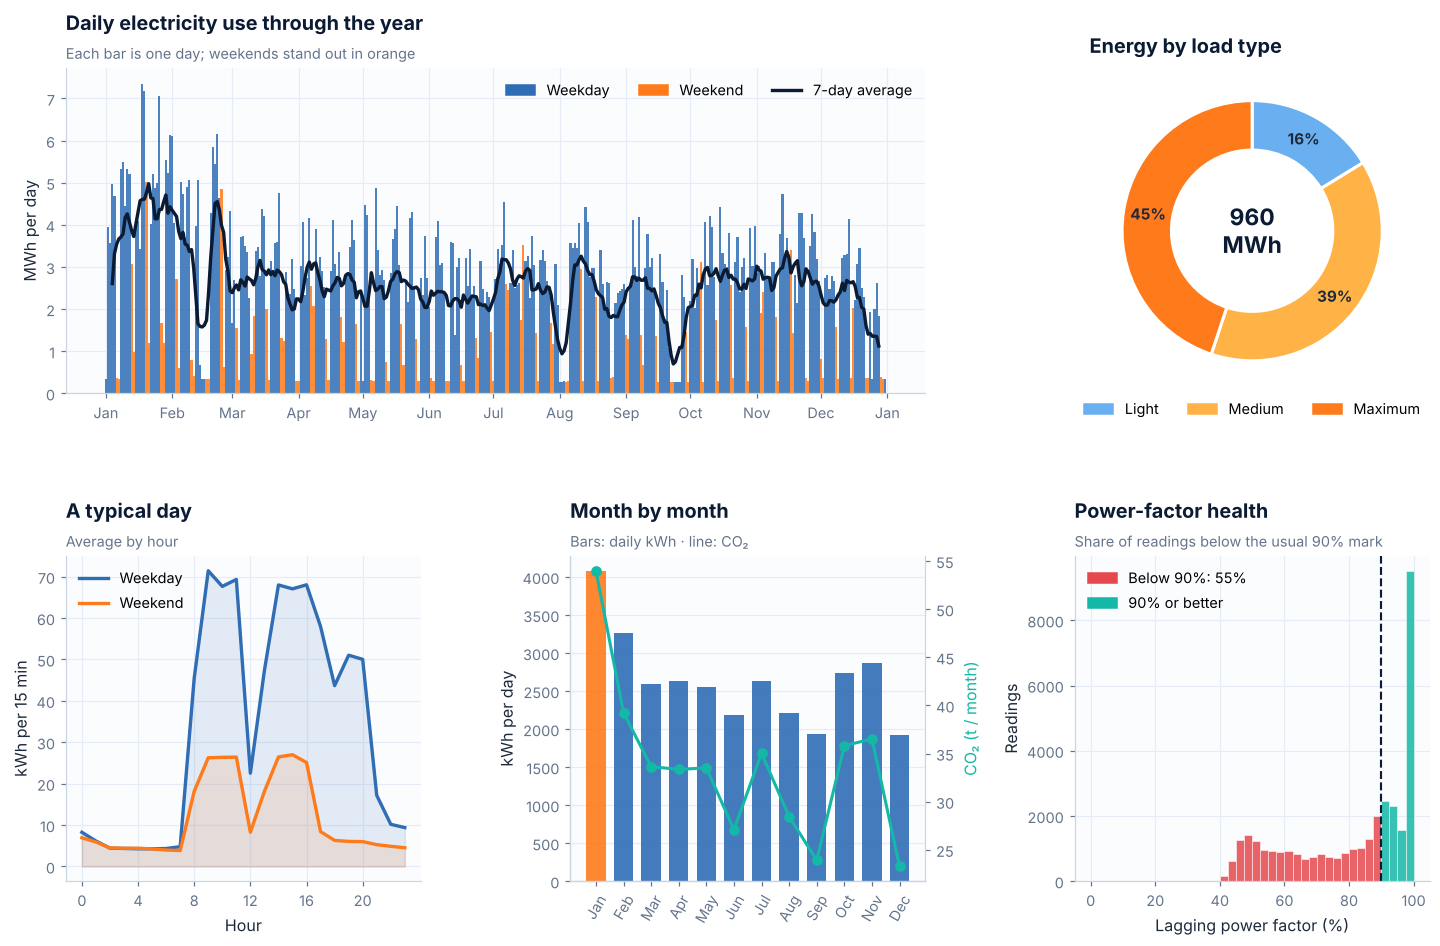

In [15]:
fig = plt.figure(figsize=(16, 9.6))
gs = fig.add_gridspec(2, 3, hspace=.5, wspace=.42)

# A - the whole year, one bar per day
ax = fig.add_subplot(gs[0, :2])
ax.bar(daily.index, daily.values / 1000, color=np.where(is_wd, BLUE, ORANGE), width=1.0, alpha=.85)
roll = daily.rolling(7, center=True).mean() / 1000
ax.plot(roll.index, roll.values, color=C["navy"], lw=2.2)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_ylabel("MWh per day")
ax.legend(handles=[Patch(color=BLUE, label="Weekday"), Patch(color=ORANGE, label="Weekend"),
                   plt.Line2D([], [], color=C["navy"], lw=2.2, label="7-day average")], ncol=3, loc="upper right")
style_title(ax, "Daily electricity use through the year", "Each bar is one day; weekends stand out in orange")

# B - donut of energy by load type
ax = fig.add_subplot(gs[0, 2])
energy_by_load = df.groupby("Load_Type")["Usage_kWh"].sum().reindex(LOAD_ORDER)
ax.pie(energy_by_load, colors=[LOAD_COLORS[k] for k in LOAD_ORDER], startangle=90, counterclock=False,
       wedgeprops=dict(width=.38, edgecolor="white", linewidth=2),
       autopct=lambda p: f"{p:.0f}%", pctdistance=.81, textprops=dict(fontsize=10, fontweight="bold", color=C["ink"]))
ax.text(0, 0, f"{energy_by_load.sum() / 1000:,.0f}\nMWh", ha="center", va="center", fontsize=15, fontweight="bold", color=C["navy"])
ax.legend(handles=[Patch(color=LOAD_COLORS[k], label=l) for k, l in zip(LOAD_ORDER, LOAD_LABELS)],
          loc="upper center", bbox_to_anchor=(.5, .02), ncol=3)
ax.grid(False)
style_title(ax, "Energy by load type")

# C - hourly profile weekday vs weekend
ax = fig.add_subplot(gs[1, 0])
hp = df.groupby(["is_weekday", "hour"])["Usage_kWh"].mean().unstack(0)
ax.plot(hp.index, hp[1], color=BLUE, label="Weekday")
ax.fill_between(hp.index, hp[1], color=BLUE, alpha=.12)
ax.plot(hp.index, hp[0], color=ORANGE, label="Weekend")
ax.fill_between(hp.index, hp[0], color=ORANGE, alpha=.12)
ax.set_xticks(range(0, 24, 4))
ax.set_xlabel("Hour")
ax.set_ylabel("kWh per 15 min")
ax.legend()
style_title(ax, "A typical day", "Average by hour")

# D - month by month with CO2
ax = fig.add_subplot(gs[1, 1])
bm = daily.groupby(daily.index.month).mean()
co2m = df.groupby(df["interval_day"].dt.month)["CO2(tCO2)"].sum()
ax.bar(MONTH_NAMES, bm.values, color=[ORANGE if v == bm.max() else BLUE for v in bm.values], width=.7, alpha=.9)
ax.set_ylabel("kWh per day")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="x", visible=False)
ax2 = ax.twinx()
ax2.plot(MONTH_NAMES, co2m.values, color=TEAL, marker="o", lw=2)
ax2.set_ylabel("CO₂ (t / month)", color=TEAL)
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax2.spines["right"].set_color("#CBD5E1")
style_title(ax, "Month by month", "Bars: daily kWh · line: CO₂")

# E - power factor distribution
ax = fig.add_subplot(gs[1, 2])
n, bins, patches = ax.hist(df[lag_pf_col], bins=40, edgecolor="white", linewidth=.4)
for left, patch in zip(bins[:-1], patches):
    patch.set_facecolor(ROSE if left < 90 else TEAL)
    patch.set_alpha(.85)
ax.axvline(90, color=C["navy"], ls="--", lw=1.4)
ax.set_xlabel("Lagging power factor (%)")
ax.set_ylabel("Readings")
ax.legend(handles=[Patch(color=ROSE, label=f"Below 90%: {100 * (df[lag_pf_col] < 90).mean():.0f}%"),
                   Patch(color=TEAL, label="90% or better")], loc="upper left")
style_title(ax, "Power-factor health", "Share of readings below the usual 90% mark")

finish(fig, "02_executive_dashboard")

<div style="background:linear-gradient(90deg,#0B1B33,#2F6DB5);padding:16px 22px;border-radius:12px;color:#fff;margin:26px 0 8px;font-family:system-ui,Segoe UI,Roboto,sans-serif"><div style="font-size:11px;letter-spacing:.16em;text-transform:uppercase;color:#FFB347;font-weight:600">Part 3</div><div style="font-size:22px;font-weight:700;margin:2px 0 4px;color:#fff">Usage patterns</div><div style="font-size:13.5px;color:#d6e4f7">Hour, weekday and month rhythms, a statistical test of weekday vs weekend (H1), and a deep dive into peaks and cycles.</div></div>

## Next: Electricity Consumption by Hour, Day, and Month

- Analyze hourly average consumption to identify high-usage hours.
- Aggregate readings into daily totals to examine consumption patterns.
- Compare daily consumption across different weekdays.
- Analyze monthly totals to identify seasonal consumption variations.
- These patterns help identify peak demand periods and usage trends.

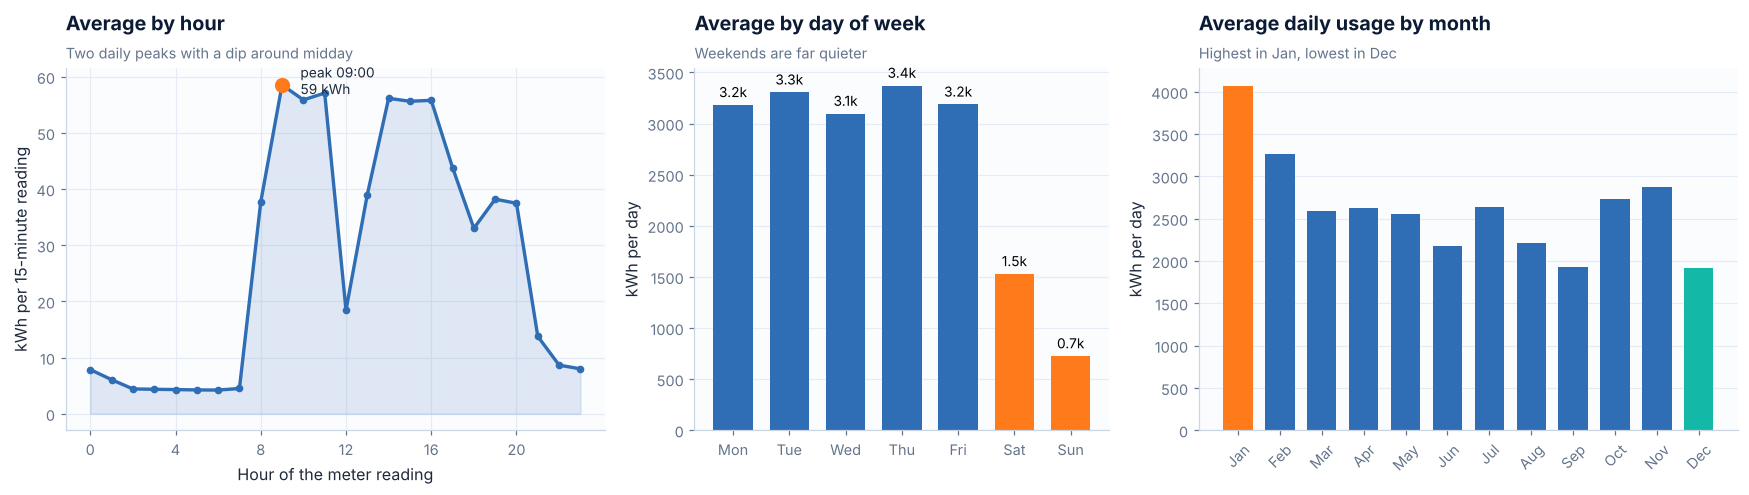

In [16]:
hourly = df.groupby("hour")["Usage_kWh"].mean()

daily = df.groupby("interval_day")["Usage_kWh"].sum()
by_day = daily.groupby(daily.index.dayofweek).mean()
by_month = daily.groupby(daily.index.month).mean()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.3, 1, 1.3]})

ax = axes[0]
ax.plot(hourly.index, hourly.values, color=BLUE, marker="o", ms=4)
ax.fill_between(hourly.index, hourly.values, color=BLUE, alpha=.14)
peak_h = int(hourly.idxmax())
ax.scatter([peak_h], [hourly.max()], color=ORANGE, s=80, zorder=3)
ax.annotate(f"peak {peak_h:02d}:00\n{hourly.max():.0f} kWh", (peak_h, hourly.max()),
            textcoords="offset points", xytext=(12, -6), fontsize=9, color=C["ink"])
ax.set_xticks(range(0, 24, 4))
ax.set_xlabel("Hour of the meter reading")
ax.set_ylabel("kWh per 15-minute reading")
style_title(ax, "Average by hour", "Two daily peaks with a dip around midday")

ax = axes[1]
bars = ax.bar(DAY_NAMES, by_day.values, color=[BLUE] * 5 + [ORANGE] * 2, width=.7)
ax.bar_label(bars, labels=[f"{v / 1000:.1f}k" for v in by_day.values], padding=3, fontsize=9)
ax.set_ylabel("kWh per day")
ax.grid(axis="x", visible=False)
style_title(ax, "Average by day of week", "Weekends are far quieter")

ax = axes[2]
month_colors = [ORANGE if v == by_month.max() else (TEAL if v == by_month.min() else BLUE) for v in by_month.values]
ax.bar(MONTH_NAMES, by_month.values, color=month_colors, width=.7)
ax.set_ylabel("kWh per day")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="x", visible=False)
style_title(ax, "Average daily usage by month",
            f"Highest in {MONTH_NAMES[int(by_month.idxmax()) - 1]}, lowest in {MONTH_NAMES[int(by_month.idxmin()) - 1]}")
finish(fig, "04_hour_day_month")

---
## Electricity Consumption Patterns

### Average Consumption by Hour
- Consumption remains low during **early morning hours.**
- Usage **rises sharply around 8:00 AM.**
- **Peak consumption occurs between 9:00 AM and 11:00 AM.**
- Consumption drops sharply around **noon**.
- **Usage rises again** during afternoon operating hours.
- Evening consumption gradually declines after production hours.

### Average Consumption by Day of Week
- **Weekday consumption remains consistently high.**
- **Thursday** shows the highest average daily consumption.
- **Wednesday** shows relatively lower weekday consumption.
- **Weekend consumption drops substantially compared to weekdays.**
- **Sunday has the lowest** average daily consumption.
- This suggests **reduced industrial activity during weekends.**

### Average Daily Consumption by Month
- **January** shows the highest average daily consumption.
- Consumption **drops** considerably **after January.**
- **May and September** show **relatively lower** consumption.
- Usage increases again during **October and November.**
- **December consumption declines** compared to November.
- Monthly variations may reflect changing operational or seasonal conditions.

### Key Observations
- **Electricity consumption** follows a **strong daily operating pattern.**
- **Weekdays consume** considerably **more electricity than weekends.**
- Monthly consumption varies noticeably throughout the year.
- These patterns can support demand forecasting and energy optimization.
---

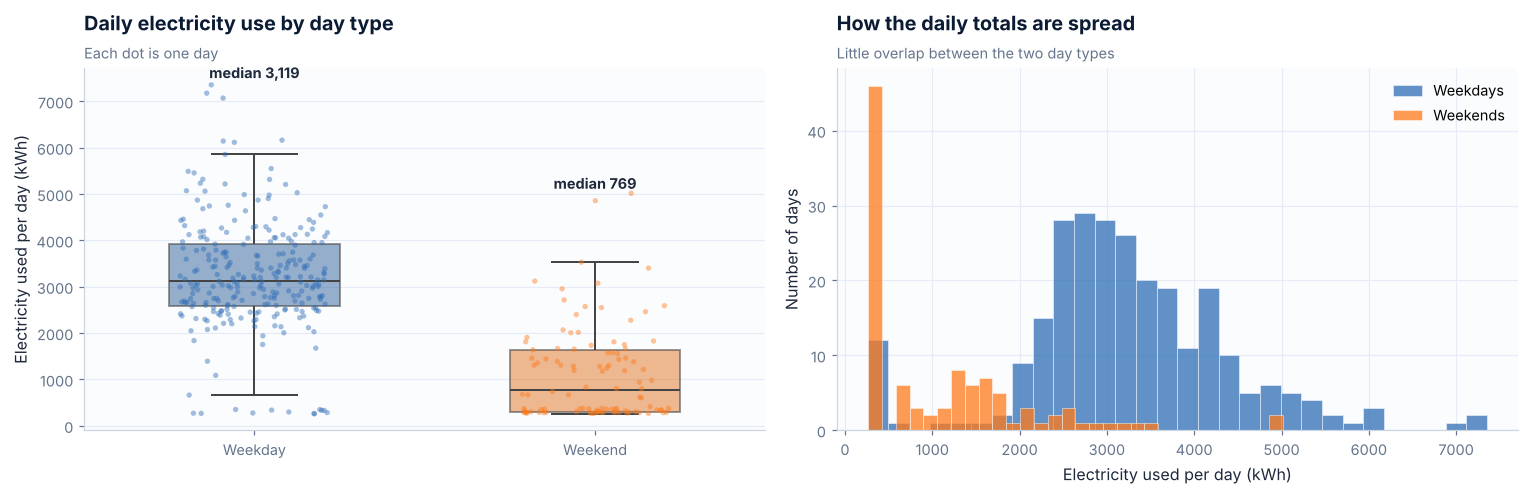

In [17]:
weekday_kwh = daily[daily.index.dayofweek < 5]
weekend_kwh = daily[daily.index.dayofweek >= 5]
day_type_df = pd.DataFrame({"kwh": daily.values,
                            "type": np.where(daily.index.dayofweek < 5, "Weekday", "Weekend")})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axes[0]
sns.boxplot(data=day_type_df, x="type", y="kwh", hue="type", palette={"Weekday": BLUE, "Weekend": ORANGE},
            width=.5, fliersize=0, linewidth=1.3, legend=False, ax=ax, boxprops=dict(alpha=.55))
sns.stripplot(data=day_type_df, x="type", y="kwh", hue="type", palette={"Weekday": BLUE, "Weekend": ORANGE},
              size=3.5, alpha=.45, jitter=.22, legend=False, ax=ax)
for i, g in enumerate([weekday_kwh, weekend_kwh]):
    ax.text(i, g.max() * 1.02, f"median {g.median():,.0f}", ha="center", fontsize=9.5, fontweight="bold", color=C["ink"])
ax.set_xlabel("")
ax.set_ylabel("Electricity used per day (kWh)")
ax.grid(axis="x", visible=False)
style_title(ax, "Daily electricity use by day type", "Each dot is one day")

ax = axes[1]
ax.hist(weekday_kwh, bins=30, color=BLUE, alpha=.75, label="Weekdays", edgecolor="white", linewidth=.4)
ax.hist(weekend_kwh, bins=30, color=ORANGE, alpha=.75, label="Weekends", edgecolor="white", linewidth=.4)
ax.set_xlabel("Electricity used per day (kWh)")
ax.set_ylabel("Number of days")
ax.legend()
style_title(ax, "How the daily totals are spread", "Little overlap between the two day types")
finish(fig, "05_daily_by_day_type")

---
## Daily Electricity Consumption by Day Type

- **Weekdays** have substantially higher daily consumption than weekends.
- **Weekday median consumption** is approximately **3,100 kWh**.
- **Weekend median consumption** is approximately **800 kWh.**
- Weekday consumption shows a wider overall range.
- Both groups contain outliers representing unusually high or low consumption.
- Weekend consumption is generally lower and more concentrated.
- Reduced weekend consumption likely reflects lower plant operating activity.
- The difference highlights the impact of operating schedules on energy demand.
---

## Next: Test H1 — Weekday vs. Weekend Electricity Consumption

- The Mann–Whitney U test compares weekday and weekend daily consumption.
- Each daily total represents one independent observation in the test.
- Aggregating 96 readings prevents treating within-day readings as independent observations.
- The test evaluates whether weekday consumption tends to exceed weekend consumption.
- The p-value indicates whether the observed difference is statistically significant.
- The ratio of averages quantifies the relative consumption difference.
- Rank-biserial effect size measures the separation between the two groups.
- An effect size of 1 indicates every weekday exceeds every weekend.
- These measures assess statistical significance and practical difference in consumption.

In [18]:
from scipy.stats import mannwhitneyu

weekday = daily[daily.index.dayofweek < 5]
weekend = daily[daily.index.dayofweek >= 5]

u_stat, p_value = mannwhitneyu(
    weekday, weekend, alternative="greater", method="asymptotic"
)
rank_biserial = 2 * u_stat / (len(weekday) * len(weekend)) - 1

print(f"Weekdays ({len(weekday)} days): {weekday.mean():,.0f} kWh/day")
print(f"Weekends ({len(weekend)} days): {weekend.mean():,.0f} kWh/day")
print(f"Weekday / weekend ratio: {weekday.mean() / weekend.mean():.2f}")
print(f"Mann–Whitney U: {u_stat:,.0f}")
print(f"p-value: {p_value:.2e}")
print(f"Rank-biserial effect size: {rank_biserial:.2f}")

Weekdays (261 days): 3,228 kWh/day
Weekends (104 days): 1,126 kWh/day
Weekday / weekend ratio: 2.87
Mann–Whitney U: 24,571
p-value: 6.13e-34
Rank-biserial effect size: 0.81


---
## Test H1 — Weekday vs. Weekend Electricity Consumption

### Preparing the Groups
- `daily.index.dayofweek` extracts weekday numbers from daily dates.
- Weekdays are Monday–Friday, represented by values below 5.
- Weekends are Saturday–Sunday, represented by values 5 and 6.
- `weekday` and `weekend` contain daily totals for each group.
- Each observation represents one complete day's electricity consumption.

### Mann–Whitney U Test
- `mannwhitneyu()` compares weekday and weekend consumption distributions.
- `alternative="greater"` tests whether weekday values tend to be higher.
- `method="asymptotic"` approximates the p-value using a normal distribution.
- `u_stat` stores the calculated Mann–Whitney U statistic.
- `p_value` measures evidence against the null hypothesis.
- A very small p-value indicates a statistically significant difference.

### Rank-Biserial Effect Size
- Rank-biserial correlation measures separation between the two consumption groups.
- `2 * u_stat / (len(weekday) * len(weekend)) - 1` calculates the effect size.
- Values approach 1 when weekdays consistently exceed weekends.
- A value of 0.81 indicates strong separation between the groups.

### Results
- Weekdays contain **261 days**, averaging **3,228 kWh/day**.
- Weekends contain **104 days**, averaging **1,126 kWh/day**.
- Weekday consumption is approximately **2.87 times** weekend consumption.
- Mann–Whitney U statistic is **24,571**.
- The p-value is **6.13 × 10⁻³⁴** (less than 0.001).
- Rank-biserial effect size is **0.81**, indicating strong separation.

### Inference
- Weekday electricity consumption is significantly higher than weekend consumption.
- The difference is statistically significant, with a **very small p-value.**
- Weekdays consume approximately **2.9 times more electricity than weekends.**
- **H1 is supported for this plant's 2018 observations.**
- Meter readings establish consumption patterns, not their underlying causes.
---

## Deep dive: more ways to look at the rhythm of the plant

The next charts look at the same data from new angles: a **hour × weekday heat-map**, a **calendar view** of the whole year, **peak-demand** analysis, the **distribution** of usage per load type, **correlations**, and **autocorrelation** (how strongly today repeats yesterday and last week). These are what justify the lag features used for forecasting later.

### Heat-map: hour × weekday

Darker orange = more electricity. Read across a row for a day's shape, down a column for one hour across the week.

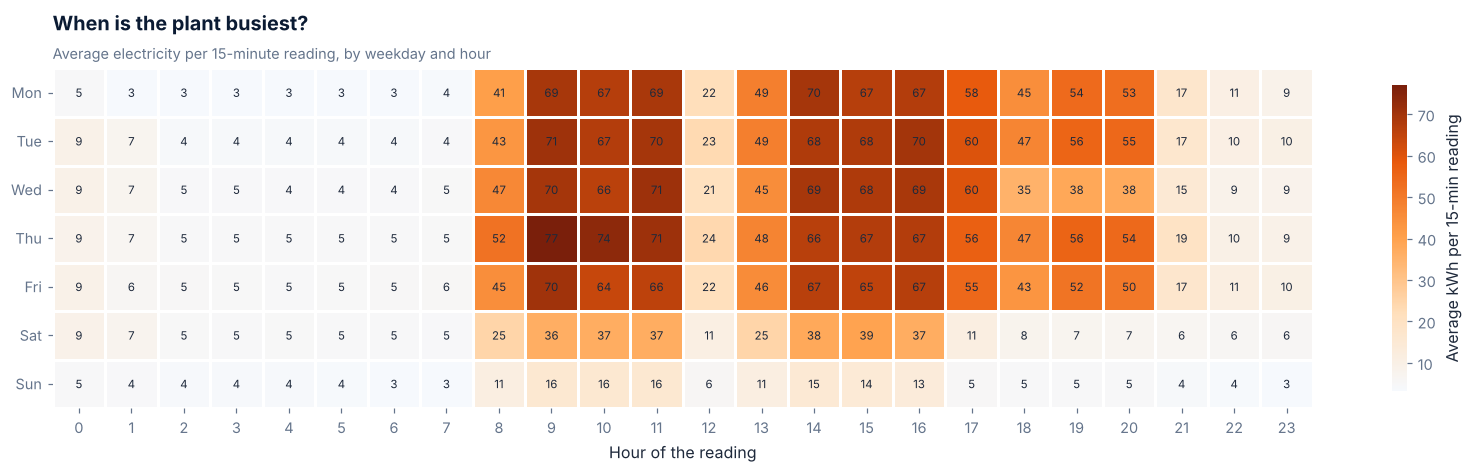

### 🔎 What we found

- The busiest slot of the week is **Thu around 09:00** at about **77 kWh** per reading.
- On weekdays the plant is quietest around **05:00**; the **midday dip** shows as a pale stripe between the two production peaks.
- **Saturday and Sunday** stay pale all day, so a weekend behaves like a different operating regime.

In [19]:
heat = df.pivot_table(index="day_of_week", columns="hour", values="Usage_kWh", aggfunc="mean")
heat.index = DAY_NAMES

fig, ax = plt.subplots(figsize=(15, 4.4))
sns.heatmap(heat, cmap=CMAP_HEAT, ax=ax, linewidths=.8, linecolor="white", annot=True, fmt=".0f",
            annot_kws={"size": 7.5, "color": C["ink"]}, cbar_kws={"label": "Average kWh per 15-min reading", "shrink": .9})
ax.set_xlabel("Hour of the reading")
ax.set_ylabel("")
ax.grid(False)
ax.tick_params(axis="y", rotation=0)
style_title(ax, "When is the plant busiest?", "Average electricity per 15-minute reading, by weekday and hour")
finish(fig, "03_hour_weekday_heatmap")

busiest_day, busiest_hour = heat.stack().idxmax()
quiet_hour = int(heat.loc[DAY_NAMES[:5]].mean().idxmin())
finding(f"""- The busiest slot of the week is **{busiest_day} around {int(busiest_hour):02d}:00** at about **{heat.stack().max():.0f} kWh** per reading.
- On weekdays the plant is quietest around **{quiet_hour:02d}:00**; the **midday dip** shows as a pale stripe between the two production peaks.
- **Saturday and Sunday** stay pale all day, so a weekend behaves like a different operating regime.""")

### Calendar view

Each square is one day of the year, coloured by total energy.

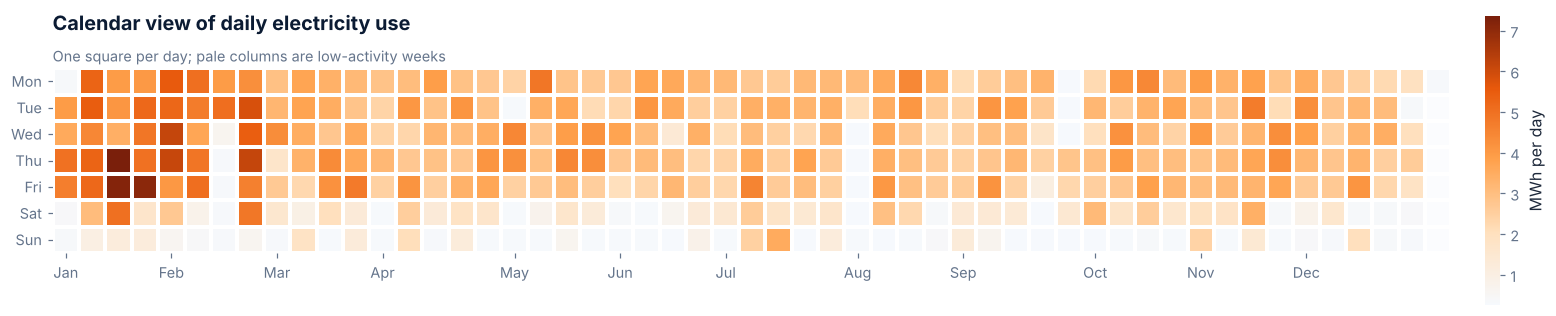

### 🔎 What we found

- The highest day was **18 Jan** (7,354 kWh) and the lowest **26 Sep** (259 kWh).
- **64 days** used less than a quarter of the median day. These are mostly weekends, but any weekday in that list is worth checking for a shutdown or an outage.
- Early-year weeks are the darkest, matching the winter peak seen in the monthly chart.

In [20]:
cal = daily.to_frame("kwh")
offset = cal.index[0].dayofweek
cal["week"] = (cal.index.dayofyear - 1 + offset) // 7
cal["dow"] = cal.index.dayofweek
grid = (cal.pivot(index="dow", columns="week", values="kwh") / 1000)
grid.index = DAY_NAMES

fig, ax = plt.subplots(figsize=(16, 3.8))
sns.heatmap(grid, cmap=CMAP_HEAT, ax=ax, linewidths=1.4, linecolor="white", square=True,
            cbar_kws={"label": "MWh per day", "shrink": .75, "pad": .02})
year0 = cal.index[0].year
month_weeks = [(pd.Timestamp(year0, m, 1).dayofyear - 1 + offset) // 7 + .5 for m in range(1, 13)]
ax.set_xticks(month_weeks)
ax.set_xticklabels(MONTH_NAMES, rotation=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.grid(False)
ax.tick_params(axis="y", rotation=0)
style_title(ax, "Calendar view of daily electricity use", "One square per day; pale columns are low-activity weeks")
finish(fig, "03b_calendar_heatmap")

low_days = daily[daily < 0.25 * daily.median()]
finding(f"""- The highest day was **{daily.idxmax():%d %b}** ({daily.max():,.0f} kWh) and the lowest **{daily.idxmin():%d %b}** ({daily.min():,.0f} kWh).
- **{len(low_days)} days** used less than a quarter of the median day. These are mostly weekends, but any weekday in that list is worth checking for a shutdown or an outage.
- Early-year weeks are the darkest, matching the winter peak seen in the monthly chart.""")

### Peak demand

The load-duration curve shows how often demand reaches each level; peaks matter because many tariffs charge for the highest demand.

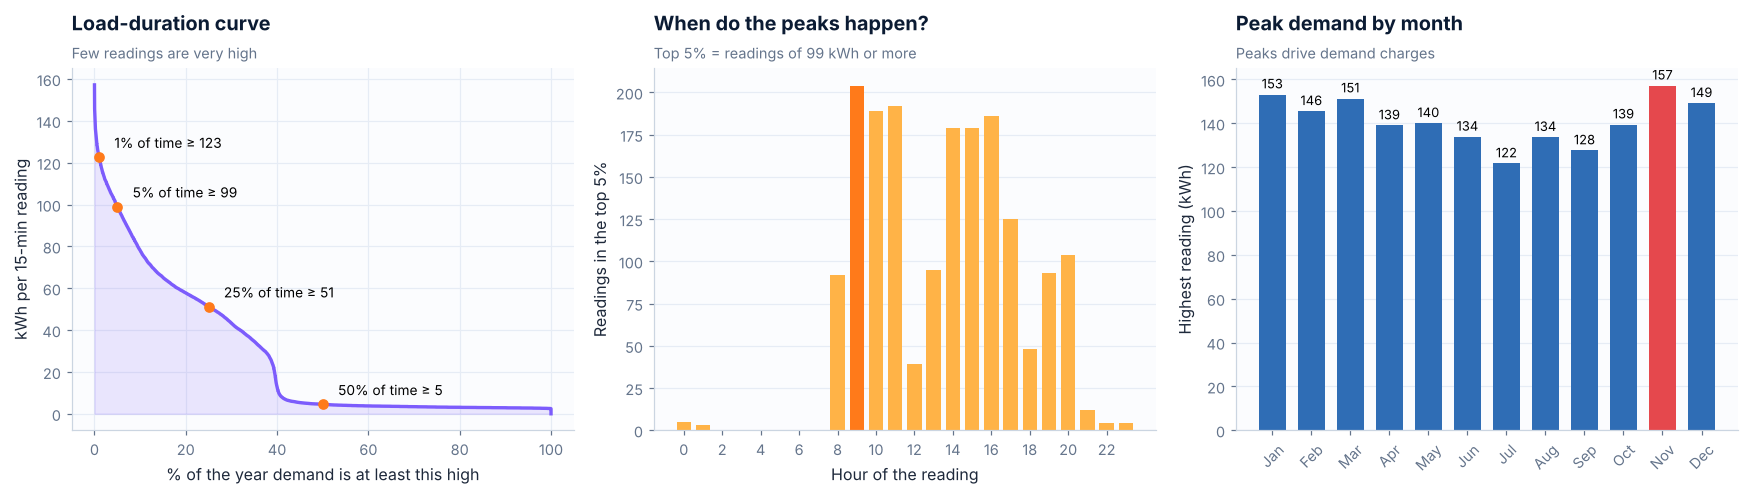

### 🔎 What we found

- The **top 5% of readings** carry **21% of all energy**, so a small number of intervals dominates the load.
- Peaks cluster around **09:00**; the highest single reading was **157 kWh**, in **Nov**.
- Peak shaving (staggering furnace or motor start-ups) is therefore more valuable than trimming average load.

In [21]:
usage_sorted = np.sort(df["Usage_kWh"].to_numpy())[::-1]
pct = np.arange(1, len(usage_sorted) + 1) / len(usage_sorted) * 100
top5_thr = df["Usage_kWh"].quantile(.95)
top5 = df[df["Usage_kWh"] >= top5_thr]
top5_share = 100 * top5["Usage_kWh"].sum() / df["Usage_kWh"].sum()
monthly_peak = df.groupby(df["interval_day"].dt.month)["Usage_kWh"].max()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

ax = axes[0]
ax.plot(pct, usage_sorted, color=VIOLET)
ax.fill_between(pct, usage_sorted, color=VIOLET, alpha=.14)
for p_ in (1, 5, 25, 50):
    v = np.quantile(usage_sorted, 1 - p_ / 100)
    ax.scatter([p_], [v], color=ORANGE, zorder=3)
    ax.annotate(f"{p_}% of time ≥ {v:.0f}", (p_, v), textcoords="offset points", xytext=(10, 6), fontsize=9)
ax.set_xlabel("% of the year demand is at least this high")
ax.set_ylabel("kWh per 15-min reading")
style_title(ax, "Load-duration curve", "Few readings are very high")

ax = axes[1]
hours_top = top5["hour"].value_counts().reindex(range(24), fill_value=0)
ax.bar(hours_top.index, hours_top.values, color=[ORANGE if v == hours_top.max() else C["gold"] for v in hours_top.values], width=.75)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of the reading")
ax.set_ylabel("Readings in the top 5%")
ax.grid(axis="x", visible=False)
style_title(ax, "When do the peaks happen?", f"Top 5% = readings of {top5_thr:.0f} kWh or more")

ax = axes[2]
bars = ax.bar(MONTH_NAMES, monthly_peak.values, color=[ROSE if v == monthly_peak.max() else BLUE for v in monthly_peak.values], width=.7)
ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=8.5)
ax.set_ylabel("Highest reading (kWh)")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="x", visible=False)
style_title(ax, "Peak demand by month", "Peaks drive demand charges")
finish(fig, "03c_peak_analysis")

finding(f"""- The **top 5% of readings** carry **{top5_share:.0f}% of all energy**, so a small number of intervals dominates the load.
- Peaks cluster around **{int(hours_top.idxmax()):02d}:00**; the highest single reading was **{df['Usage_kWh'].max():.0f} kWh**, in **{MONTH_NAMES[int(monthly_peak.idxmax()) - 1]}**.
- Peak shaving (staggering furnace or motor start-ups) is therefore more valuable than trimming average load.""")

### Distribution of usage

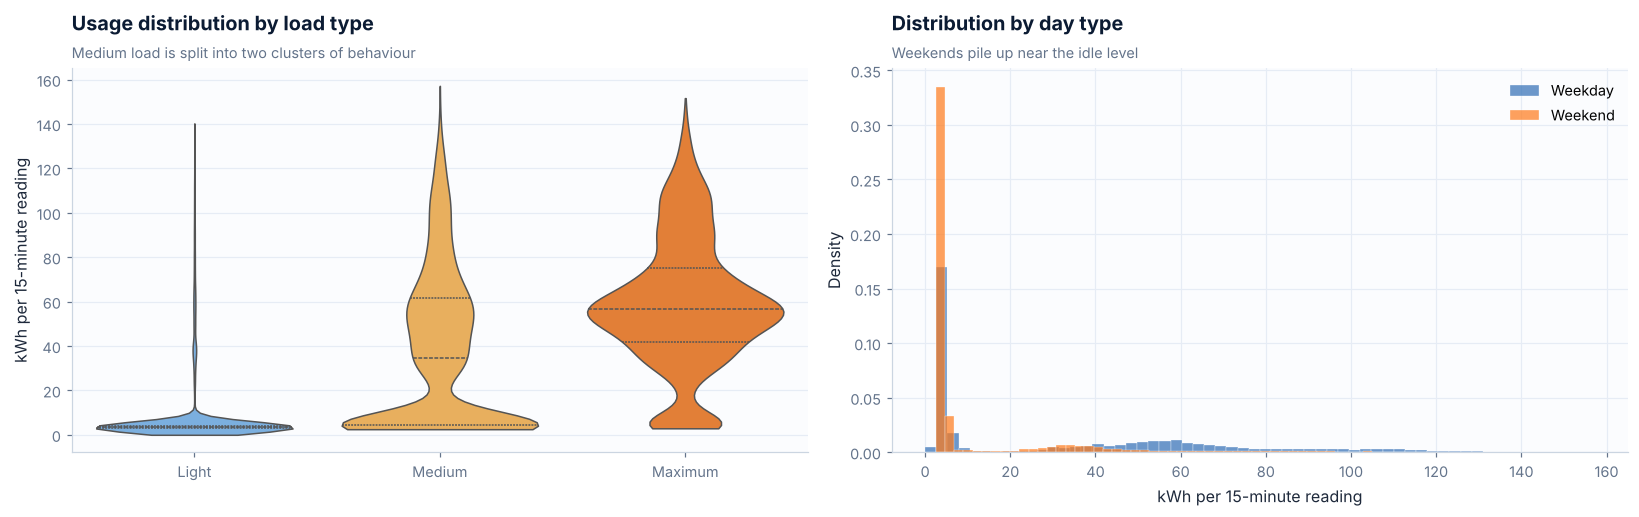

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

ax = axes[0]
sns.violinplot(data=df, x="Load_Type", y="Usage_kWh", hue="Load_Type", order=LOAD_ORDER, hue_order=LOAD_ORDER,
               palette=LOAD_COLORS, inner="quartile", cut=0, linewidth=1, legend=False, ax=ax)
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(LOAD_LABELS)
ax.set_xlabel("")
ax.set_ylabel("kWh per 15-minute reading")
ax.grid(axis="x", visible=False)
style_title(ax, "Usage distribution by load type", "Medium load is split into two clusters of behaviour")

ax = axes[1]
ax.hist(df.loc[df["is_weekday"] == 1, "Usage_kWh"], bins=60, density=True, color=BLUE, alpha=.7, label="Weekday", edgecolor="white", linewidth=.3)
ax.hist(df.loc[df["is_weekday"] == 0, "Usage_kWh"], bins=60, density=True, color=ORANGE, alpha=.7, label="Weekend", edgecolor="white", linewidth=.3)
ax.set_xlabel("kWh per 15-minute reading")
ax.set_ylabel("Density")
ax.legend()
style_title(ax, "Distribution by day type", "Weekends pile up near the idle level")
finish(fig, "03d_distributions")

### Correlation map

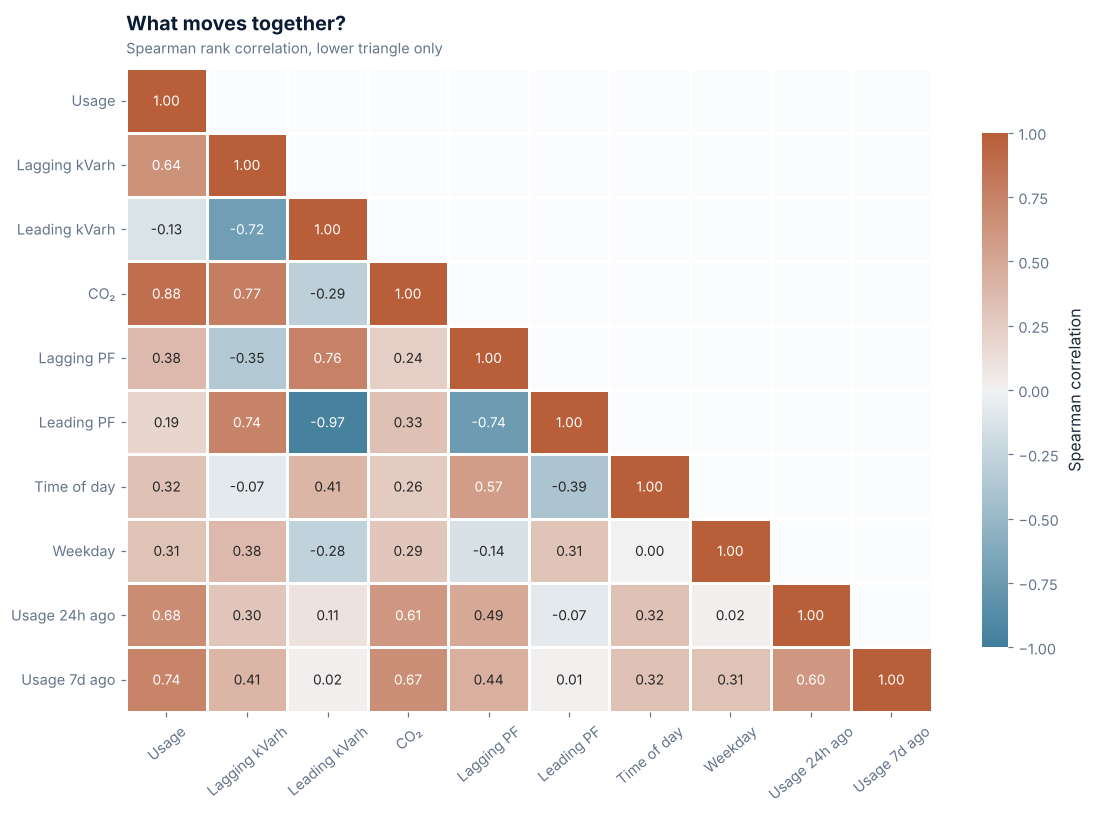

### 🔎 What we found

- Usage is most strongly tied to **CO₂** (+0.88) and **Usage 7d ago** (+0.74).
- **Usage 24h ago** (+0.68) and **7d ago** (+0.74) carry real signal, which is why the forecasting models use them.
- **CO₂** is almost a copy of usage (+0.88), so it adds no independent information.

In [23]:
corr_cols = {
    "Usage_kWh": "Usage", "Lagging_Current_Reactive.Power_kVarh": "Lagging kVarh",
    "Leading_Current_Reactive_Power_kVarh": "Leading kVarh", "CO2(tCO2)": "CO₂",
    "Lagging_Current_Power_Factor": "Lagging PF", "Leading_Current_Power_Factor": "Leading PF",
    "NSM": "Time of day", "is_weekday": "Weekday", "usage_lag_24h": "Usage 24h ago", "usage_lag_7d": "Usage 7d ago",
}
corr = df[list(corr_cols)].rename(columns=corr_cols).corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10.5, 7.5))
sns.heatmap(corr, mask=mask, cmap=CMAP_DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", ax=ax,
            linewidths=.8, linecolor="white", annot_kws={"size": 9}, cbar_kws={"shrink": .8, "label": "Spearman correlation"})
ax.grid(False)
ax.tick_params(axis="x", rotation=40)
style_title(ax, "What moves together?", "Spearman rank correlation, lower triangle only")
finish(fig, "03e_correlation")

pairs = corr["Usage"].drop("Usage").sort_values(key=lambda s: s.abs(), ascending=False)
finding(f"""- Usage is most strongly tied to **{pairs.index[0]}** ({pairs.iloc[0]:+.2f}) and **{pairs.index[1]}** ({pairs.iloc[1]:+.2f}).
- **Usage 24h ago** ({corr.loc['Usage', 'Usage 24h ago']:+.2f}) and **7d ago** ({corr.loc['Usage', 'Usage 7d ago']:+.2f}) carry real signal, which is why the forecasting models use them.
- **CO₂** is almost a copy of usage ({corr.loc['Usage', 'CO₂']:+.2f}), so it adds no independent information.""")

### Usage versus reactive energy and power factor

Each hexagon groups many readings; darker means more readings.

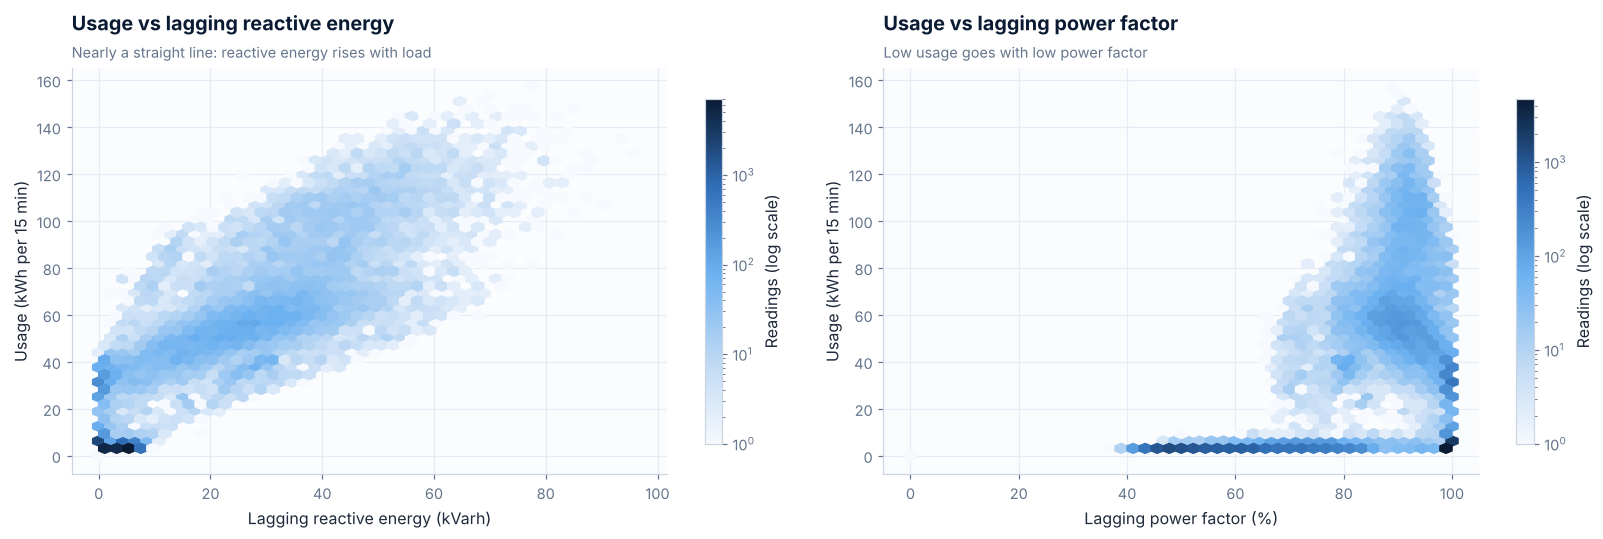

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
pairs_ = [("Lagging_Current_Reactive.Power_kVarh", "Lagging reactive energy (kVarh)"),
          ("Lagging_Current_Power_Factor", "Lagging power factor (%)")]
for ax, (col, label) in zip(axes, pairs_):
    hb = ax.hexbin(df[col], df["Usage_kWh"], gridsize=45, bins="log", cmap=CMAP_COOL, mincnt=1)
    fig.colorbar(hb, ax=ax, label="Readings (log scale)", shrink=.85)
    ax.set_xlabel(label)
    ax.set_ylabel("Usage (kWh per 15 min)")
style_title(axes[0], "Usage vs lagging reactive energy", "Nearly a straight line: reactive energy rises with load")
style_title(axes[1], "Usage vs lagging power factor", "Low usage goes with low power factor")
finish(fig, "03f_hexbin_relationships")

### Autocorrelation: does the plant repeat itself?

Autocorrelation compares the series with a delayed copy of itself. High values at 1 day and 7 days mean yesterday and last week are good clues.

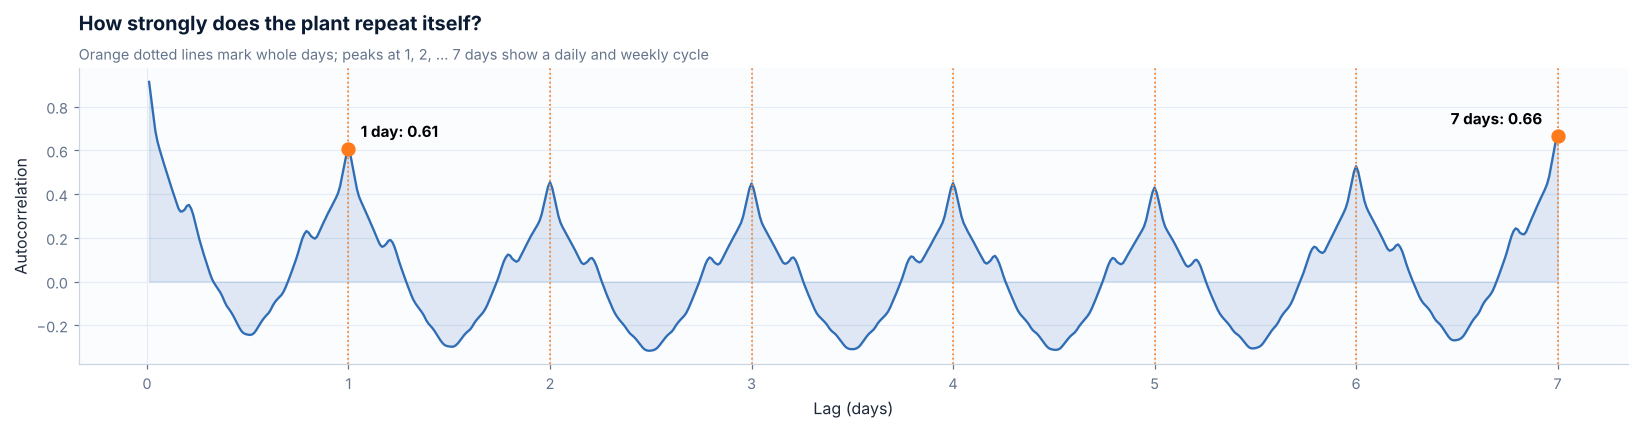

### 🔎 What we found

- Usage correlates **0.61** with the same time **yesterday** and **0.66** with the same time **last week**.
- The repeating bumps confirm a strong **daily cycle**, and the weekly pattern explains why "same time last week" is the strongest simple guess for next-day forecasts.

In [25]:
x = df["Usage_kWh"].to_numpy()
x = x - x.mean()
denom = float(np.dot(x, x))
max_lag = 7 * 96
acf = np.array([np.dot(x[:-k], x[k:]) / denom for k in range(1, max_lag + 1)])
lag_days = np.arange(1, max_lag + 1) / 96

fig, ax = plt.subplots(figsize=(15, 4))
ax.fill_between(lag_days, acf, color=BLUE, alpha=.14)
ax.plot(lag_days, acf, color=BLUE, lw=1.5)
for d_ in range(1, 8):
    ax.axvline(d_, color=ORANGE, ls=":", lw=1.1)
ax.scatter([1, 7], [acf[95], acf[671]], color=ORANGE, s=70, zorder=3)
ax.annotate(f"1 day: {acf[95]:.2f}", (1, acf[95]), textcoords="offset points", xytext=(8, 8), fontsize=10, fontweight="bold")
ax.annotate(f"7 days: {acf[671]:.2f}", (7, acf[671]), textcoords="offset points", xytext=(-70, 8), fontsize=10, fontweight="bold")
ax.set_xlabel("Lag (days)")
ax.set_ylabel("Autocorrelation")
style_title(ax, "How strongly does the plant repeat itself?", "Orange dotted lines mark whole days; peaks at 1, 2, ... 7 days show a daily and weekly cycle")
finish(fig, "03g_autocorrelation")

finding(f"""- Usage correlates **{acf[95]:.2f}** with the same time **yesterday** and **{acf[671]:.2f}** with the same time **last week**.
- The repeating bumps confirm a strong **daily cycle**, and the weekly pattern explains why "same time last week" is the strongest simple guess for next-day forecasts.""")

<div style="background:linear-gradient(90deg,#0B1B33,#0f766e);padding:16px 22px;border-radius:12px;color:#fff;margin:26px 0 8px;font-family:system-ui,Segoe UI,Roboto,sans-serif"><div style="font-size:11px;letter-spacing:.16em;text-transform:uppercase;color:#FFB347;font-weight:600">Part 4</div><div style="font-size:22px;font-weight:700;margin:2px 0 4px;color:#fff">Load types & power factor</div><div style="font-size:13.5px;color:#d6e4f7">How the plant behaves under light, medium and maximum load, and whether power factor stays healthy (H2).</div></div>

## Next: Analyzing Light-Load Consumption and Power Factor

- Identify how frequently the meter records `Light_Load`.
- Calculate light-load readings as a proportion of total observations.
- Quantify electricity consumption attributable to light-load periods.
- Calculate the load factor using average and peak interval consumption.
- A higher load factor indicates more consistent electricity demand.
- Compare power factor patterns across different hours of the day.
- Analyze power factor variations across different load types.
- Test H2: Lower electricity consumption tends to accompany lower power factor.
- These analyses examine low-load behavior and potential energy inefficiencies.

In [26]:
lagging = "Lagging_Current_Power_Factor"
leading = "Leading_Current_Power_Factor"
load_order = ["Light_Load", "Medium_Load", "Maximum_Load"]

by_load = df.groupby("Load_Type").agg(
    readings=("Usage_kWh", "size"),
    energy_kwh=("Usage_kWh", "sum"),
    lagging_pf=(lagging, "mean"),
    leading_pf=(leading, "mean")
).reindex(load_order)

by_load["time_pct"] = 100 * by_load["readings"] / len(df)
by_load["energy_pct"] = 100 * by_load["energy_kwh"] / df["Usage_kWh"].sum()

average_usage = df["Usage_kWh"].mean()
peak_usage = df["Usage_kWh"].max()
load_factor = 100 * average_usage / peak_usage

print(f"Average usage: {average_usage:.2f} kWh per 15 minutes")
print(f"Peak usage: {peak_usage:.2f} kWh per 15 minutes")
print(f"Load factor: {load_factor:.1f}%")
print(f"Readings with lagging power factor below 90%: {100 * (df[lagging] < 90).mean():.1f}%")

by_load.round(2)

Average usage: 27.39 kWh per 15 minutes
Peak usage: 157.18 kWh per 15 minutes
Load factor: 17.4%
Readings with lagging power factor below 90%: 54.8%


,readings,energy_kwh,lagging_pf,leading_pf,time_pct,energy_pct
Load_Type,,,,,,
Light_Load,18072,155892.81,69.68,85.41,51.58,16.24
Medium_Load,9696,372766.54,93.06,73.91,27.67,38.84
Maximum_Load,7272,430977.36,91.01,95.73,20.75,44.91


## Analyzing Load Types, Power Factor, and Load Factor

### Load-Type Summary
- `lagging` and `leading` - store the respective power-factor column names.
- `load_order` - specifies the desired order of load categories.
- `groupby("Load_Type")` - groups observations by load category.
- `readings` - counts observations within each load category.
- `energy_kwh` - sums electricity consumption within each category.
- `lagging_pf` - calculates mean lagging power factor per category.
- `leading_pf` - calculates mean leading power factor per category.
- `.reindex(load_order)` - arranges categories from light to maximum load.

### Percentage Calculations
- `time_pct` - calculates each load category's share of total readings.
- `energy_pct` - calculates each category's share of total energy consumption.
- These percentages compare time spent in each load state against energy consumed.

### Load Factor
- `average_usage` - calculates mean electricity consumption per interval.
- `peak_usage` - identifies the highest recorded interval consumption.
- `load_factor` - expresses average usage as a percentage of peak usage.
- A higher load factor indicates **demand closer to peak levels.**
- A lower load factor indicates **greater variation between average and peak demand**.

### Lagging Power Factor Check
- `df[lagging] < 90` - identifies readings with lagging power factor below 90%.
- `.mean()` - calculates their proportion because Boolean values represent 1 and 0.
- Multiplying by 100 converts the proportion into a percentage.
- This quantifies how **frequently lagging power factor falls below 90%.**

### Results
- Average usage is **27.39 kWh per 15-minute interval**.
- Peak usage is **157.18 kWh per 15-minute interval**.
- Load factor is **17.4%**, indicating substantial variation in demand.
- **54.8%** of readings have lagging power factor below 90%.
- More than half of the readings fall below the chosen power-factor threshold.

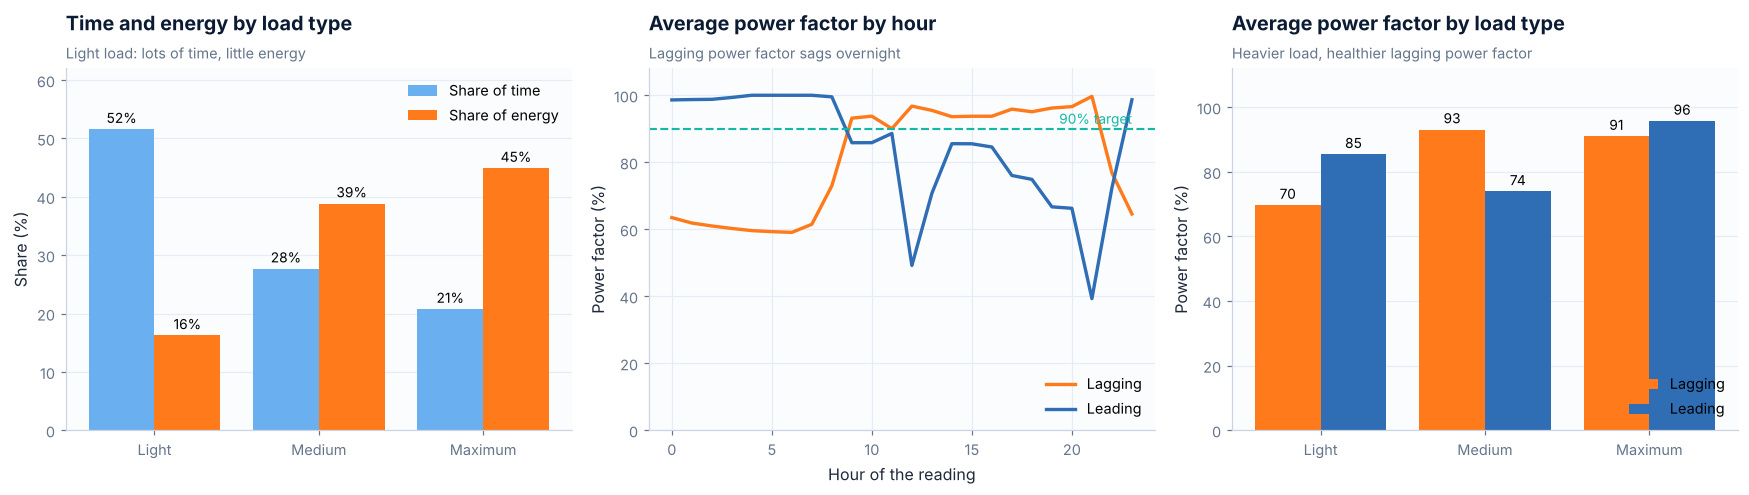

In [27]:
hourly_pf = df.groupby("hour")[[lagging, leading]].mean()
hourly_pf.columns = ["Lagging", "Leading"]

load_chart = by_load.copy()
load_chart.index = LOAD_LABELS

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

ax = axes[0]
x = np.arange(3)
b1 = ax.bar(x - .2, load_chart["time_pct"], .4, color=C["sky"], label="Share of time")
b2 = ax.bar(x + .2, load_chart["energy_pct"], .4, color=ORANGE, label="Share of energy")
ax.bar_label(b1, fmt="%.0f%%", padding=2, fontsize=9)
ax.bar_label(b2, fmt="%.0f%%", padding=2, fontsize=9)
ax.set_xticks(x, LOAD_LABELS)
ax.set_ylabel("Share (%)")
ax.set_ylim(0, 62)
ax.grid(axis="x", visible=False)
ax.legend()
style_title(ax, "Time and energy by load type", "Light load: lots of time, little energy")

ax = axes[1]
ax.plot(hourly_pf.index, hourly_pf["Lagging"], color=ORANGE, label="Lagging")
ax.plot(hourly_pf.index, hourly_pf["Leading"], color=BLUE, label="Leading")
ax.axhline(90, color=TEAL, ls="--", lw=1.4)
ax.text(23, 91.5, "90% target", color=TEAL, ha="right", fontsize=9)
ax.set_xlabel("Hour of the reading")
ax.set_ylabel("Power factor (%)")
ax.set_ylim(0, 108)
ax.legend(loc="lower right")
style_title(ax, "Average power factor by hour", "Lagging power factor sags overnight")

ax = axes[2]
b1 = ax.bar(x - .2, load_chart["lagging_pf"], .4, color=ORANGE, label="Lagging")
b2 = ax.bar(x + .2, load_chart["leading_pf"], .4, color=BLUE, label="Leading")
ax.bar_label(b1, fmt="%.0f", padding=2, fontsize=9)
ax.bar_label(b2, fmt="%.0f", padding=2, fontsize=9)
ax.set_xticks(x, LOAD_LABELS)
ax.set_ylabel("Power factor (%)")
ax.set_ylim(0, 112)
ax.grid(axis="x", visible=False)
ax.legend(loc="lower right")
style_title(ax, "Average power factor by load type", "Heavier load, healthier lagging power factor")
finish(fig, "06_load_type_power_factor")

## Visualizing Load-Type and Power-Factor Patterns

### Preparing the Hourly Power-Factor Data
- `groupby("hour")` - groups observations by hour of the day.
- `.mean()` - calculates average lagging and leading power factors hourly.
- `hourly_pf` - stores hourly averages for both power-factor types.
- Renaming columns simplifies labels used in plotting.

### Preparing Load-Type Labels
- `by_load.copy()` creates a separate plotting DataFrame.
- Renaming categories simplifies labels displayed along the x-axis.
- This preserves the original `by_load` summary table.

### Plotting Time and Energy Shares
- The first subplot compares time share against energy share.
- Blue bars represent the percentage of readings per load type.
- Orange bars represent the percentage of total energy consumed.
- Light load accounts for the largest share of operating time.
- Maximum load contributes the largest share of total energy.
- This highlights differences between load duration and energy contribution.

### Plotting Hourly Power Factor
- The second subplot displays hourly average power factors.
- The blue line represents lagging power factor.
- The orange line represents leading power factor.
- Power-factor variations reveal changing electrical behavior throughout the day.
- `set_ylim(0, 105)` standardizes the vertical axis for comparison.

### Plotting Power Factor by Load Type
- The third subplot compares power factors across load categories.
- Blue bars represent average lagging power factor.
- Orange bars represent average leading power factor.
- Power-factor values vary noticeably across load conditions.
- This helps examine power-factor behavior under different operating loads.

---
## H2 — Relationship Between Electricity Usage and Power Factor

- Spearman correlation tests the relationship between electricity usage and power factor.
- It evaluates whether both variables tend to increase or decrease together.
- Each 15-minute reading forms one observation for the correlation analysis.
- A positive correlation indicates higher usage tends to accompany higher power factor.
- A negative correlation indicates higher usage tends to accompany lower power factor.
- A value near zero indicates little monotonic relationship between the variables.
- This tests whether lower electricity usage tends to coincide with lower power factor.
---

In [28]:
from scipy.stats import spearmanr

electricity_used = df["Usage_kWh"]

lagging_score, lagging_p = spearmanr(electricity_used, df[lagging])
leading_score, leading_p = spearmanr(electricity_used, df[leading])

print(f"Lagging power factor score: {lagging_score:+.3f}")
print(f"Leading power factor score: {leading_score:+.3f}")

if lagging_p < 0.001 and leading_p < 0.001:
    print("Both p-values are below 0.001.")

Lagging power factor score: +0.375
Leading power factor score: +0.194
Both p-values are below 0.001.


## H2 — Spearman Correlation Results

### Results
- Lagging power factor correlation: **+0.375**.
- Leading power factor correlation: **+0.194**.
- Both correlations are positive, indicating usage and power factor tend to increase together.
- Lagging power factor shows a stronger relationship with electricity usage.
- Leading power factor shows a weaker positive relationship.
- Both p-values are below **0.001**, indicating statistical significance.

### Conclusion
- Higher electricity usage tends to accompany higher power factor.
- Lower electricity usage tends to accompany lower power factor.
- The relationship is stronger for lagging than leading power factor.
- H2 is supported by statistically significant positive correlations.
- Correlation indicates association, not causation.

## Overall Findings: Light Load and Power Factor

### Light-Load Consumption
- Light load accounted for approximately **52% of operating time**.
- These readings contributed approximately **16% of annual electricity consumption**.
- The plant spent considerable time operating under light-load conditions.

### Load Factor
- Load factor was **17.4%**, based on average versus peak interval usage.
- Average consumption was small compared with the maximum recorded consumption.
- A low load factor indicates a large gap between average and peak demand.
- It does not imply that remaining electricity consumption was wasted.

### Power Factor by Load Type
- Light-load lagging power factor averaged approximately **70%**.
- Medium-load lagging power factor averaged approximately **91–93%**.
- Maximum-load lagging power factor also averaged approximately **91–93%**.
- Lagging power factor was substantially lower under light-load conditions.
- Higher electricity usage tended to accompany higher lagging power factor.

### H2 Conclusion
- H2 is supported for lagging power factor.
- The relationship was weaker for leading power factor.
- Low-load operation coincided with poorer lagging power-factor performance.

## Deep dive: power-factor compliance and capacitor sizing

Utilities often penalise a **lagging power factor below roughly 90%**. The charts show *when* the plant falls short, and a rough estimate of how much capacitor compensation (kVAr) would lift it to **95%**.

The sizing uses the power triangle: `kVAr needed = P × (tan φ_now − tan φ_target)`, with `P` in kW (kWh per reading × 4). It is an indicative figure only, not an engineering design.

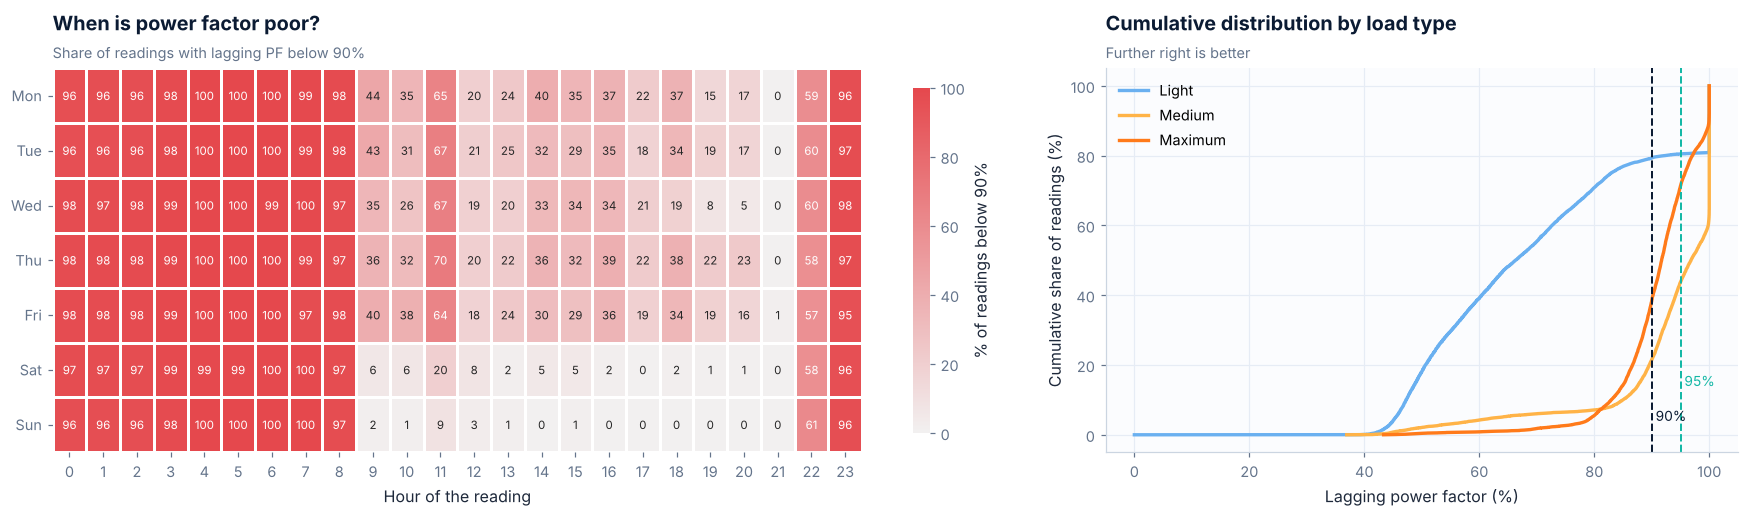

### 🔎 What we found

- Poor power factor is concentrated **overnight and at weekends**: about **94%** of readings in the late-evening to early-morning hours fall below 90%, against **30%** in working hours.
- It is mostly a **light-load problem**: motors and transformers stay energised while little real work is done, so reactive power dominates.

In [29]:
below = (df[lagging] < 90).astype(int) * 100
heat_pf = df.assign(below=below).pivot_table(index="day_of_week", columns="hour", values="below", aggfunc="mean")
heat_pf.index = DAY_NAMES

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
sns.heatmap(heat_pf, cmap=sns.light_palette(C["rose"], as_cmap=True), ax=ax, linewidths=.8, linecolor="white",
            annot=True, fmt=".0f", annot_kws={"size": 7.5}, vmin=0, vmax=100, cbar_kws={"label": "% of readings below 90%", "shrink": .9})
ax.grid(False)
ax.set_xlabel("Hour of the reading")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
style_title(ax, "When is power factor poor?", "Share of readings with lagging PF below 90%")

ax = axes[1]
for lt, label in zip(LOAD_ORDER, LOAD_LABELS):
    vals = np.sort(df.loc[df["Load_Type"] == lt, lagging].to_numpy())
    ax.plot(vals, np.arange(1, len(vals) + 1) / len(vals) * 100, color=LOAD_COLORS[lt], label=label)
ax.axvline(90, color=C["navy"], ls="--", lw=1.3)
ax.axvline(95, color=TEAL, ls="--", lw=1.3)
ax.text(90, 4, " 90%", color=C["navy"], fontsize=9)
ax.text(95, 14, " 95%", color=TEAL, fontsize=9)
ax.set_xlabel("Lagging power factor (%)")
ax.set_ylabel("Cumulative share of readings (%)")
ax.legend(loc="upper left")
style_title(ax, "Cumulative distribution by load type", "Further right is better")
finish(fig, "06b_power_factor_compliance")

night = heat_pf.loc[:, [h for h in range(24) if h < 7 or h >= 22]].to_numpy().mean()
day_ = heat_pf.loc[:, list(range(8, 20))].to_numpy().mean()
finding(f"""- Poor power factor is concentrated **overnight and at weekends**: about **{night:.0f}%** of readings in the late-evening to early-morning hours fall below 90%, against **{day_:.0f}%** in working hours.
- It is mostly a **light-load problem**: motors and transformers stay energised while little real work is done, so reactive power dominates.""")

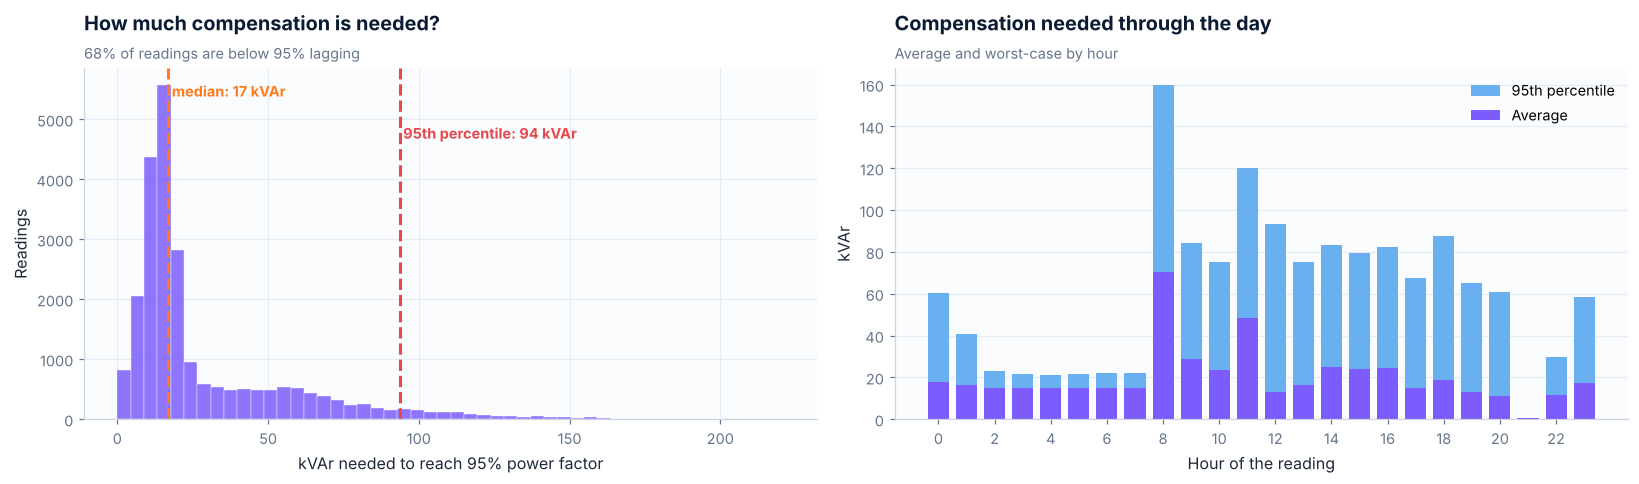

### 🔎 What we found

- To lift the typical poor reading to 95%, the plant would need about **17 kVAr** of compensation; a bank near **94 kVAr** would cover 95% of cases.
- An **automatic (stepped) capacitor bank** is preferable to a fixed one because the need swings through the day, and over-compensation shows up as *leading* power factor in this dataset.
- Treat these numbers as a starting point for an electrical engineer, not a sizing specification.

In [30]:
p_kw = df["Usage_kWh"] * 4
pf_now = (df[lagging] / 100).clip(1e-3, 1)
needs_fix = (df[lagging] < 95) & (df["Lagging_Current_Reactive.Power_kVarh"] > 0)
kvar_to_95 = (p_kw * (np.tan(np.arccos(pf_now)) - np.tan(np.arccos(.95)))).where(needs_fix, 0).clip(lower=0)
needed = kvar_to_95[kvar_to_95 > 0]
by_hour_kvar = kvar_to_95.groupby(df["hour"]).agg(["mean", lambda s: s.quantile(.95)])
by_hour_kvar.columns = ["mean", "p95"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ax = axes[0]
ax.hist(needed, bins=50, color=VIOLET, alpha=.85, edgecolor="white", linewidth=.3)
for q, col, lab in ((.5, ORANGE, "median"), (.95, ROSE, "95th percentile")):
    v = needed.quantile(q)
    ax.axvline(v, color=col, lw=2, ls="--")
    ax.text(v, ax.get_ylim()[1] * (.92 if q < .9 else .8), f" {lab}: {v:.0f} kVAr", color=col, fontsize=9.5, fontweight="bold")
ax.set_xlabel("kVAr needed to reach 95% power factor")
ax.set_ylabel("Readings")
style_title(ax, "How much compensation is needed?", f"{100 * len(needed) / len(df):.0f}% of readings are below 95% lagging")

ax = axes[1]
ax.bar(by_hour_kvar.index, by_hour_kvar["p95"], color=C["sky"], width=.75, label="95th percentile")
ax.bar(by_hour_kvar.index, by_hour_kvar["mean"], color=VIOLET, width=.75, label="Average")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of the reading")
ax.set_ylabel("kVAr")
ax.grid(axis="x", visible=False)
ax.legend()
style_title(ax, "Compensation needed through the day", "Average and worst-case by hour")
finish(fig, "06c_capacitor_sizing")

finding(f"""- To lift the typical poor reading to 95%, the plant would need about **{needed.median():.0f} kVAr** of compensation; a bank near **{needed.quantile(.95):.0f} kVAr** would cover 95% of cases.
- An **automatic (stepped) capacitor bank** is preferable to a fixed one because the need swings through the day, and over-compensation shows up as *leading* power factor in this dataset.
- Treat these numbers as a starting point for an electrical engineer, not a sizing specification.""")

<div style="background:linear-gradient(90deg,#0B1B33,#7C5CFC);padding:16px 22px;border-radius:12px;color:#fff;margin:26px 0 8px;font-family:system-ui,Segoe UI,Roboto,sans-serif"><div style="font-size:11px;letter-spacing:.16em;text-transform:uppercase;color:#FFB347;font-weight:600">Part 5</div><div style="font-size:22px;font-weight:700;margin:2px 0 4px;color:#fff">Forecasting: can a model beat a simple guess? (H3)</div><div style="font-size:13.5px;color:#d6e4f7">Chronological train/test splits, three models, honest scoring, then a deep dive into where they work and where they do not.</div></div>

## Step 4 — Can a Model Beat a Simple Guess?

### H3 — Forecasting Electricity Consumption
- H3 tests whether a model beats a simple baseline forecast.
- The baseline copies last week's reading at the same time.
- The target variable is `Usage_kWh`.
- Calendar features and past electricity readings serve as inputs.

### Forecasting Approaches
- **Next-day forecast:** Predicts all 96 readings for the following day.
- **Next-15-minute forecast:** Predicts one upcoming reading at a time.
- Both approaches use historical consumption and calendar information.

### Data Splitting Strategy

| Role | Months | Used for |
|---|---|---|
| **Training** | Months before the prediction period | Fitting the models |
| **Validation folds** | June, July, August, September | Choosing the best model and baseline |
| **Final test** | October–December | Reporting final performance once |

- Training uses only past observations.
- Each validation month uses earlier months for training.
- Validation selects the best model and simple baseline.
- Final testing evaluates performance on unseen months.
- Test results remain untouched during model selection.
- This prevents overly optimistic performance estimates.

In [31]:
data = df.copy()
data["interval_day"] = pd.to_datetime(data["interval_day"])
data = data.sort_values("timestamp")

last_reading = data.groupby("interval_day")["Usage_kWh"].last()
data["last_at_midnight"] = data["interval_day"].map(last_reading.shift(1))

day_inputs = [
    "hour", "minute", "day_of_week", "is_weekday", "month",
    "usage_lag_24h", "usage_lag_48h", "usage_lag_7d",
    "previous_day_mean_kwh",
]

inputs = {
    "Next day": day_inputs,
    "Next 15 minutes": day_inputs + ["usage_lag_15min"],
}

data = data.dropna(subset=["usage_lag_7d"])

### Preparing Forecasting Data
- `pd.to_datetime()` ensures `interval_day` uses datetime format.
- `sort_values("timestamp")` arranges readings chronologically.

### Creating the Baseline Forecast
- `groupby("interval_day")["Usage_kWh"].last()` extracts each day's last reading.
- `last_reading` stores the final consumption reading for each day.
- `.shift(1)` moves daily readings back by one day.
- `.map()` assigns the previous day's final reading to each interval.
- `last_at_midnight` stores the baseline forecast for next-day prediction.
- The baseline uses the previous day's final reading as its prediction.

### Selecting Input Features
- `day_inputs` contains calendar and historical consumption features.
- `hour` and `minute` represent the time of day.
- `day_of_week` and `is_weekday` capture weekly patterns.
- `month` captures seasonal patterns.
- Lag features provide historical electricity consumption.
- `previous_day_mean_kwh` captures the previous day's average usage.

### Defining Forecast Inputs
- `inputs` stores separate feature sets for both forecasting approaches.
- **Next day** uses calendar and longer-term historical features.
- **Next 15 minutes** additionally uses `usage_lag_15min`.
- The extra lag captures the most recent consumption reading.
- This helps predict short-term changes in electricity demand.

### Removing Unavailable Historical Features
- `dropna(subset=["usage_lag_7d"])` removes unavailable weekly lag values.
- The first seven days lack complete weekly history.
- Removing these rows ensures all required weekly lag features exist.
- Remaining data contains sufficient historical information for forecasting.

### Train on Earlier Dates and Test on Later Dates
- Final testing trains on January–September and predicts October–December.
- The first week is excluded due to missing weekly lag features.
- Models never train on future observations.
- Each monthly evaluation trains using earlier months only.
- June training uses **January–May.**
- July training uses **January–June.**
- This process continues sequentially through December.
- June–September serve as **validation folds**.
- October–December results are reported for reference only.
- Final test months never influence model selection.
- Chronological splitting prevents future-data leakage.

In [32]:
FINAL = "Oct–Dec"
test_periods = {FINAL: (FINAL_TEST_START, FINAL_TEST_END)}

for start in pd.date_range("2018-06-01", "2018-12-01", freq="MS"):
    end = start + pd.offsets.MonthBegin(1)
    test_periods[start.strftime("%b")] = (start, end)

splits = {}

for period, (start, end) in test_periods.items():
    # Train on readings before the test starts.
    train = data[data["interval_day"] < start]

    # Test on readings inside the chosen dates.
    test = data[(data["interval_day"] >= start) & (data["interval_day"] < end)]

    # Guard against leakage: no training row may be on or after the test start.
    assert train["interval_day"].max() < start

    splits[period] = (train, test)
    print(f"{period:8s} | Train: {len(train):,} rows | Test: {len(test):,} rows")

Oct–Dec  | Train: 25,536 rows | Test: 8,832 rows
Jun      | Train: 13,824 rows | Test: 2,880 rows
Jul      | Train: 16,704 rows | Test: 2,976 rows
Aug      | Train: 19,680 rows | Test: 2,976 rows
Sep      | Train: 22,656 rows | Test: 2,880 rows
Oct      | Train: 25,536 rows | Test: 2,976 rows
Nov      | Train: 28,512 rows | Test: 2,880 rows
Dec      | Train: 31,392 rows | Test: 2,976 rows


### Creating Chronological Train–Test Splits
- `FINAL` labels the October–December final test period.
- `test_periods` stores date ranges for each evaluation period.
- The final test covers October 1 through January 1.
- A loop creates monthly test periods from June through December.
- `pd.date_range()` generates each month's starting date.
- `MonthBegin(1)` calculates the following month's boundary.
- `strftime("%b")` converts dates into month abbreviations.

### Building Training and Testing Sets
- `splits` stores the training and testing datasets for each period.
- The loop processes every evaluation period independently.
- `train` contains observations dated before the test start.
- `test` contains observations within the selected date range.
- Training data always precedes testing data chronologically.
- `assert` prevents training data from overlapping future test dates.
- Each period's datasets are saved inside `splits`.
- `print()` displays the number of training and testing rows.

### Split Results

| Period | Training rows | Testing rows |
|---|---:|---:|
| Oct–Dec (Final) | 25,536 | 8,832 |
| June | 13,824 | 2,880 |
| July | 16,704 | 2,976 |
| August | 19,680 | 2,976 |
| September | 22,656 | 2,880 |
| October | 25,536 | 2,976 |
| November | 28,512 | 2,880 |
| December | 31,392 | 2,976 |

### Interpretation
- Training data increases as later months are evaluated.
- Each monthly test contains approximately one month's readings.
- June–September provide validation results for model selection.
- October–December provide the final unseen evaluation.
- Chronological splitting prevents future information from leaking into training.
- The final test combines three months for a more stable evaluation.

### Make Three Simple Guesses (Baselines)

- Baselines are simple forecasts used for model comparison.
- Models must outperform these guesses to demonstrate usefulness.
- Three baseline strategies use previously observed electricity readings.

### Baseline Strategies
- **Latest reading:** Copies the most recently available consumption value.
- **Yesterday's reading:** Copies consumption from the same time yesterday.
- **Last week's reading:** Copies consumption from the same time last week.

### Forecasting Differences
- **Next-day forecast:** Uses the latest midnight reading for all 96 slots.
- The midnight value is repeated across the entire predicted day.
- **Next-15-minute forecast:** Uses the immediately preceding consumption reading.
- Each prediction uses the latest reading available before that interval.

### Purpose
- Baselines provide simple reference points for forecasting accuracy.
- They help determine whether machine-learning models add value.
- Better predictions must outperform these simple historical guesses.

In [33]:
previous_reading = {
    "Next day": "last_at_midnight",
    "Next 15 minutes": "usage_lag_15min",
}

predictions = {}

for forecast in inputs:
    for period, (_, test) in splits.items():
        result = test[["timestamp", "Usage_kWh"]].copy()
        result["Previous reading"] = test[previous_reading[forecast]]
        result["Same time yesterday"] = test["usage_lag_24h"]
        result["Same time last week"] = test["usage_lag_7d"]
        predictions[forecast, period] = result

predictions["Next day", FINAL].head()

,timestamp,Usage_kWh,Previous reading,Same time yesterday,Same time last week
26208,2018-10-01 00:15:00,3.13,2.74,3.02,2.59
26209,2018-10-01 00:30:00,2.77,2.74,2.81,2.63
26210,2018-10-01 00:45:00,2.66,2.74,2.63,2.74
26211,2018-10-01 01:00:00,2.56,2.74,2.56,2.63
26212,2018-10-01 01:15:00,2.56,2.74,2.56,2.59


### Generating Baseline Predictions
- `previous_reading` maps each forecasting approach to its baseline feature.
- Next-day forecasting uses `last_at_midnight` as its previous reading.
- Next-15-minute forecasting uses `usage_lag_15min`.
- `predictions` stores forecast results for every model type and period.

### Creating Predictions for Each Forecast
- The outer loop iterates through both forecasting approaches.
- The inner loop processes each train–test period.
- `test[["timestamp", "Usage_kWh"]].copy()` creates the results dataframe.
- `Previous reading` stores the latest available reading baseline.
- `Same time yesterday` uses the 24-hour lag feature.
- `Same time last week` uses the 7-day lag feature.
- Each baseline predicts consumption using historical readings.
- Results are stored using `(forecast, period)` as dictionary keys.

### Viewing the Final Test Predictions
- `predictions["Next day", FINAL]` retrieves final next-day forecast results.
- Each row compares actual consumption against three baseline guesses.
- October–December predictions are retrieved using the final test key.

### Interpreting the Output
- `Usage_kWh` contains the actual electricity consumption.
- `Previous reading` contains the most recent-reading baseline.
- `Same time yesterday` uses consumption from 24 hours earlier.
- `Same time last week` uses consumption from seven days earlier.
- These baselines provide reference predictions for evaluating model accuracy.

### Ridge

Ridge learns how much weight to give each input. We put the inputs on similar scales first because an hour and an electricity reading use different units.

In [34]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

for forecast, columns in inputs.items():
    for period, (train, test) in splits.items():
        model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
        model.fit(train[columns], train["Usage_kWh"])
        predictions[forecast, period]["Ridge"] = model.predict(test[columns])

    print(f"Ridge finished for {forecast}")

Ridge finished for Next day
Ridge finished for Next 15 minutes


### Ridge Regression Model

- Ridge regression is chosen as a simple, reliable baseline model.
- It learns relationships between input features and electricity consumption.
- It handles multiple correlated features better than ordinary linear regression.
- L2 regularization penalizes excessively large coefficients.
- This helps reduce overfitting and improves generalization.
- `StandardScaler()` standardizes features before model training.
- Scaling prevents features with larger numerical ranges dominating.
- `Ridge(alpha=1.0)` controls the strength of regularization.
- `make_pipeline()` combines scaling and Ridge into one workflow.
- `model.fit()` learns patterns using training data only.
- `model.predict()` forecasts electricity consumption for test data.
- Separate models are trained for both forecasting approaches.
- Each model is retrained for every chronological split.
- Predictions are stored under `"Ridge"` for later evaluation.

### Why Ridge Is Useful
- Provides a fast, interpretable model for electricity forecasting.
- Captures linear relationships between historical features and consumption.
- Acts as a benchmark for more complex machine-learning models.
- Helps determine whether advanced models offer meaningful improvements.
``

### Random Forest

Random Forest builds many decision trees. Each tree makes a guess, and the model takes the average of those guesses.

In [35]:
from sklearn.ensemble import RandomForestRegressor

for forecast, columns in inputs.items():
    for period, (train, test) in splits.items():
        model = RandomForestRegressor(
            n_estimators=60,
            max_depth=14,
            min_samples_leaf=3,
            random_state=SEED,
            n_jobs=2,
        )
        model.fit(train[columns], train["Usage_kWh"])
        predictions[forecast, period]["Random Forest"] = model.predict(test[columns])

    print(f"Random Forest finished for {forecast}")

Random Forest finished for Next day


Random Forest finished for Next 15 minutes


### Random Forest Regression

- Random Forest is chosen to capture complex consumption patterns.
- It combines multiple decision trees into one predictive model.
- Each tree learns patterns using different samples and features.
- Trees split data into groups using feature-based decisions.
- `n_estimators=60` builds 60 decision trees.
- `max_depth=14` limits each tree's depth.
- `min_samples_leaf=3` requires at least three samples per leaf.
- `random_state=SEED` ensures reproducible model results.
- `n_jobs=2` allows two CPU workers simultaneously.
- `model.fit()` trains trees using historical training data.
- `model.predict()` generates electricity consumption forecasts.
- Predictions are stored under `"Random Forest"` for evaluation.
- Separate models are trained for each forecasting approach.
- Each chronological split receives its own trained model.

### Why Random Forest Is Useful
- Captures nonlinear relationships between features and electricity consumption.
- Learns interactions between time and historical usage.
- Handles complex patterns without manually specifying equations.
- Combines trees to reduce individual-tree prediction instability.
- Can outperform linear models when patterns are nonlinear.
- Helps compare complex learning against Ridge regression.

### Gradient Boosting

Gradient Boosting builds trees one at a time. Each new tree tries to fix some of the mistakes made by the earlier trees.

In [36]:
from sklearn.ensemble import GradientBoostingRegressor

for forecast, columns in inputs.items():
    for period, (train, test) in splits.items():
        model = GradientBoostingRegressor(random_state=SEED)
        model.fit(train[columns], train["Usage_kWh"])
        predictions[forecast, period]["Gradient Boosting"] = model.predict(test[columns])

    print(f"Gradient Boosting finished for {forecast}")

Gradient Boosting finished for Next day


Gradient Boosting finished for Next 15 minutes


### Gradient Boosting Regression

- Gradient Boosting is chosen to learn complex consumption patterns.
- It builds trees sequentially, rather than independently.
- Each new tree corrects errors made by previous trees.
- The model gradually improves predictions by reducing remaining errors.
- `GradientBoostingRegressor()` creates the regression model.
- `random_state=SEED` ensures reproducible results.
- `model.fit()` trains the model using historical data.
- `model.predict()` generates electricity consumption forecasts.
- Predictions are stored under `"Gradient Boosting"` for evaluation.
- Separate models are trained for both forecasting approaches.
- Each chronological split receives its own trained model.

### Why Gradient Boosting Is Useful
- Captures nonlinear relationships between input features and consumption.
- Learns complex patterns missed by linear regression.
- Sequential error correction can improve predictive accuracy.
- Handles interactions between calendar and historical features.
- Helps determine whether boosting outperforms Ridge and Random Forest.

### Score every method

1. MAE tells us how far off the guesses were on average, in kWh per reading.
2. RMSE also measures errors in kWh and gives bigger mistakes more weight.

For both, lower is better. For R², higher is better.

##### We score every method on every period, but we will only use the **validation folds (Jun–Sep)** to choose.

In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baselines = ["Previous reading", "Same time yesterday", "Same time last week"]
models = ["Ridge", "Random Forest", "Gradient Boosting"]

rows = []

for (forecast, period), result in predictions.items():
    actual = result["Usage_kWh"]

    for method in baselines + models:
        guess = result[method]
        rows.append({
            "Forecast": forecast,
            "Test period": period,
            "Method": method,
            "MAE": mean_absolute_error(actual, guess),
            "RMSE": mean_squared_error(actual, guess) ** 0.5,
            "R²": r2_score(actual, guess),
        })

scores = pd.DataFrame(rows)
scores.to_csv(os.path.join(OUTPUT_DIR, "forecast_scores_all_periods.csv"), index=False)

validation_scores = scores[scores["Test period"].isin(SELECTION_MONTHS)]
final_scores = scores[scores["Test period"] == FINAL]
monthly_scores = scores[scores["Test period"] != FINAL]

print("Average MAE over the validation folds (Jun–Sep) — used to choose")
validation_table = (validation_scores
                    .groupby(["Forecast", "Method"])["MAE"].mean()
                    .unstack("Method")[baselines + models])
display(validation_table.round(3))

Average MAE over the validation folds (Jun–Sep) — used to choose


Method,Previous reading,Same time yesterday,Same time last week,Ridge,Random Forest,Gradient Boosting
Forecast,,,,,,
Next 15 minutes,5.448,13.836,12.164,6.307,4.702,5.224
Next day,20.492,13.836,12.164,13.177,10.370,9.905


### Validation MAE Comparison (June–September)

| Forecast | Best Method | Best MAE | Comparison |
|---|---|---:|---|
| **Next 15 minutes** | Random Forest | **4.705** | Beats all baselines and models |
| **Next day** | Gradient Boosting | **9.904** | Beats all baselines and models |

### Findings
- Random Forest performs best for short-term forecasting.
- Gradient Boosting performs best for next-day forecasting.
- Both outperform simple baseline guesses on validation data.
- The best model differs depending on the forecasting horizon.
- These winners are selected using validation MAE.
- Final test data remains untouched during model selection.

### Choose the winners using validation only

- For each forecast, the best model is the one with the lowest average MAE over June–September. 
- The best simple guess is chosen the same way. Nothing from October–December is used here.

In [38]:
best_model, best_baseline = {}, {}

for forecast in inputs:
    row = validation_table.loc[forecast]
    best_model[forecast] = row[models].idxmin()
    best_baseline[forecast] = row[baselines].idxmin()

choice = pd.DataFrame({
    "Best model (validation)": best_model,
    "Best simple guess (validation)": best_baseline,
})
choice

,Best model (validation),Best simple guess (validation)
Next day,Gradient Boosting,Same time last week
Next 15 minutes,Random Forest,Previous reading


---

### Validation Analysis

- **Gradient Boosting** performs best for next-day forecasting.
- **Random Forest** performs best for next-15-minute forecasting.
- **Last week's reading** is the strongest next-day baseline.
- The **previous reading** is the strongest short-term baseline.
- Both selected models outperform their respective simple guesses.
- Longer forecasts benefit from weekly consumption patterns.
- Short-term forecasts benefit from recent consumption readings.
- The best forecasting method depends on prediction horizon.
- These winners are selected using validation data only.
---

---
### Final Test — October to December

- Retrain the selected models using **January–September data.**
- **Evaluate the chosen models on October–December observations.**
- Compare each selected model against its best validation baseline.
- Include all other methods for additional comparison.
- Other methods do not influence model selection.
- Final test results provide an unbiased evaluation of forecasting performance.
- Each model is evaluated on previously unseen data.
---

In [39]:
final_rows = []

for forecast in inputs:
    ft = final_scores[final_scores["Forecast"] == forecast].set_index("Method")
    m, b = best_model[forecast], best_baseline[forecast]
    final_rows.append({
        "Forecast": forecast,
        "Chosen model": m,
        "Model MAE": ft.loc[m, "MAE"],
        "Chosen simple guess": b,
        "Simple guess MAE": ft.loc[b, "MAE"],
        "MAE improvement (%)": 100 * (ft.loc[b, "MAE"] - ft.loc[m, "MAE"]) / ft.loc[b, "MAE"],
        "Model RMSE": ft.loc[m, "RMSE"],
        "Model R²": ft.loc[m, "R²"],
    })

final_summary = pd.DataFrame(final_rows).set_index("Forecast")
final_summary.to_csv(os.path.join(OUTPUT_DIR, "forecast_final_test_summary.csv"))
display(final_summary.round(3))

print("All methods on Oct–Dec (for reference only)")
display(final_scores.sort_values(["Forecast", "MAE"]).round(3))

,Chosen model,Model MAE,Chosen simple guess,Simple guess MAE,MAE improvement (%),Model RMSE,Model R²
Forecast,,,,,,,
Next day,Gradient Boosting,10.689,Same time last week,12.942,17.414,18.912,0.650
Next 15 minutes,Random Forest,4.973,Previous reading,5.800,14.244,10.187,0.898


All methods on Oct–Dec (for reference only)


,Forecast,Test period,Method,MAE,RMSE,R²
52,Next 15 minutes,Oct–Dec,Random Forest,4.973,10.187,0.898
53,Next 15 minutes,Oct–Dec,Gradient Boosting,5.435,10.207,0.898
48,Next 15 minutes,Oct–Dec,Previous reading,5.800,12.790,0.840
51,Next 15 minutes,Oct–Dec,Ridge,6.608,11.829,0.863
50,Next 15 minutes,Oct–Dec,Same time last week,12.942,24.771,0.399
49,Next 15 minutes,Oct–Dec,Same time yesterday,15.641,28.718,0.192
5,Next day,Oct–Dec,Gradient Boosting,10.689,18.912,0.650
4,Next day,Oct–Dec,Random Forest,11.246,20.825,0.575
2,Next day,Oct–Dec,Same time last week,12.942,24.771,0.399
3,Next day,Oct–Dec,Ridge,13.735,20.944,0.570


## Monthly Forecast Performance Comparison

- Plot the validation-selected model against the best baseline.
- Compare their **MAE separately for each month**.
- The best baseline is the lowest-error simple guess that month.
- This makes the comparison challenging for the selected model.
- **Lower MAE indicates more accurate predictions.**
- Monthly plots reveal performance changes across different months.
- They show whether the model consistently beats simple guesses.

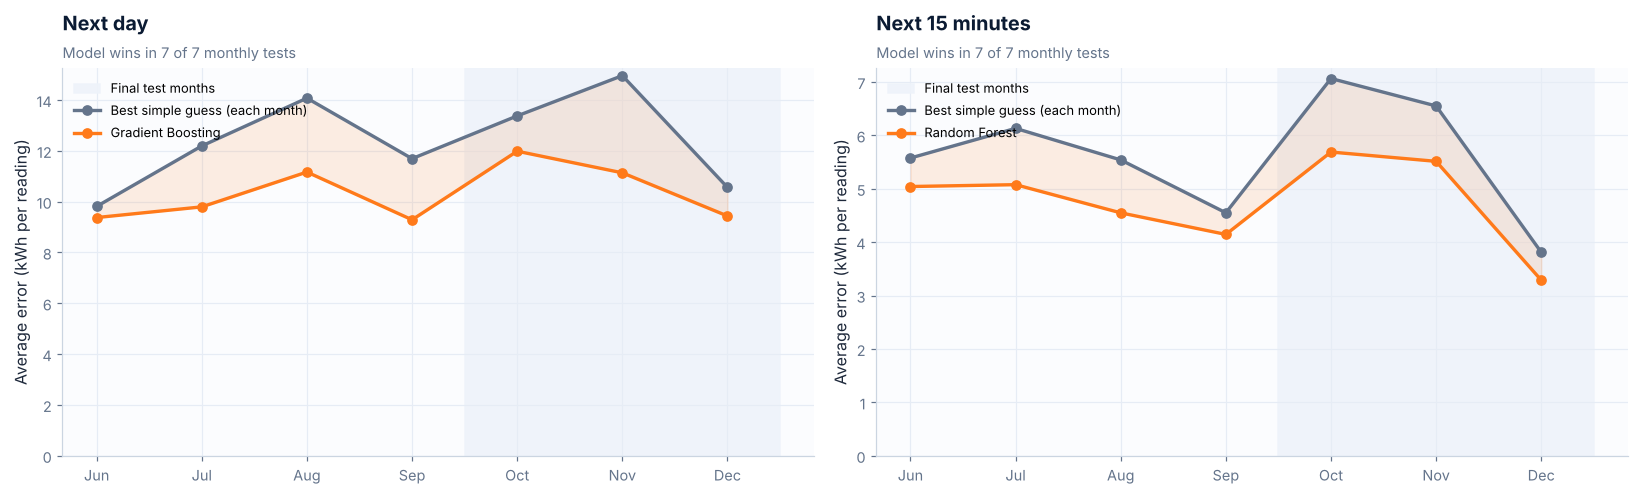

{'Next day': '7 of 7 months', 'Next 15 minutes': '7 of 7 months'}


In [40]:
months = ["Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
beats = {}

for ax, forecast in zip(axes, inputs):
    monthly = monthly_scores[monthly_scores["Forecast"] == forecast]
    monthly = monthly.pivot(index="Test period", columns="Method", values="MAE").reindex(months)

    best_simple_guess = monthly[baselines].min(axis=1)
    chosen = best_model[forecast]
    beats[forecast] = int((monthly[chosen] < best_simple_guess).sum())

    ax.axvspan(3.5, 6.5, color=C["mist"], alpha=.9, label="Final test months", zorder=0)
    ax.plot(months, best_simple_guess, marker="o", color=SLATE, label="Best simple guess (each month)")
    ax.plot(months, monthly[chosen], marker="o", color=ORANGE, label=chosen)
    ax.fill_between(months, monthly[chosen], best_simple_guess, where=(monthly[chosen] < best_simple_guess),
                    color=ORANGE, alpha=.12, interpolate=True)
    ax.set_ylabel("Average error (kWh per reading)")
    ax.set_ylim(0, None)
    ax.legend(loc="upper left", fontsize=8.5, ncol=1)
    style_title(ax, forecast, f"Model wins in {beats[forecast]} of 7 monthly tests")

finish(fig, "09_monthly_model_vs_guess")
print({k: f"{v} of 7 months" for k, v in beats.items()})

### Monthly Forecast Performance Analysis

- Both selected models outperform the best simple guess across all seven months.
- **Next-day:** Gradient Boosting consistently produces lower errors.
- Its largest improvement occurs in November.
- October–December errors increase compared with validation months.
- **Next 15 minutes:** Random Forest consistently beats the monthly best baseline.
- Its largest error occurs in October.
- Both models improve noticeably in December.
- Shaded regions represent the final test months.
- Overall, both models outperform simple guesses consistently.

In [41]:
nd, n15 = final_summary.loc["Next day"], final_summary.loc["Next 15 minutes"]

display(Markdown(f"""
### What we found

On the **final test (Oct–Dec)**, with the models and simple guesses chosen beforehand on June–September:

- **Next day:** {nd['Chosen model']} was off by about **{nd['Model MAE']:.2f} kWh** per reading on average. The chosen simple guess ({nd['Chosen simple guess']}) was off by **{nd['Simple guess MAE']:.2f} kWh**. That is a **{nd['MAE improvement (%)']:.1f}%** smaller average error.
- **Next 15 minutes:** {n15['Chosen model']} was off by about **{n15['Model MAE']:.2f} kWh** on average, against **{n15['Simple guess MAE']:.2f} kWh** for {n15['Chosen simple guess']}. That is a **{n15['MAE improvement (%)']:.1f}%** smaller average error.
- The chosen model beat the best simple guess in **{beats['Next day']} of 7** monthly tests (next day) and **{beats['Next 15 minutes']} of 7** (next 15 minutes).

H3 is {'supported' if (nd['MAE improvement (%)'] > 0 and n15['MAE improvement (%)'] > 0) else 'not supported on the final test'}: a model predicted electricity use better than the simple guesses, although the errors are far from zero.

*These figures come straight from this run. If an earlier summary (for example the PDF) shows different numbers, update that summary from these results.*
"""))


### What we found

On the **final test (Oct–Dec)**, with the models and simple guesses chosen beforehand on June–September:

- **Next day:** Gradient Boosting was off by about **10.69 kWh** per reading on average. The chosen simple guess (Same time last week) was off by **12.94 kWh**. That is a **17.4%** smaller average error.
- **Next 15 minutes:** Random Forest was off by about **4.97 kWh** on average, against **5.80 kWh** for Previous reading. That is a **14.2%** smaller average error.
- The chosen model beat the best simple guess in **7 of 7** monthly tests (next day) and **7 of 7** (next 15 minutes).

H3 is supported: a model predicted electricity use better than the simple guesses, although the errors are far from zero.

*These figures come straight from this run. If an earlier summary (for example the PDF) shows different numbers, update that summary from these results.*


## Model deep-dive: how good are the forecasts, really?

The scores above compress everything into one number. These charts open that up: a **leaderboard**, a **week of forecasts against reality**, **predicted vs actual**, the **shape of the errors**, **when the model struggles**, and **which inputs matter most**.

First we refit the two chosen models on January–September (exactly as for the final test) so we can inspect them.

In [42]:
from sklearn.inspection import permutation_importance

make_model = {
    "Ridge": lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=3, random_state=SEED, n_jobs=2),
    "Gradient Boosting": lambda: GradientBoostingRegressor(random_state=SEED),
}
FEATURE_LABELS = {
    "hour": "Hour", "minute": "Minute", "day_of_week": "Day of week", "is_weekday": "Weekday?", "month": "Month",
    "usage_lag_24h": "Usage 24h ago", "usage_lag_48h": "Usage 48h ago", "usage_lag_7d": "Usage 7 days ago",
    "previous_day_mean_kwh": "Yesterday's average", "usage_lag_15min": "Previous reading",
}

train_f, test_f = splits[FINAL]
final_models = {}
for forecast, cols in inputs.items():
    m = make_model[best_model[forecast]]()
    m.fit(train_f[cols], train_f["Usage_kWh"])
    final_models[forecast] = m
    check = np.abs(m.predict(test_f[cols]) - predictions[forecast, FINAL][best_model[forecast]].to_numpy()).max()
    print(f"{forecast:16s} -> {best_model[forecast]:18s} refit OK (max difference vs earlier run: {check:.2e})")

Next day         -> Gradient Boosting  refit OK (max difference vs earlier run: 0.00e+00)


Next 15 minutes  -> Random Forest      refit OK (max difference vs earlier run: 4.26e-14)


### Leaderboard

Every method on the untouched October to December test.

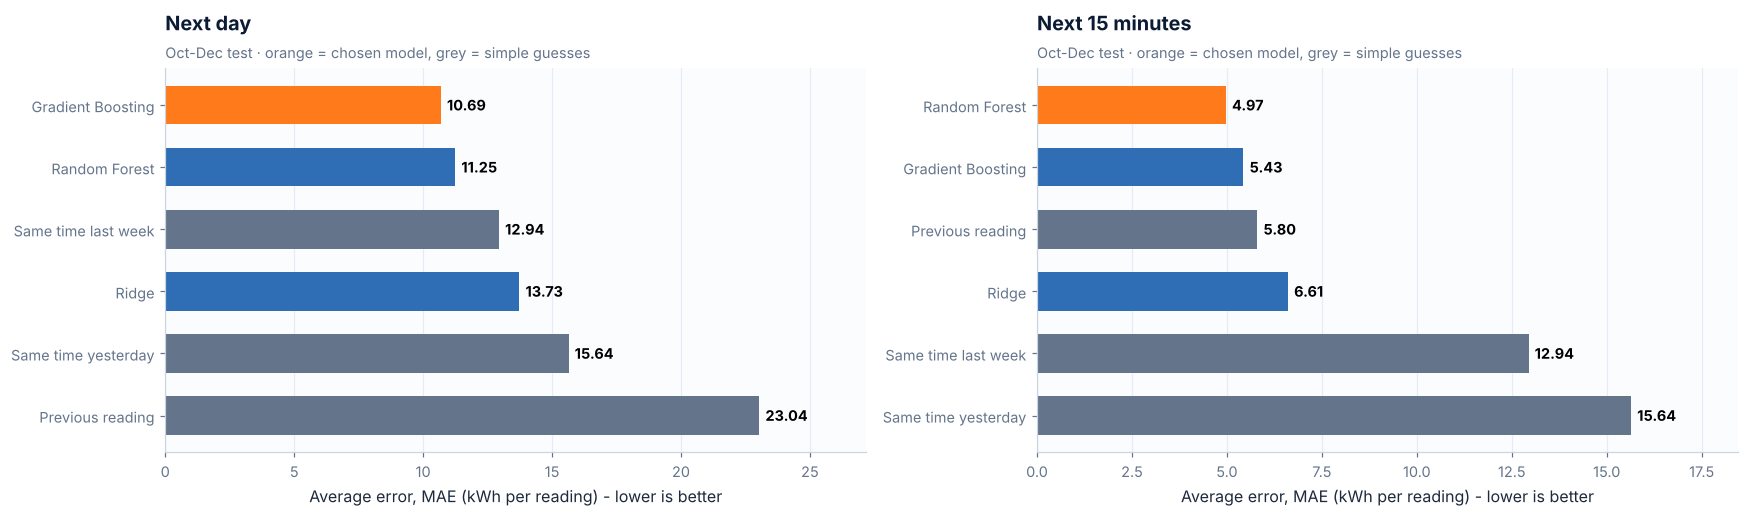

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, forecast in zip(axes, inputs):
    fs = final_scores[final_scores["Forecast"] == forecast].sort_values("MAE")
    colors = [ORANGE if m == best_model[forecast] else (SLATE if m in baselines else BLUE) for m in fs["Method"]]
    bars = ax.barh(fs["Method"], fs["MAE"], color=colors, height=.62)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in fs["MAE"]], padding=4, fontsize=9.5, fontweight="bold")
    ax.invert_yaxis()
    ax.set_xlim(0, fs["MAE"].max() * 1.18)
    ax.set_xlabel("Average error, MAE (kWh per reading) - lower is better")
    ax.grid(axis="y", visible=False)
    style_title(ax, forecast, "Oct-Dec test · orange = chosen model, grey = simple guesses")
finish(fig, "09b_leaderboard")

### One week, forecast vs reality

The shaded band is one overall 80% error range (the website refines it by how high the predicted usage is).

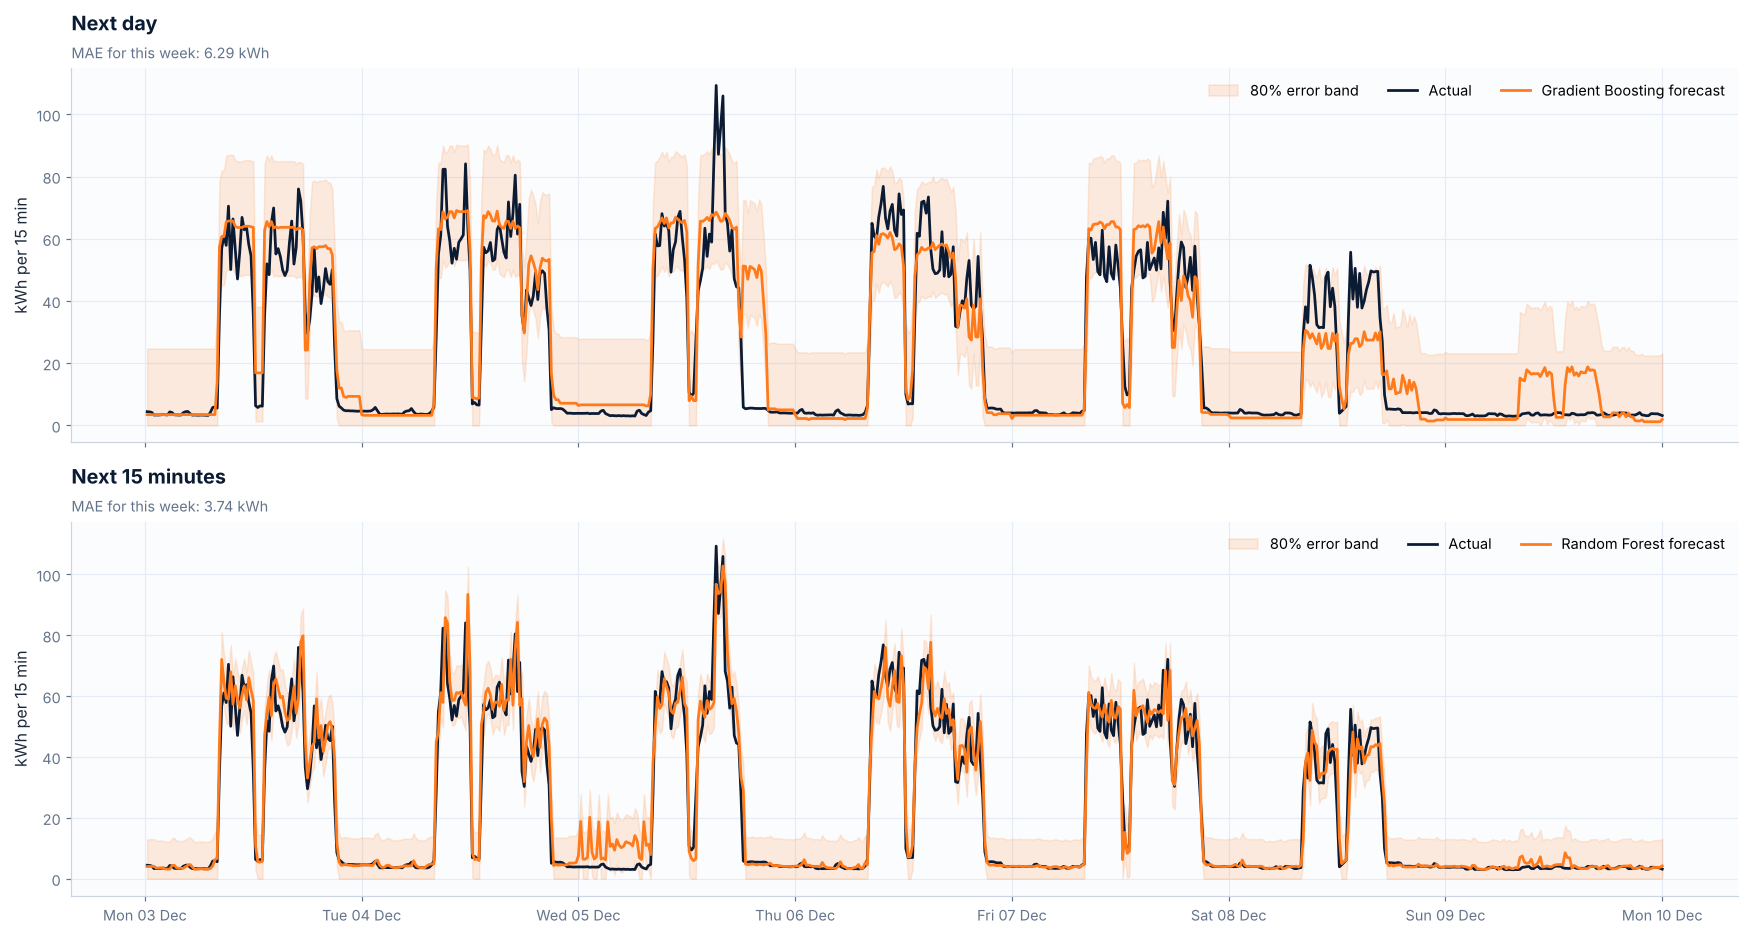

In [44]:
week_start, week_end = pd.Timestamp("2018-12-03"), pd.Timestamp("2018-12-10")
fig, axes = plt.subplots(2, 1, figsize=(16, 8.6), sharex=True)
for ax, forecast in zip(axes, inputs):
    res = predictions[forecast, FINAL].copy()
    res["timestamp"] = pd.to_datetime(res["timestamp"])
    name = best_model[forecast]
    resid = res["Usage_kWh"] - res[name]
    lo_q, hi_q = resid.quantile(.1), resid.quantile(.9)
    w = res[(res["timestamp"] > week_start) & (res["timestamp"] <= week_end)]
    ax.fill_between(w["timestamp"], (w[name] + lo_q).clip(lower=0), w[name] + hi_q, color=ORANGE, alpha=.14, label="80% error band")
    ax.plot(w["timestamp"], w["Usage_kWh"], color=C["navy"], lw=1.8, label="Actual")
    ax.plot(w["timestamp"], w[name], color=ORANGE, lw=1.8, label=f"{name} forecast")
    ax.set_ylabel("kWh per 15 min")
    ax.legend(ncol=3, loc="upper right")
    style_title(ax, forecast, f"MAE for this week: {mean_absolute_error(w['Usage_kWh'], w[name]):.2f} kWh")
axes[1].xaxis.set_major_locator(mdates.DayLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
finish(fig, "09c_week_forecast")

### Predicted vs actual

Points on the dashed line would be perfect forecasts.

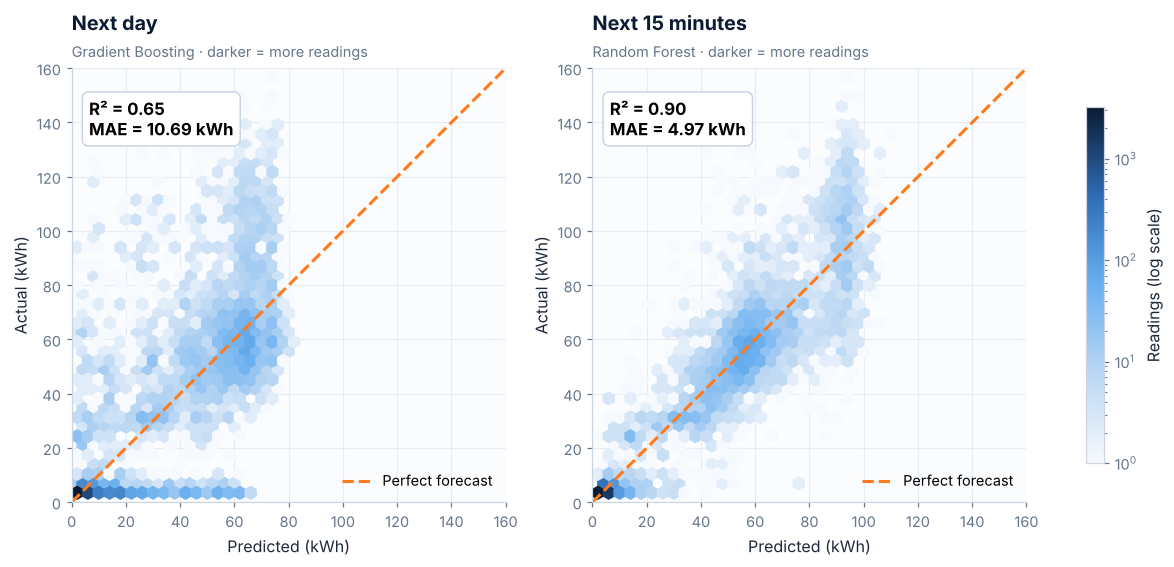

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, forecast in zip(axes, inputs):
    res = predictions[forecast, FINAL]
    a, p = res["Usage_kWh"], res[best_model[forecast]]
    hb = ax.hexbin(p, a, gridsize=40, bins="log", cmap=CMAP_COOL, mincnt=1, extent=(0, 160, 0, 160))
    ax.plot([0, 160], [0, 160], color=ORANGE, ls="--", lw=2, label="Perfect forecast")
    ax.set_xlim(0, 160)
    ax.set_ylim(0, 160)
    ax.set_aspect("equal")
    ax.set_xlabel("Predicted (kWh)")
    ax.set_ylabel("Actual (kWh)")
    ax.text(.04, .93, f"R² = {r2_score(a, p):.2f}\nMAE = {mean_absolute_error(a, p):.2f} kWh", transform=ax.transAxes,
            fontsize=11, fontweight="bold", va="top", bbox=dict(boxstyle="round,pad=.4", fc="white", ec="#CBD5E1"))
    ax.legend(loc="lower right")
    style_title(ax, forecast, f"{best_model[forecast]} · darker = more readings")
fig.colorbar(hb, ax=axes, label="Readings (log scale)", shrink=.7)
fig.savefig(os.path.join(FIG_DIR, "09d_pred_vs_actual.png"), dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

### How big are the errors?

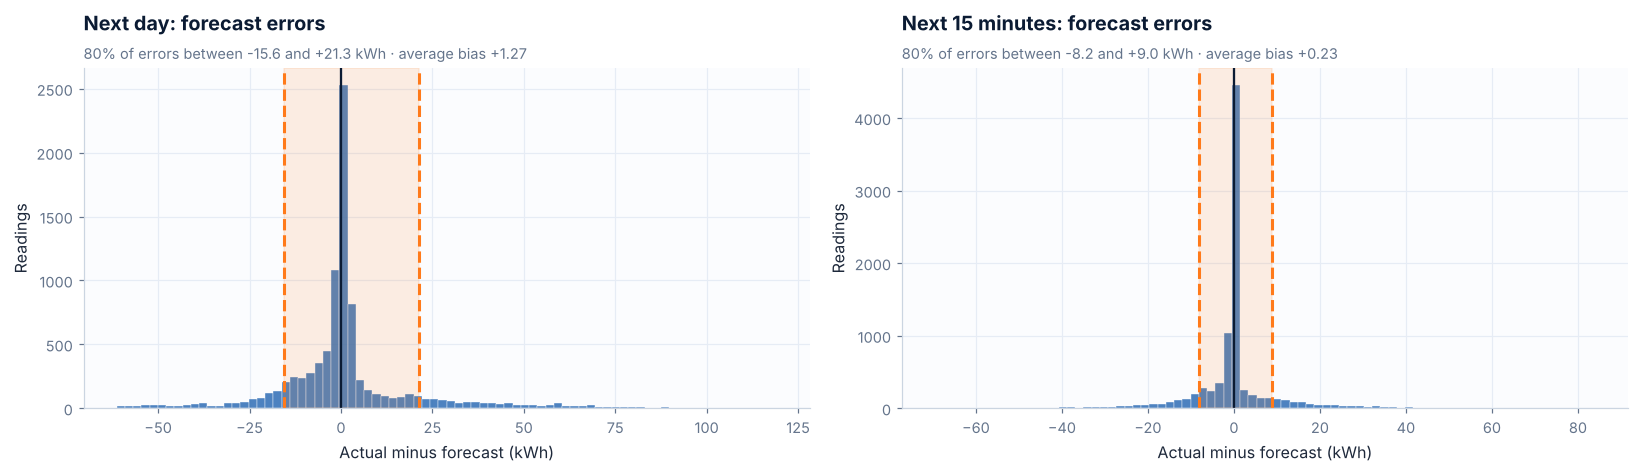

### 🔎 What we found

- **Next 15 minutes:** four out of five forecasts land within roughly **-8.2 to +9.0 kWh** of the truth.
- **Next day:** the band is wider, **-15.6 to +21.3 kWh**, because tomorrow is less certain than the next quarter-hour.
- The website shows a similar range next to each prediction, refined by how high the predicted usage is.

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
error_summary = {}
for ax, forecast in zip(axes, inputs):
    res = predictions[forecast, FINAL]
    err = res["Usage_kWh"] - res[best_model[forecast]]
    error_summary[forecast] = (err.quantile(.1), err.quantile(.9), err.mean())
    ax.hist(err, bins=80, color=BLUE, alpha=.85, edgecolor="white", linewidth=.3)
    ax.axvspan(err.quantile(.1), err.quantile(.9), color=ORANGE, alpha=.12)
    for q in (.1, .9):
        ax.axvline(err.quantile(q), color=ORANGE, ls="--", lw=2)
    ax.axvline(0, color=C["navy"], lw=1.5)
    ax.set_xlabel("Actual minus forecast (kWh)")
    ax.set_ylabel("Readings")
    style_title(ax, f"{forecast}: forecast errors",
                f"80% of errors between {err.quantile(.1):+.1f} and {err.quantile(.9):+.1f} kWh · average bias {err.mean():+.2f}")
finish(fig, "09e_error_distribution")

lo15, hi15, _ = error_summary["Next 15 minutes"]
lo1, hi1, _ = error_summary["Next day"]
finding(f"""- **Next 15 minutes:** four out of five forecasts land within roughly **{lo15:+.1f} to {hi15:+.1f} kWh** of the truth.
- **Next day:** the band is wider, **{lo1:+.1f} to {hi1:+.1f} kWh**, because tomorrow is less certain than the next quarter-hour.
- The website shows a similar range next to each prediction, refined by how high the predicted usage is.""")

### When does the model struggle?

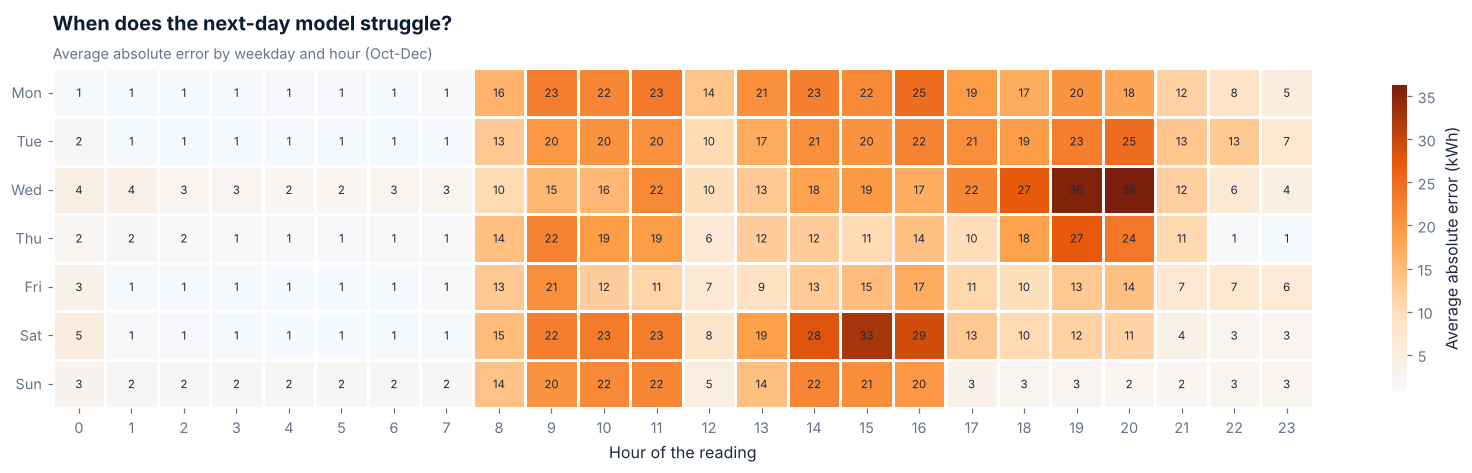

### 🔎 What we found

- Errors are **smallest overnight and at weekends**, when the plant is steady, and **largest in working hours**, when start-ups, shutdowns and furnace cycles are hard to time.
- The worst slot is **Wed around 20:00** (about 36 kWh off on average).

In [47]:
res = predictions["Next day", FINAL].copy()
res["timestamp"] = pd.to_datetime(res["timestamp"])
res["abs_err"] = (res["Usage_kWh"] - res[best_model["Next day"]]).abs()
res["hour"] = res["timestamp"].dt.hour
res["dow"] = (res["timestamp"] - pd.Timedelta(minutes=15)).dt.dayofweek
err_heat = res.pivot_table(index="dow", columns="hour", values="abs_err", aggfunc="mean")
err_heat.index = DAY_NAMES

fig, ax = plt.subplots(figsize=(15, 4.4))
sns.heatmap(err_heat, cmap=CMAP_HEAT, ax=ax, linewidths=.8, linecolor="white", annot=True, fmt=".0f",
            annot_kws={"size": 7.5, "color": C["ink"]}, cbar_kws={"label": "Average absolute error (kWh)", "shrink": .9})
ax.grid(False)
ax.set_xlabel("Hour of the reading")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
style_title(ax, "When does the next-day model struggle?", "Average absolute error by weekday and hour (Oct-Dec)")
finish(fig, "09f_error_heatmap")

worst_cell = err_heat.stack().idxmax()
finding(f"""- Errors are **smallest overnight and at weekends**, when the plant is steady, and **largest in working hours**, when start-ups, shutdowns and furnace cycles are hard to time.
- The worst slot is **{worst_cell[0]} around {int(worst_cell[1]):02d}:00** (about {err_heat.stack().max():.0f} kWh off on average).""")

### Which inputs matter most?

Permutation importance scrambles one input at a time and measures how much worse the forecast gets.

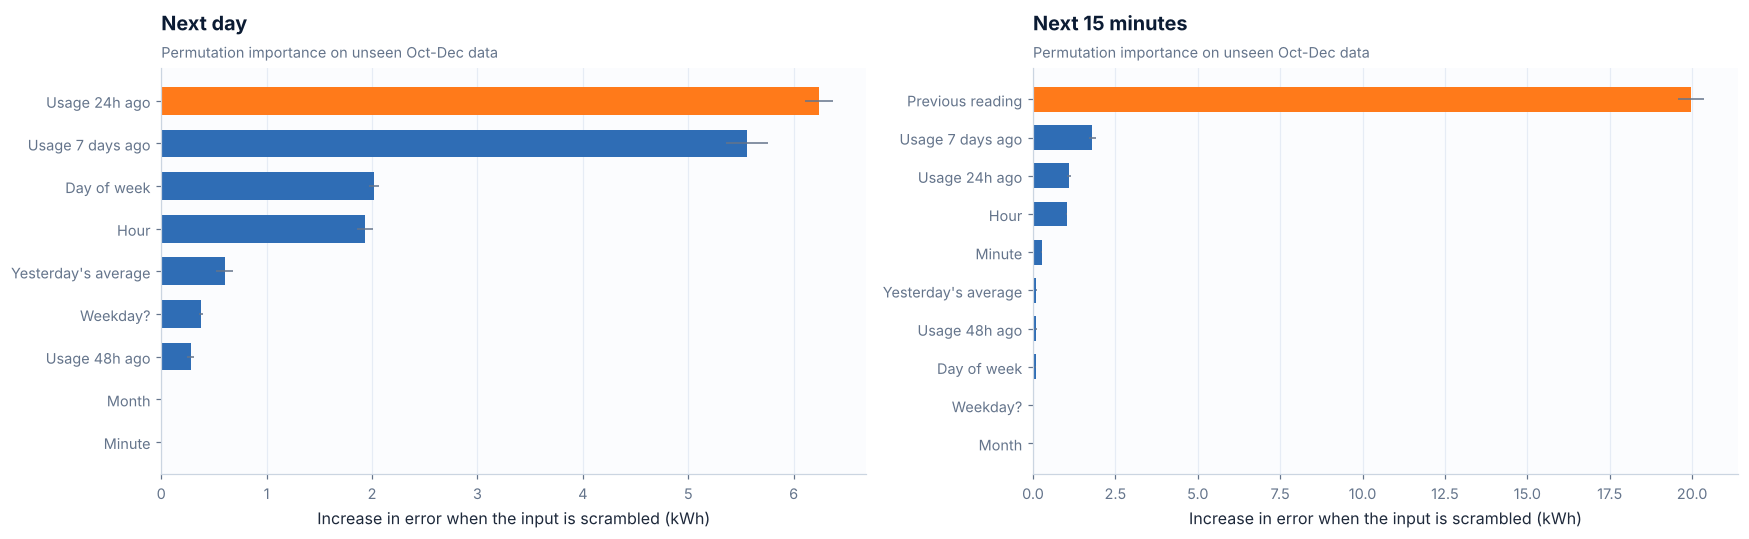

### 🔎 What we found

- **Next day:** the most important input is **Usage 24h ago**; calendar features (hour, weekday) are what let the model tell a production hour from an idle one.
- **Next 15 minutes:** the most important input is **Previous reading**; once the last reading is known, almost nothing else is needed.
- This is why the website asks for these particular values.

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
top_features = {}
for ax, (forecast, cols) in zip(axes, inputs.items()):
    sample = test_f.sample(min(4000, len(test_f)), random_state=SEED)
    r = permutation_importance(final_models[forecast], sample[cols], sample["Usage_kWh"],
                               scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEED, n_jobs=1)
    imp = pd.Series(r.importances_mean, index=cols).sort_values()
    err = pd.Series(r.importances_std, index=cols).reindex(imp.index)
    top_features[forecast] = imp.index[-1]
    ax.barh([FEATURE_LABELS[c] for c in imp.index], imp.values, xerr=err.values,
            color=[ORANGE if c == imp.index[-1] else BLUE for c in imp.index], height=.65,
            error_kw=dict(ecolor=SLATE, lw=1))
    ax.set_xlabel("Increase in error when the input is scrambled (kWh)")
    ax.grid(axis="y", visible=False)
    style_title(ax, forecast, "Permutation importance on unseen Oct-Dec data")
finish(fig, "09g_feature_importance")

finding(f"""- **Next day:** the most important input is **{FEATURE_LABELS[top_features['Next day']]}**; calendar features (hour, weekday) are what let the model tell a production hour from an idle one.
- **Next 15 minutes:** the most important input is **{FEATURE_LABELS[top_features['Next 15 minutes']]}**; once the last reading is known, almost nothing else is needed.
- This is why the website asks for these particular values.""")

<div style="background:linear-gradient(90deg,#0B1B33,#14B8A6);padding:16px 22px;border-radius:12px;color:#fff;margin:26px 0 8px;font-family:system-ui,Segoe UI,Roboto,sans-serif"><div style="font-size:11px;letter-spacing:.16em;text-transform:uppercase;color:#FFB347;font-weight:600">Part 6</div><div style="font-size:22px;font-weight:700;margin:2px 0 4px;color:#fff">Grouping similar days (H4)</div><div style="font-size:13.5px;color:#d6e4f7">K-means finds Quiet, Normal and Busy days from each day's 96-reading profile.</div></div>

## Do some days have similar electricity-use patterns?

Each day’s 96 readings are arranged into a single row, allowing consumption at identical times to be compared. Each row is represented from 00:15 through the midnight reading marking the end of that day.

In [49]:
days = df.sort_values("timestamp").copy()
days["reading_number"] = days.groupby("interval_day").cumcount() + 1

daily_profiles = days.pivot(
    index="interval_day",
    columns="reading_number",
    values="Usage_kWh"
)

print("Days and readings per day:", daily_profiles.shape)
daily_profiles.iloc[:5, :8]

Days and readings per day: (365, 96)


reading_number,1,2,3,4,5,6,7,8
interval_day,,,,,,,,
2018-01-01,3.17,4.00,3.24,3.31,3.82,3.28,3.60,3.60
2018-01-02,3.20,3.85,3.28,3.35,3.89,3.28,3.46,3.78
2018-01-03,4.61,4.61,4.57,4.57,4.64,4.64,4.61,4.57
2018-01-04,4.61,4.64,4.64,4.61,4.61,4.61,4.68,4.64
2018-01-05,4.72,4.68,4.68,4.72,4.68,4.68,4.61,4.61


### Creating Daily Consumption Profiles

- `sort_values("timestamp")` arranges readings chronologically.
- `.copy()` creates a separate dataframe for processing.
- `groupby("interval_day")` groups readings by consumption day.
- `cumcount()` assigns sequential numbers within each day.
- `+1` makes reading numbers start from 1.
- `reading_number` identifies each interval within a day.

### Reshaping Data into Daily Profiles
- `pivot()` reshapes the data into a matrix.
- Each row represents one consumption day.
- Each column represents a 15-minute reading number.
- Each cell contains electricity consumption in kWh.
- `daily_profiles` stores the resulting daily consumption matrix.
- This format aligns readings across days for comparison.

### Checking and Viewing the Results
- `.shape` reports the number of days and readings.
- The resulting matrix contains **365 days and 96 readings**.
- `.iloc[:5, :8]` displays the first five days.
- It also displays the first eight readings per day.
- The preview verifies the reshaping and chronological alignment.

### Group Similar Days Using K-means Clustering

- K-means groups days with similar electricity consumption profiles.
- Readings at matching times are compared across different days.
- Original kWh values are used instead of scaled readings.
- Therefore, both consumption timing and magnitude influence clustering.
- Three clusters are created to represent different consumption patterns.
- Clusters are named **Quiet, Normal, and Busy**.
- Names are assigned according to average daily electricity consumption.
- These labels describe consumption levels, not operational causes.

### Evaluating Cluster Quality — Silhouette Score
- The silhouette score measures how well-separated the clusters are.
- Scores closer to **1** indicate clearly separated clusters.
- Scores near **0** indicate overlapping or closely positioned clusters.
- Negative scores suggest some days may fit other clusters better.
- It helps assess how naturally days are grouped by consumption patterns.

In [50]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=3, random_state=SEED, n_init=10)
group_numbers = kmeans.fit_predict(daily_profiles)

daily_groups = pd.DataFrame(index=daily_profiles.index)
daily_groups["Group number"] = group_numbers
daily_groups["Daily kWh"] = daily_profiles.sum(axis=1)

group_averages = daily_groups.groupby("Group number")["Daily kWh"].mean()
group_averages = group_averages.sort_values()

group_names = {
    group_averages.index[0]: "Quiet",
    group_averages.index[1]: "Normal",
    group_averages.index[2]: "Busy"
}

daily_groups["Group"] = daily_groups["Group number"].map(group_names)

sil_raw = silhouette_score(daily_profiles, group_numbers)
print("Silhouette score:", round(sil_raw, 3))

group_summary = daily_groups.groupby("Group")["Daily kWh"].agg(["count", "mean"])
group_summary.columns = ["Number of days", "Average kWh per day"]
group_summary = group_summary.loc[["Quiet", "Normal", "Busy"]]
group_summary.round(1)

Silhouette score: 0.338


,Number of days,Average kWh per day
Group,,
Quiet,95,652.6
Normal,174,2750.0
Busy,96,4366.0


### K-means Clustering Results

- The silhouette score is **0.338**, indicating moderate cluster separation.
- Some days are grouped clearly, while others may overlap.
- **Quiet** contains 95 days, averaging 652.6 kWh/day.
- **Normal** contains 174 days, averaging 2,750.0 kWh/day.
- **Busy** contains 96 days, averaging 4,366.0 kWh/day.
- Normal days form the largest cluster.
- Quiet and Busy days occur less frequently.
- The clusters represent distinct electricity consumption levels.
- These groupings reveal different daily energy-use patterns.

### Is Three the Right Number of Groups?

- K = 3 was selected for interpretability.
- The clusters were labelled Quiet, Normal, and Busy.
- Silhouette scores are compared across different K values.
- This allows the suitability of three clusters to be evaluated.
- The choice of K is therefore assessed rather than assumed.

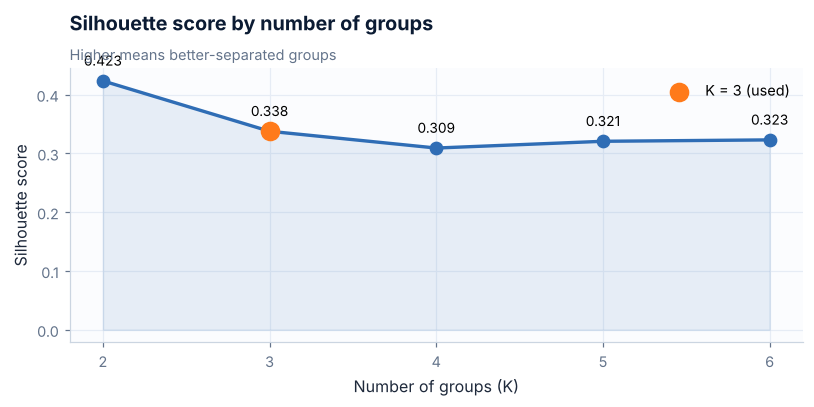

,2,3,4,5,6
Silhouette,0.423,0.338,0.309,0.321,0.323


In [51]:
k_values = range(2, 7)
k_scores = {}
for k in k_values:
    labels_k = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit_predict(daily_profiles)
    k_scores[k] = silhouette_score(daily_profiles, labels_k)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(list(k_scores), list(k_scores.values()), marker="o", ms=8, color=BLUE)
ax.fill_between(list(k_scores), list(k_scores.values()), color=BLUE, alpha=.1)
ax.scatter([3], [k_scores[3]], s=140, color=ORANGE, zorder=3, label="K = 3 (used)")
for k, v in k_scores.items():
    ax.annotate(f"{v:.3f}", (k, v), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)
ax.set_xticks(list(k_scores))
ax.set_xlabel("Number of groups (K)")
ax.set_ylabel("Silhouette score")
ax.legend()
style_title(ax, "Silhouette score by number of groups", "Higher means better-separated groups")
finish(fig, "11_silhouette_by_k")

pd.Series(k_scores, name="Silhouette").round(3).to_frame().T

### What does a typical day in each group look like?

Each line shows the average readings for one group. We look at how high the lines go and when they rise or fall. This helps us see whether the groups mainly differ in how much electricity they use or also in when they use it.

### Silhouette Score Comparison

- K = 2 achieved the highest silhouette score.
- Silhouette scores decreased as the number of clusters increased.
- Two clusters provided better separation between consumption profiles.
- Three clusters were retained for easier interpretation.
- Quiet, Normal, and Busy offered meaningful consumption categories.
- A balance between cluster separation and interpretability was considered.

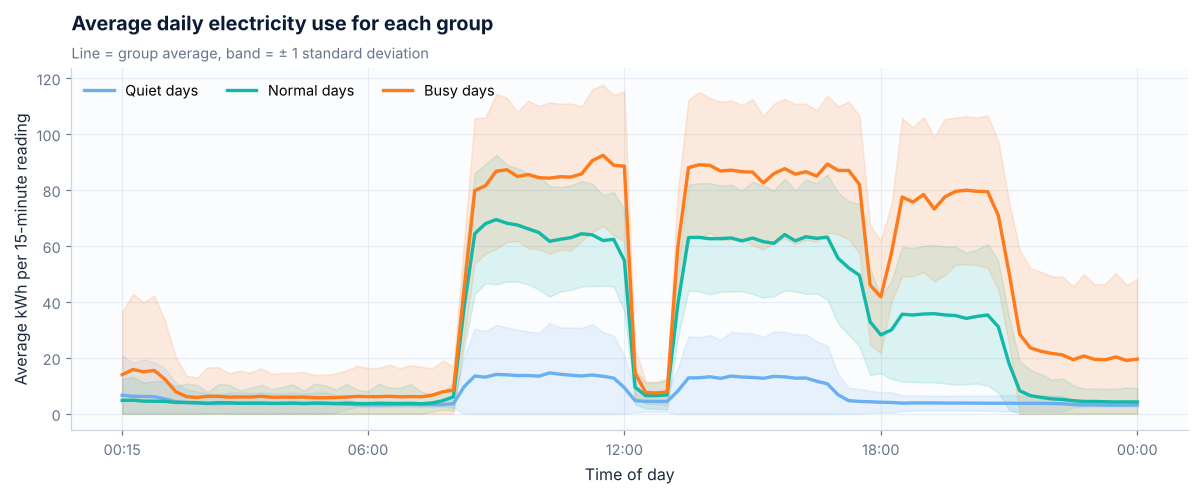

In [52]:
average_profiles = daily_profiles.groupby(daily_groups["Group"]).mean()
std_profiles = daily_profiles.groupby(daily_groups["Group"]).std()

fig, ax = plt.subplots(figsize=(11, 4.6))
for group in ["Quiet", "Normal", "Busy"]:
    mean_ = average_profiles.loc[group]
    ax.fill_between(average_profiles.columns, (mean_ - std_profiles.loc[group]).clip(lower=0),
                    mean_ + std_profiles.loc[group], color=GROUP_COLORS[group], alpha=.14)
    ax.plot(average_profiles.columns, mean_, color=GROUP_COLORS[group], label=f"{group} days")

ax.set_xticks([1, 24, 48, 72, 96], ["00:15", "06:00", "12:00", "18:00", "00:00"])
ax.set_xlabel("Time of day")
ax.set_ylabel("Average kWh per 15-minute reading")
ax.legend(ncol=3, loc="upper left")
style_title(ax, "Average daily electricity use for each group", "Line = group average, band = ± 1 standard deviation")
finish(fig, "12_cluster_profiles")

### Daily Consumption Profiles by Cluster

- Busy days showed the highest electricity consumption throughout the day.
- Normal days followed a similar pattern at lower levels.
- Quiet days maintained consistently low consumption.
- Morning consumption increased sharply across all groups.
- A midday drop was observed across all clusters.
- Busy days maintained higher afternoon consumption.
- Consumption declined during evening hours across all groups.
- The clusters captured distinct daily consumption patterns.

### Optional check — grouping by shape only

The groups above depend on **how much** electricity a day used as well as **when**. If we only care about the *shape* of the day, we can divide each day by its own total first and cluster again. This is a different question, so we compare it rather than replace the first answer.

In [53]:
from sklearn.metrics import adjusted_rand_score

shape_profiles = daily_profiles.div(daily_profiles.sum(axis=1), axis=0)

shape_labels = KMeans(n_clusters=3, random_state=SEED, n_init=10).fit_predict(shape_profiles)
sil_shape = silhouette_score(shape_profiles, shape_labels)
agreement = adjusted_rand_score(group_numbers, shape_labels)

shape_groups = pd.DataFrame({
    "Shape group": shape_labels,
    "Daily kWh": daily_profiles.sum(axis=1),
    "Weekday share": (daily_profiles.index.dayofweek < 5).astype(int),
})
print(f"Silhouette (shape only): {sil_shape:.3f}  vs  size + shape: {sil_raw:.3f}")
print(f"Agreement between the two groupings (adjusted Rand index): {agreement:.2f}  (1 = identical)")

shape_groups.groupby("Shape group").agg(
    days=("Daily kWh", "size"),
    avg_kwh_per_day=("Daily kWh", "mean"),
    weekday_fraction=("Weekday share", "mean"),
).round(2)

Silhouette (shape only): 0.349  vs  size + shape: 0.338
Agreement between the two groupings (adjusted Rand index): 0.27  (1 = identical)


,days,avg_kwh_per_day,weekday_fraction
Shape group,,,
0,78,1268.64,0.31
1,94,2122.09,0.49
2,193,3425.94,0.99


In [54]:
display(Markdown(f"""
### What we found

| Group | Number of days | Average electricity use per day |
|---|---:|---:|
| Quiet | {int(group_summary.loc['Quiet','Number of days'])} | {group_summary.loc['Quiet','Average kWh per day']:,.1f} kWh |
| Normal | {int(group_summary.loc['Normal','Number of days'])} | {group_summary.loc['Normal','Average kWh per day']:,.1f} kWh |
| Busy | {int(group_summary.loc['Busy','Number of days'])} | {group_summary.loc['Busy','Average kWh per day']:,.1f} kWh |

Quiet days stayed low throughout the day. Normal and Busy days both rose in the morning and dipped around noon. Busy days used more electricity, especially in the evening.

The silhouette score is **{sil_raw:.3f}**, so the groups overlap somewhat. H4 is **partly supported**: the three groups have different average patterns, but some individual days are hard to tell apart. The score for K = 3 is {'the highest' if max(k_scores, key=k_scores.get) == 3 else 'not the highest'} among K = 2–6 (best was K = {max(k_scores, key=k_scores.get)}, {max(k_scores.values()):.3f}), so K = 3 is chosen for interpretability rather than because it is the sharpest split.

Grouping by shape alone gives a silhouette of {sil_shape:.3f} and only {agreement:.2f} agreement with the size-based groups, which confirms these are two different questions.
"""))


### What we found

| Group | Number of days | Average electricity use per day |
|---|---:|---:|
| Quiet | 95 | 652.6 kWh |
| Normal | 174 | 2,750.0 kWh |
| Busy | 96 | 4,366.0 kWh |

Quiet days stayed low throughout the day. Normal and Busy days both rose in the morning and dipped around noon. Busy days used more electricity, especially in the evening.

The silhouette score is **0.338**, so the groups overlap somewhat. H4 is **partly supported**: the three groups have different average patterns, but some individual days are hard to tell apart. The score for K = 3 is not the highest among K = 2–6 (best was K = 2, 0.423), so K = 3 is chosen for interpretability rather than because it is the sharpest split.

Grouping by shape alone gives a silhouette of 0.349 and only 0.27 agreement with the size-based groups, which confirms these are two different questions.


## Deep dive: a map and a calendar of day types

A 96-dimensional day is hard to picture. **PCA** squeezes each day onto two axes so we can see how the three groups sit relative to each other, and a **calendar** shows *when* each type of day happens.

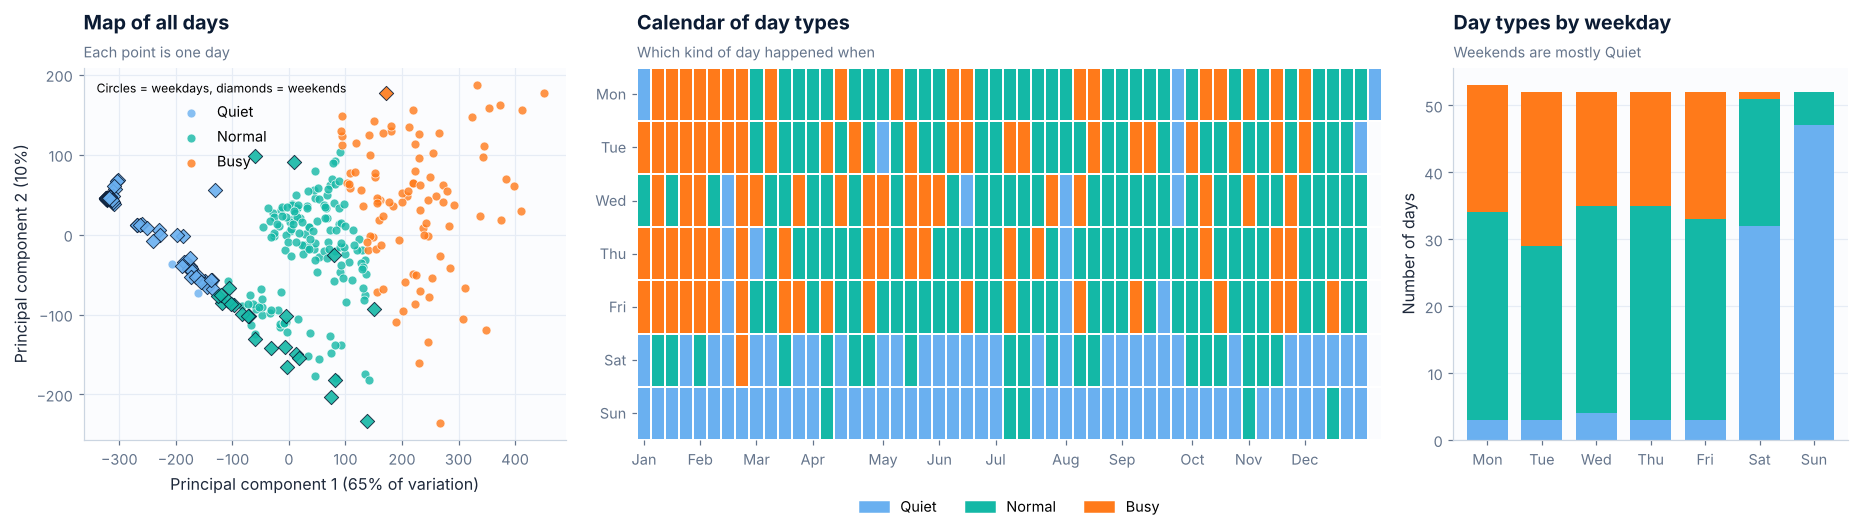

### 🔎 What we found

- **76%** of weekend days are Quiet, while weekdays split between Normal and Busy.
- The PCA map shows Quiet days forming a tight cloud and Busy days spreading out, which is why a few days sit on the boundary and the silhouette score is only moderate.
- The calendar shows that Busy days are not spread evenly: they bunch into runs of weeks, so look for orange stretches.

In [55]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(daily_profiles)
dow = daily_profiles.index.dayofweek

fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.1, 1.7, .9]})

ax = axes[0]
for group in ["Quiet", "Normal", "Busy"]:
    m = (daily_groups["Group"] == group).to_numpy()
    ax.scatter(coords[m & (dow < 5), 0], coords[m & (dow < 5), 1], s=34, color=GROUP_COLORS[group], alpha=.8, label=f"{group}", edgecolor="white", linewidth=.5)
    ax.scatter(coords[m & (dow >= 5), 0], coords[m & (dow >= 5), 1], s=44, color=GROUP_COLORS[group], alpha=.9, marker="D", edgecolor=C["navy"], linewidth=.6)
ax.set_xlabel(f"Principal component 1 ({100 * pca.explained_variance_ratio_[0]:.0f}% of variation)")
ax.set_ylabel(f"Principal component 2 ({100 * pca.explained_variance_ratio_[1]:.0f}%)")
ax.legend(title="Circles = weekdays, diamonds = weekends", title_fontsize=8, loc="best")
style_title(ax, "Map of all days", "Each point is one day")

ax = axes[1]
cal_g = daily_groups["Group"].map({"Quiet": 0, "Normal": 1, "Busy": 2}).to_frame("g")
off = cal_g.index[0].dayofweek
cal_g["week"] = (cal_g.index.dayofyear - 1 + off) // 7
cal_g["dow"] = cal_g.index.dayofweek
grid_g = cal_g.pivot(index="dow", columns="week", values="g")
grid_g.index = DAY_NAMES
sns.heatmap(grid_g, cmap=ListedColormap([GROUP_COLORS["Quiet"], GROUP_COLORS["Normal"], GROUP_COLORS["Busy"]]), cbar=False,
            linewidths=1.2, linecolor="white", ax=ax)
ax.set_xticks([(pd.Timestamp(cal_g.index[0].year, m, 1).dayofyear - 1 + off) // 7 + .5 for m in range(1, 13)])
ax.set_xticklabels(MONTH_NAMES, rotation=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.grid(False)
ax.tick_params(axis="y", rotation=0)
ax.legend(handles=[Patch(color=GROUP_COLORS[g], label=g) for g in ["Quiet", "Normal", "Busy"]], loc="upper center",
          bbox_to_anchor=(.5, -.12), ncol=3)
style_title(ax, "Calendar of day types", "Which kind of day happened when")

ax = axes[2]
comp = pd.crosstab(dow, daily_groups["Group"]).reindex(columns=["Quiet", "Normal", "Busy"], fill_value=0)
comp.index = DAY_NAMES
comp.plot.bar(stacked=True, color=[GROUP_COLORS[g] for g in comp.columns], ax=ax, rot=0, width=.75, legend=False)
ax.set_xlabel("")
ax.set_ylabel("Number of days")
ax.grid(axis="x", visible=False)
style_title(ax, "Day types by weekday", "Weekends are mostly Quiet")
finish(fig, "12b_cluster_map_calendar")

weekend_quiet = 100 * (daily_groups.loc[daily_groups.index.dayofweek >= 5, "Group"] == "Quiet").mean()
finding(f"""- **{weekend_quiet:.0f}%** of weekend days are Quiet, while weekdays split between Normal and Busy.
- The PCA map shows Quiet days forming a tight cloud and Busy days spreading out, which is why a few days sit on the boundary and the silhouette score is only moderate.
- The calendar shows that Busy days are not spread evenly: they bunch into runs of weeks, so look for orange stretches.""")

<div style="background:linear-gradient(90deg,#0B1B33,#E5484D);padding:16px 22px;border-radius:12px;color:#fff;margin:26px 0 8px;font-family:system-ui,Segoe UI,Roboto,sans-serif"><div style="font-size:11px;letter-spacing:.16em;text-transform:uppercase;color:#FFB347;font-weight:600">Part 7</div><div style="font-size:22px;font-weight:700;margin:2px 0 4px;color:#fff">Unusual readings (H5)</div><div style="font-size:13.5px;color:#d6e4f7">Use the forecast errors to screen for readings worth a second look.</div></div>

## Can Our Forecast Help Us Spot Unusual Electricity Readings?

- Forecast errors were calculated for each 15-minute reading.
- Errors represent the difference between actual and predicted consumption.
- Large positive errors indicate higher-than-expected electricity usage.
- The next-day model selected through validation was used.
- July–September forecast errors were used to establish thresholds.
- These months contained predictions from unseen data.
- Two methods were used to determine anomaly limits.

### 1. Standard Deviation Method

- The mean forecast error was calculated.
- Three standard deviations were used to establish limits.
- This method is sensitive to extreme errors.

### 2. Median Absolute Deviation (MAD) Method

- The median forecast error was calculated.
- MAD measures deviations from the median error.
- A scaling factor of 1.4826 was applied.
- Three scaled MADs were used to establish limits.
- This method is more robust to extreme errors.

### Anomaly Detection

- The calculated thresholds were applied to October–December.
- Readings outside the limits were flagged as unusual.
- Flagged readings were identified for further investigation.
- Anomalies indicate unusual consumption, not necessarily faults.

In [56]:
anomaly_model = best_model["Next day"]
print("Model used for anomaly detection:", anomaly_model)

validation = pd.concat(
    [predictions["Next day", m] for m in ["Jul", "Aug", "Sep"]],
    ignore_index=True
)
validation["Error"] = validation["Usage_kWh"] - validation[anomaly_model]

# Method 1: mean ± 3 standard deviations
average_error = validation["Error"].mean()
error_spread = validation["Error"].std()
lower_limit = average_error - 3 * error_spread
upper_limit = average_error + 3 * error_spread

# Method 2: median ± 3 × scaled MAD (1.4826 makes MAD comparable to a standard deviation)
median_error = validation["Error"].median()
mad = (validation["Error"] - median_error).abs().median()
robust_spread = 1.4826 * mad
lower_limit_mad = median_error - 3 * robust_spread
upper_limit_mad = median_error + 3 * robust_spread

print(f"3σ limits : {lower_limit:8.2f} to {upper_limit:8.2f} kWh   (σ = {error_spread:.2f})")
print(f"MAD limits: {lower_limit_mad:8.2f} to {upper_limit_mad:8.2f} kWh   (scaled MAD = {robust_spread:.2f})")

Model used for anomaly detection: Gradient Boosting
3σ limits :   -53.15 to    53.34 kWh   (σ = 17.75)
MAD limits:   -12.98 to    12.60 kWh   (scaled MAD = 4.26)


### Anomaly Detection Thresholds

- Gradient Boosting was selected for anomaly detection.
- Thresholds were calculated using July–September forecast errors.
- The standard deviation method produced wider limits.
- MAD produced narrower, more robust limits.

| Method | Lower Limit (kWh) | Upper Limit (kWh) | Error Spread |
|---|---:|---:|---:|
| 3σ | -53.16 | 53.34 | 17.75 |
| MAD | -12.98 | 12.61 | 4.26 |

- The 3σ method allows larger forecast errors.
- MAD is less influenced by extreme errors.
- MAD flags deviations closer to typical forecast errors.
- Both limits were applied to October–December readings.

### Flag Readings with Unusually Large Errors

- **July–September** thresholds were retained without modification.
- The thresholds were applied to **October–December** forecast errors.
- Readings below the lower limit were flagged.
- Readings above the upper limit were also flagged.
- Flagged readings showed unusually large forecast deviations.
- Each flagged reading was identified for further investigation.
- Meter readings and forecasts were used to examine anomalies.
- The timing and magnitude of unusual consumption were analyzed.
- Flags indicate unusual behavior, not confirmed faults.

In [57]:
test_errors = predictions["Next day", FINAL].copy()
test_errors["timestamp"] = pd.to_datetime(test_errors["timestamp"])
test_errors["Predicted"] = test_errors[anomaly_model]
test_errors["Error"] = test_errors["Usage_kWh"] - test_errors["Predicted"]

test_errors["Flagged"] = (
    (test_errors["Error"] < lower_limit) | (test_errors["Error"] > upper_limit)
)
test_errors["Flagged_MAD"] = (
    (test_errors["Error"] < lower_limit_mad) | (test_errors["Error"] > upper_limit_mad)
)

flagged = test_errors[test_errors["Flagged"]]
flagged_pct = 100 * len(flagged) / len(test_errors)

print(f"3σ rule  : {len(flagged):,} of {len(test_errors):,} readings flagged ({flagged_pct:.2f}%)")
print(f"MAD rule : {test_errors['Flagged_MAD'].sum():,} of {len(test_errors):,} flagged "
      f"({100 * test_errors['Flagged_MAD'].mean():.2f}%)")
print(f"Flagged by both rules: {(test_errors['Flagged'] & test_errors['Flagged_MAD']).sum():,}")

flagged[["timestamp", "Usage_kWh", "Predicted", "Error"]].head()

3σ rule  : 296 of 8,832 readings flagged (3.35%)
MAD rule : 2,394 of 8,832 flagged (27.11%)
Flagged by both rules: 296


,timestamp,Usage_kWh,Predicted,Error
26377,2018-10-02 18:30:00,96.70,32.606096,64.093904
26378,2018-10-02 18:45:00,95.29,27.660471,67.629529
26380,2018-10-02 19:15:00,117.47,32.606096,84.863904
26381,2018-10-02 19:30:00,128.12,27.660471,100.459529
26382,2018-10-02 19:45:00,96.95,38.855738,58.094262


### Anomaly Detection Results

- The 3σ rule flagged 295 readings (3.34%).
- The MAD rule flagged 2,394 readings (27.11%).
- All 295 readings flagged by 3σ were also flagged by MAD.
- MAD detected substantially more unusual readings.
- The sample shows unusually high consumption above forecasts.
- October 2nd recorded several large evening consumption deviations.
- Actual usage exceeded predictions across the flagged readings.
- The largest shown error was 100.46 kWh.
- These readings were identified for further investigation.

### When did the flagged readings happen?

Each point shows one forecast error. The dashed lines are the 3σ limits we set using July to September. The orange points show the October to December readings that fell outside those limits.

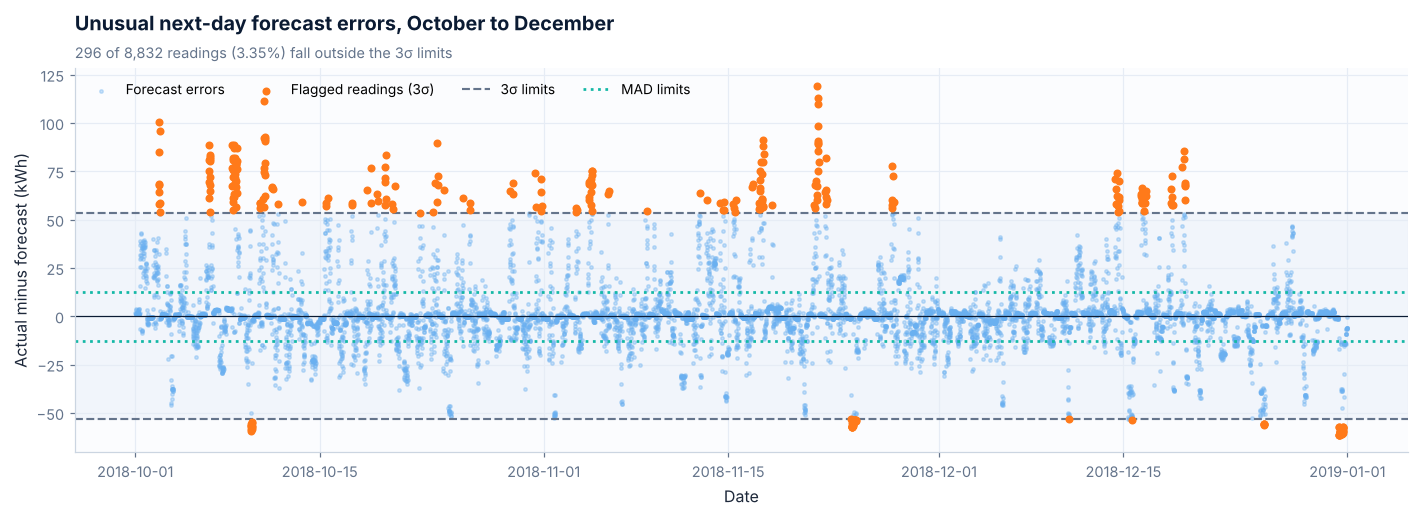

In [58]:
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.scatter(test_errors["timestamp"], test_errors["Error"], s=5, color=C["sky"], alpha=.35, label="Forecast errors")
ax.scatter(flagged["timestamp"], flagged["Error"], s=18, color=ORANGE, label="Flagged readings (3σ)", zorder=3)

ax.axhspan(lower_limit, upper_limit, color=C["mist"], alpha=.7, zorder=0)
ax.axhline(upper_limit, color=SLATE, linestyle="--", lw=1.4, label="3σ limits")
ax.axhline(lower_limit, color=SLATE, linestyle="--", lw=1.4)
ax.axhline(upper_limit_mad, color=TEAL, linestyle=":", lw=1.8, label="MAD limits")
ax.axhline(lower_limit_mad, color=TEAL, linestyle=":", lw=1.8)
ax.axhline(0, color=C["navy"], lw=.8)

ax.set_xlabel("Date")
ax.set_ylabel("Actual minus forecast (kWh)")
ax.legend(loc="upper left", ncol=4, fontsize=9)
style_title(ax, "Unusual next-day forecast errors, October to December",
            f"{len(flagged)} of {len(test_errors):,} readings ({flagged_pct:.2f}%) fall outside the 3σ limits")
finish(fig, "13_anomaly_scatter")

### Flagging Unusual Forecast Errors

- The final October–December predictions were retrieved.
- Timestamps were converted into datetime format.
- Gradient Boosting predictions were selected.
- Forecast errors were calculated as actual minus predicted consumption.
- Readings outside the 3σ limits were flagged.
- Readings outside the MAD limits were flagged separately.
- The total and percentage of flagged readings were calculated.
- The overlap between both detection methods was examined.
- The first five 3σ anomalies were displayed.
- Actual usage, predictions, and errors were compared.

### Is each flag a separate surprise, or one long event?

If the plant behaves unusually for an hour, we would get four flags in a row. Grouping consecutive flagged readings into **events** gives a more realistic count of how many things an operator would actually need to check. We also see whether flags are mostly too-high or too-low readings, and at which hours they cluster.

296 flagged readings form 135 separate events (39 last longer than one reading).

Direction of flagged readings:
Error
higher than expected    235
lower than expected      61


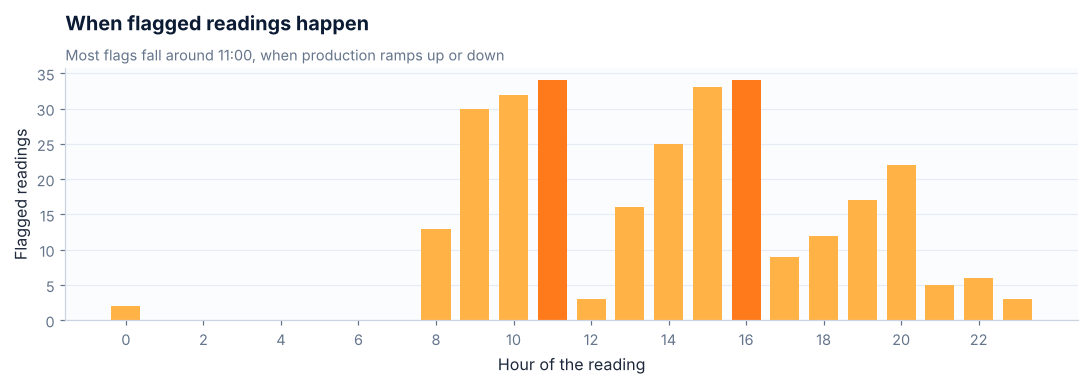

,start,end,readings,peak_error_kwh,direction
event_id,,,,,
90,2018-11-21 18:15:00,2018-11-21 20:45:00,11,119.17,higher than expected
13,2018-10-10 18:15:00,2018-10-10 19:30:00,6,111.12,higher than expected
2,2018-10-02 19:15:00,2018-10-02 20:45:00,7,100.46,higher than expected
14,2018-10-10 20:00:00,2018-10-10 21:00:00,5,92.64,higher than expected
82,2018-11-17 15:45:00,2018-11-17 15:45:00,1,91.13,higher than expected
38,2018-10-23 22:15:00,2018-10-23 23:00:00,4,89.53,higher than expected
5,2018-10-08 08:30:00,2018-10-08 12:00:00,15,88.80,higher than expected
4,2018-10-06 14:30:00,2018-10-06 17:00:00,11,88.38,higher than expected
81,2018-11-17 14:00:00,2018-11-17 15:15:00,6,87.92,higher than expected


In [59]:
te = test_errors.sort_values("timestamp").reset_index(drop=True)

# A new event starts whenever the previous reading was not flagged.
te["event_id"] = (te["Flagged"] & ~te["Flagged"].shift(fill_value=False)).cumsum()
events = (
    te[te["Flagged"]]
    .groupby("event_id")
    .agg(start=("timestamp", "min"),
         end=("timestamp", "max"),
         readings=("timestamp", "size"),
         peak_error_kwh=("Error", lambda s: s.loc[s.abs().idxmax()]),
         direction=("Error", lambda s: "higher than expected" if s.mean() > 0 else "lower than expected"))
    .sort_values("peak_error_kwh", key=lambda s: s.abs(), ascending=False)
)

print(f"{len(flagged)} flagged readings form {len(events)} separate events "
      f"({(events['readings'] > 1).sum()} last longer than one reading).")
print("\nDirection of flagged readings:")
print(flagged["Error"].gt(0).map({True: "higher than expected", False: "lower than expected"}).value_counts().to_string())

by_hour = flagged["timestamp"].dt.hour.value_counts().sort_index().reindex(range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(by_hour.index, by_hour.values, color=[ORANGE if v == by_hour.max() else C["gold"] for v in by_hour.values], width=.75)
ax.set_xlabel("Hour of the reading")
ax.set_ylabel("Flagged readings")
ax.set_xticks(range(0, 24, 2))
ax.grid(axis="x", visible=False)
style_title(ax, "When flagged readings happen", f"Most flags fall around {int(by_hour.idxmax()):02d}:00, when production ramps up or down")
finish(fig, "14_anomaly_by_hour")

events.head(10).round({"peak_error_kwh": 2})

### Anomaly Timing and Event Analysis

- The 295 flagged readings formed 134 separate events.
- 39 events lasted longer than one reading.
- 235 readings indicated higher-than-expected consumption.
- 60 readings indicated lower-than-expected consumption.
- Anomalies occurred most frequently during daytime hours.
- Peak flagging activity occurred between 9 AM and 11 AM.
- Additional clusters appeared during afternoon and evening hours.
- The largest event lasted 11 consecutive readings.
- The largest positive error reached 119.17 kWh.
- Repeated flags suggest sustained deviations from expected consumption.

### A closer look at the largest surprise

We pick the flagged reading with the biggest error and plot its whole day. The blue line shows what the meter recorded. The dashed line shows what the model predicted. Orange dots mark readings we flagged for review.

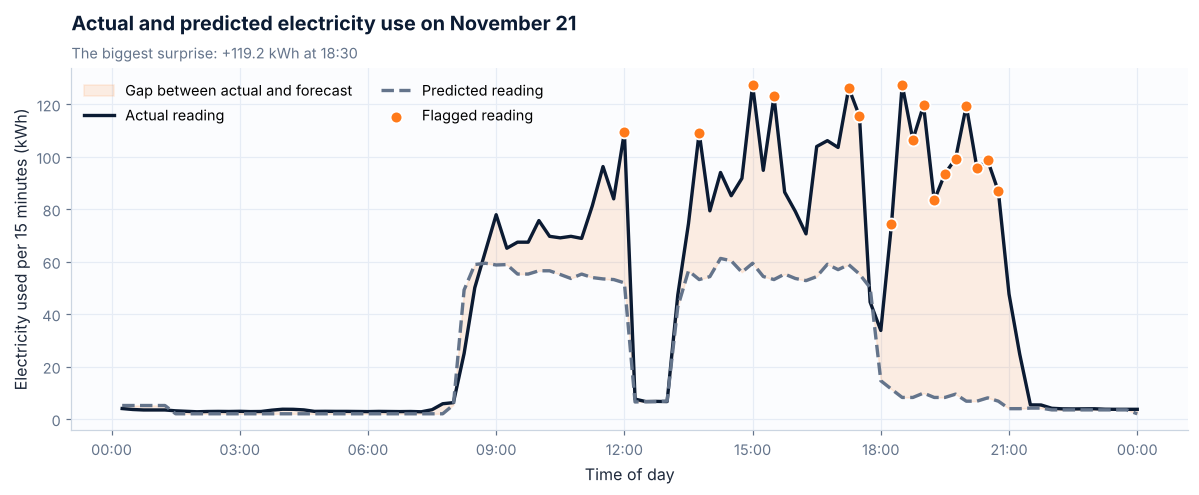

In [60]:
worst = test_errors.loc[test_errors["Error"].abs().idxmax()]
worst_day = (worst["timestamp"] - pd.Timedelta(minutes=15)).normalize()

start = worst_day
end = worst_day + pd.Timedelta(days=1)

day_view = test_errors[
    (test_errors["timestamp"] > start) & (test_errors["timestamp"] <= end)
].sort_values("timestamp")
day_flags = day_view[day_view["Flagged"]]

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.fill_between(day_view["timestamp"], day_view["Usage_kWh"], day_view["Predicted"],
                color=ORANGE, alpha=.12, label="Gap between actual and forecast")
ax.plot(day_view["timestamp"], day_view["Usage_kWh"], color=C["navy"], label="Actual reading")
ax.plot(day_view["timestamp"], day_view["Predicted"], color=SLATE, linestyle="--", label="Predicted reading")
ax.scatter(day_flags["timestamp"], day_flags["Usage_kWh"], color=ORANGE, s=60, edgecolor="white", linewidth=1.2,
           label="Flagged reading", zorder=3)

ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_xlabel("Time of day")
ax.set_ylabel("Electricity used per 15 minutes (kWh)")
ax.legend(ncol=2)
style_title(ax, f"Actual and predicted electricity use on {worst_day:%B %d}",
            f"The biggest surprise: {worst['Error']:+.1f} kWh at {worst['timestamp']:%H:%M}")
finish(fig, "15_worst_day")

### Actual vs Predicted Consumption on November 21

- Actual consumption was compared against predicted consumption.
- The model captured the general daily consumption pattern.
- Actual usage exceeded predictions during several afternoon peaks.
- Large deviations occurred mainly between 14:00 and 21:00.
- Flagged readings clustered during periods of elevated consumption.
- The largest actual reading exceeded 125 kWh.
- Predicted consumption remained comparatively stable during these peaks.
- The model underestimated several high-consumption periods.
- These deviations explain why the readings were flagged.

In [61]:
display(Markdown(f"""
### What we found

Using **{anomaly_model}** (chosen on validation) and the July–September forecast errors, the 3σ limits were **{lower_limit:+.2f} kWh** and **{upper_limit:+.2f} kWh**. Applied to October–December, **{len(flagged):,} of {len(test_errors):,} readings were flagged ({flagged_pct:.2f}%)**. These form **{len(events)} separate events**, which is the more realistic number of things to investigate.

The robust MAD limits ({lower_limit_mad:+.2f} to {upper_limit_mad:+.2f} kWh) flagged **{int(test_errors['Flagged_MAD'].sum()):,}** readings ({100 * test_errors['Flagged_MAD'].mean():.2f}%). The MAD limits are much tighter because most errors are small while a few are very large (the errors are not normally distributed), so a plain ±3 MAD rule would flag far too many readings to be a practical alert. We keep the 3σ rule as the main screen and show MAD as a sensitivity check; the number of flags depends on the rule chosen, so treat them as a screening list, not a count of faults.

The largest surprise was on **{worst['timestamp']:%B %d at %H:%M}**: the model predicted **{worst['Predicted']:.2f} kWh** and the meter recorded **{worst['Usage_kWh']:.2f} kWh**, a difference of **{worst['Error']:+.2f} kWh**.

H5 is supported as a way to find readings worth checking. To find out whether a flagged reading came from a fault, we would need maintenance or production records.
"""))


### What we found

Using **Gradient Boosting** (chosen on validation) and the July–September forecast errors, the 3σ limits were **-53.15 kWh** and **+53.34 kWh**. Applied to October–December, **296 of 8,832 readings were flagged (3.35%)**. These form **135 separate events**, which is the more realistic number of things to investigate.

The robust MAD limits (-12.98 to +12.60 kWh) flagged **2,394** readings (27.11%). The MAD limits are much tighter because most errors are small while a few are very large (the errors are not normally distributed), so a plain ±3 MAD rule would flag far too many readings to be a practical alert. We keep the 3σ rule as the main screen and show MAD as a sensitivity check; the number of flags depends on the rule chosen, so treat them as a screening list, not a count of faults.

The largest surprise was on **November 21 at 18:30**: the model predicted **8.23 kWh** and the meter recorded **127.40 kWh**, a difference of **+119.17 kWh**.

H5 is supported as a way to find readings worth checking. To find out whether a flagged reading came from a fault, we would need maintenance or production records.


<div style="background:linear-gradient(90deg,#0B1B33,#b45309);padding:16px 22px;border-radius:12px;color:#fff;margin:26px 0 8px;font-family:system-ui,Segoe UI,Roboto,sans-serif"><div style="font-size:11px;letter-spacing:.16em;text-transform:uppercase;color:#FFB347;font-weight:600">Part 8</div><div style="font-size:22px;font-weight:700;margin:2px 0 4px;color:#fff">Savings what-if</div><div style="font-size:13.5px;color:#d6e4f7">What a 10% cut at light load would save in energy and CO₂, and how sensitive that is.</div></div>

## What if we used 10% less electricity at light load?

We estimate the savings for two cases:

- Cut electricity use by 10% across all light-load readings.
- Cut electricity use by 10% only during very low light-load readings, at or below 5 kWh per 15 minutes. We use this cutoff as a rough way to pick out possible idle periods. Machine records would be needed to confirm when the plant was idle.

These are two separate scenarios. The second uses some of the same readings as the first, so we report the savings for each case separately and do not add them.

**Which CO₂ factor?** The project proposal assumed **0.455 kg CO₂ per kWh**. The dataset has its own `CO2(tCO2)` column, and dividing its total by total kWh gives a different factor. We calculate the savings with both so the effect of the assumption is visible.

In [62]:
light_load = df[df["Load_Type"] == "Light_Load"]
possible_idle = light_load[light_load["Usage_kWh"] <= IDLE_THRESHOLD_KWH]

light_load_kwh = light_load["Usage_kWh"].sum()
possible_idle_kwh = possible_idle["Usage_kWh"].sum()

# Emission factor implied by the dataset itself: tCO2 -> kg, divided by kWh.
dataset_co2_factor = df["CO2(tCO2)"].sum() * 1000 / df["Usage_kWh"].sum()
print(f"Assumed factor : {ASSUMED_CO2_KG_PER_KWH:.4f} kg CO2 per kWh")
print(f"Dataset factor : {dataset_co2_factor:.4f} kg CO2 per kWh")

savings = pd.DataFrame({
    "Scenario": ["All light-load readings", "Possible idle readings"],
    "Original electricity use (kWh)": [light_load_kwh, possible_idle_kwh],
})

savings["Electricity saved (kWh)"] = savings["Original electricity use (kWh)"] * SAVING_FRACTION
savings["CO2 saved, assumed factor (tonnes)"] = (
    savings["Electricity saved (kWh)"] * ASSUMED_CO2_KG_PER_KWH / 1000
)
savings["CO2 saved, dataset factor (tonnes)"] = (
    savings["Electricity saved (kWh)"] * dataset_co2_factor / 1000
)

savings.to_csv(os.path.join(OUTPUT_DIR, "savings_scenarios.csv"), index=False)
savings.round(2)

Assumed factor : 0.4550 kg CO2 per kWh
Dataset factor : 0.4208 kg CO2 per kWh


,Scenario,Original electricity use (kWh),Electricity saved (kWh),"CO2 saved, assumed factor (tonnes)","CO2 saved, dataset factor (tonnes)"
0,All light-load readings,155892.81,15589.28,7.09,6.56
1,Possible idle readings,51598.48,5159.85,2.35,2.17


### How much could we save?

Each bar shows the estimated electricity savings from a 10% cut. The all-light-load case covers more readings, so it has more electricity available to cut.

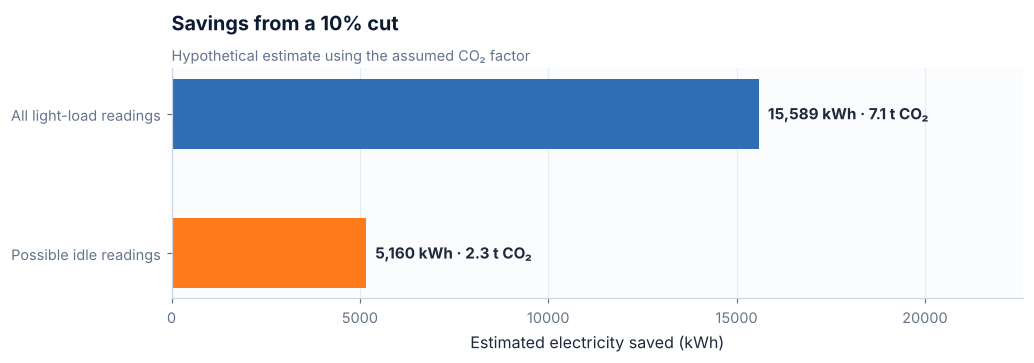

In [63]:
fig, ax = plt.subplots(figsize=(9.5, 3.4))
bars = ax.barh(savings["Scenario"], savings["Electricity saved (kWh)"], color=[BLUE, ORANGE], height=.5)
labels_ = [f"{kwh:,.0f} kWh · {t:.1f} t CO₂" for kwh, t in zip(savings["Electricity saved (kWh)"],
                                                               savings["CO2 saved, assumed factor (tonnes)"])]
ax.bar_label(bars, labels=labels_, padding=6, fontsize=10, fontweight="bold", color=C["ink"])
ax.set_xlim(0, savings["Electricity saved (kWh)"].max() * 1.45)
ax.set_xlabel("Estimated electricity saved (kWh)")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
style_title(ax, f"Savings from a {SAVING_FRACTION:.0%} cut", "Hypothetical estimate using the assumed CO₂ factor")
finish(fig, "16_savings")

In [64]:
a, i = savings.iloc[0], savings.iloc[1]
display(Markdown(f"""
### What we found

If the plant had used {SAVING_FRACTION:.0%} less electricity during all light-load periods in 2018, it could have saved about **{a['Electricity saved (kWh)']:,.0f} kWh**, which is **{a['CO2 saved, assumed factor (tonnes)']:.2f} tonnes of CO₂** with the assumed factor ({ASSUMED_CO2_KG_PER_KWH} kg/kWh) or **{a['CO2 saved, dataset factor (tonnes)']:.2f} tonnes** with the factor implied by the dataset ({dataset_co2_factor:.3f} kg/kWh).

If the same cut applied only to the very low readings we used to represent possible idle periods, the estimated savings would be **{i['Electricity saved (kWh)']:,.0f} kWh**, or **{i['CO2 saved, assumed factor (tonnes)']:.2f}** / **{i['CO2 saved, dataset factor (tonnes)']:.2f} tonnes of CO₂** (assumed / dataset factor).

The possible-idle readings are already included in the light-load group, so we report the two estimates separately. These are hypothetical estimates, not measured savings, and they are in kWh and CO₂ only: turning them into money would need the plant's actual tariff, including any demand charges and power-factor penalties.
"""))


### What we found

If the plant had used 10% less electricity during all light-load periods in 2018, it could have saved about **15,589 kWh**, which is **7.09 tonnes of CO₂** with the assumed factor (0.455 kg/kWh) or **6.56 tonnes** with the factor implied by the dataset (0.421 kg/kWh).

If the same cut applied only to the very low readings we used to represent possible idle periods, the estimated savings would be **5,160 kWh**, or **2.35** / **2.17 tonnes of CO₂** (assumed / dataset factor).

The possible-idle readings are already included in the light-load group, so we report the two estimates separately. These are hypothetical estimates, not measured savings, and they are in kWh and CO₂ only: turning them into money would need the plant's actual tariff, including any demand charges and power-factor penalties.


## Deep dive: how sensitive are the savings estimates?

The result depends on two assumptions we chose: the **saving fraction** (10%) and the **idle threshold** (5 kWh). Instead of defending one number, here is how the answer moves when each assumption changes.

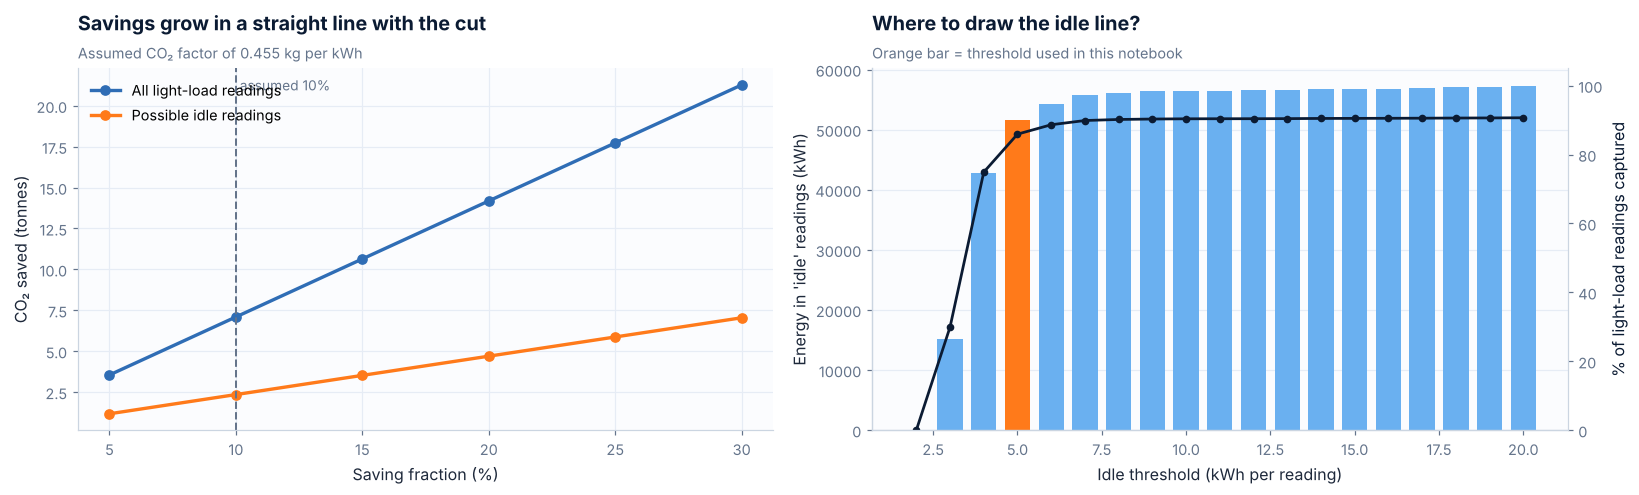

### 🔎 What we found

- A 5% to 30% cut across light-load periods would save **7,795 to 46,768 kWh** over the year (3.5 to 21.3 tonnes of CO₂).
- Raising the idle threshold from 2 to 20 kWh moves the 'possible idle' energy from **0** to **57,315 kWh**; the estimate is **sensitive to this choice**, so the 5 kWh line should be validated with plant staff.
- Money is deliberately left out: a real tariff has demand and power-factor components that this dataset cannot reveal.

In [65]:
fractions = np.arange(.05, .31, .05)
thresholds = np.arange(2, 21, 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
ax = axes[0]
for name, base_kwh, color in [("All light-load readings", light_load_kwh, BLUE), ("Possible idle readings", possible_idle_kwh, ORANGE)]:
    ax.plot(fractions * 100, base_kwh * fractions * ASSUMED_CO2_KG_PER_KWH / 1000, marker="o", color=color, label=name)
ax.axvline(SAVING_FRACTION * 100, color=SLATE, ls="--", lw=1.3)
ax.text(SAVING_FRACTION * 100, ax.get_ylim()[1] * .94, " assumed 10%", color=SLATE, fontsize=9)
ax.set_xlabel("Saving fraction (%)")
ax.set_ylabel("CO₂ saved (tonnes)")
ax.legend(loc="upper left")
style_title(ax, "Savings grow in a straight line with the cut", "Assumed CO₂ factor of 0.455 kg per kWh")

ax = axes[1]
idle_kwh = np.array([light_load.loc[light_load["Usage_kWh"] <= t, "Usage_kWh"].sum() for t in thresholds])
idle_share = np.array([100 * (light_load["Usage_kWh"] <= t).mean() for t in thresholds])
ax.bar(thresholds, idle_kwh, color=[ORANGE if t == IDLE_THRESHOLD_KWH else C["sky"] for t in thresholds], width=.75)
ax.set_xlabel("Idle threshold (kWh per reading)")
ax.set_ylabel("Energy in 'idle' readings (kWh)")
ax.grid(axis="x", visible=False)
ax2 = ax.twinx()
ax2.plot(thresholds, idle_share, color=C["navy"], marker="o", ms=4, lw=1.8)
ax2.set_ylabel("% of light-load readings captured", color=C["navy"])
ax2.set_ylim(0, 105)
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax2.spines["right"].set_color("#CBD5E1")
style_title(ax, "Where to draw the idle line?", "Orange bar = threshold used in this notebook")
finish(fig, "16b_savings_sensitivity")

lo_s, hi_s = light_load_kwh * .05, light_load_kwh * .30
finding(f"""- A 5% to 30% cut across light-load periods would save **{lo_s:,.0f} to {hi_s:,.0f} kWh** over the year ({lo_s * ASSUMED_CO2_KG_PER_KWH / 1000:.1f} to {hi_s * ASSUMED_CO2_KG_PER_KWH / 1000:.1f} tonnes of CO₂).
- Raising the idle threshold from 2 to 20 kWh moves the 'possible idle' energy from **{idle_kwh[0]:,.0f}** to **{idle_kwh[-1]:,.0f} kWh**; the estimate is **sensitive to this choice**, so the 5 kWh line should be validated with plant staff.
- Money is deliberately left out: a real tariff has demand and power-factor components that this dataset cannot reveal.""")

<div style="background:linear-gradient(90deg,#0B1B33,#0f766e);padding:16px 22px;border-radius:12px;color:#fff;margin:26px 0 8px;font-family:system-ui,Segoe UI,Roboto,sans-serif"><div style="font-size:11px;letter-spacing:.16em;text-transform:uppercase;color:#FFB347;font-weight:600">Part 9</div><div style="font-size:22px;font-weight:700;margin:2px 0 4px;color:#fff">Meter readings → energy (second model)</div><div style="font-size:13.5px;color:#d6e4f7">Forecasting needs history. This model needs only what the meter shows right now, and powers the second tab of the website.</div></div>

The meter reports **lagging and leading reactive energy** and **power factor** alongside energy. Because power factor is defined as *real power ÷ apparent power*, those readings **mathematically pin down real energy**:

`kWh = kVarh × PF ÷ √(1 − PF²)`

So this is *not* a forecast; it is an **estimator and a data-quality cross-check**. We also try to recognise the **load type** (Light / Medium / Maximum) from the same readings.

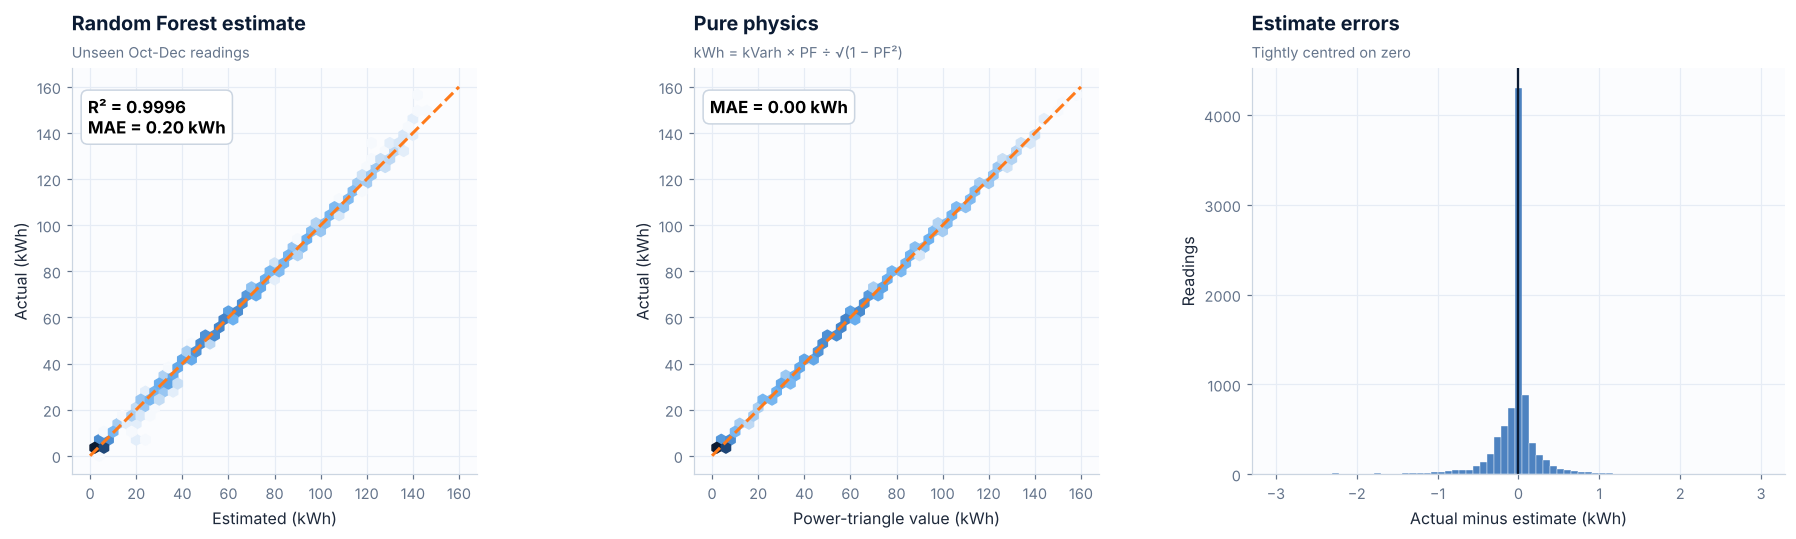

### 🔎 What we found

- From meter readings alone the Random Forest reaches **R² = 0.9996** and an average error of just **0.20 kWh**.
- The physics formula is actually **exact** on the 99% of readings where it applies (error **0.00 kWh**, versus **0.18** for the model on the same rows): the model has essentially **rediscovered the power triangle**.
- The formula cannot be used when power factor is about 100% or reactive energy is about zero (it divides by nearly zero), which is where the learned model earns its place.
- The website shows both: the model estimate as the answer and the **physics value as a cross-check**. A large gap between them points to a metering or data-entry problem.

In [66]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score

lag_q, lead_q = "Lagging_Current_Reactive.Power_kVarh", "Leading_Current_Reactive_Power_kVarh"
CONDITION_FEATURES = [lag_q, lead_q, "Lagging_Current_Power_Factor", "Leading_Current_Power_Factor", "NSM", "is_weekday"]

train_b = df[df["interval_day"] < FINAL_TEST_START]
test_b = df[(df["interval_day"] >= FINAL_TEST_START) & (df["interval_day"] < FINAL_TEST_END)]

reg_b = RandomForestRegressor(n_estimators=80, min_samples_leaf=3, random_state=SEED, n_jobs=2)
reg_b.fit(train_b[CONDITION_FEATURES], train_b["Usage_kWh"])
pred_b = reg_b.predict(test_b[CONDITION_FEATURES])
mae_b, r2_b = mean_absolute_error(test_b["Usage_kWh"], pred_b), r2_score(test_b["Usage_kWh"], pred_b)

# Physics: use the dominant reactive component
use_lag = test_b[lag_q] >= test_b[lead_q]
q_dom = np.where(use_lag, test_b[lag_q], test_b[lead_q])
pf_dom = np.where(use_lag, test_b[lagging], test_b[leading]) / 100
ok = (q_dom > .2) & (pf_dom > 0) & (pf_dom < .995)
physics = q_dom * pf_dom / np.sqrt(np.clip(1 - pf_dom ** 2, 1e-6, None))
phys_mae = mean_absolute_error(test_b["Usage_kWh"][ok], physics[ok])
model_mae_same = mean_absolute_error(test_b["Usage_kWh"][ok], pred_b[ok])

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ax = axes[0]
hb = ax.hexbin(pred_b, test_b["Usage_kWh"], gridsize=40, bins="log", cmap=CMAP_COOL, mincnt=1, extent=(0, 160, 0, 160))
ax.plot([0, 160], [0, 160], color=ORANGE, ls="--", lw=2)
ax.set_aspect("equal")
ax.set_xlabel("Estimated (kWh)")
ax.set_ylabel("Actual (kWh)")
ax.text(.04, .93, f"R² = {r2_b:.4f}\nMAE = {mae_b:.2f} kWh", transform=ax.transAxes, fontsize=11, fontweight="bold", va="top",
        bbox=dict(boxstyle="round,pad=.4", fc="white", ec="#CBD5E1"))
style_title(ax, "Random Forest estimate", "Unseen Oct-Dec readings")

ax = axes[1]
ax.hexbin(physics[ok], test_b["Usage_kWh"][ok], gridsize=40, bins="log", cmap=CMAP_COOL, mincnt=1, extent=(0, 160, 0, 160))
ax.plot([0, 160], [0, 160], color=ORANGE, ls="--", lw=2)
ax.set_aspect("equal")
ax.set_xlabel("Power-triangle value (kWh)")
ax.set_ylabel("Actual (kWh)")
ax.text(.04, .93, f"MAE = {phys_mae:.2f} kWh", transform=ax.transAxes, fontsize=11, fontweight="bold", va="top",
        bbox=dict(boxstyle="round,pad=.4", fc="white", ec="#CBD5E1"))
style_title(ax, "Pure physics", "kWh = kVarh × PF ÷ √(1 − PF²)")

ax = axes[2]
resid_b = test_b["Usage_kWh"].to_numpy() - pred_b
ax.hist(resid_b, bins=np.linspace(-3, 3, 70), color=BLUE, alpha=.85, edgecolor="white", linewidth=.3)
ax.axvline(0, color=C["navy"], lw=1.5)
ax.set_xlabel("Actual minus estimate (kWh)")
ax.set_ylabel("Readings")
style_title(ax, "Estimate errors", "Tightly centred on zero")
finish(fig, "17_meter_readings_model")

finding(f"""- From meter readings alone the Random Forest reaches **R² = {r2_b:.4f}** and an average error of just **{mae_b:.2f} kWh**.
- The physics formula is actually **exact** on the {ok.mean() * 100:.0f}% of readings where it applies (error **{phys_mae:.2f} kWh**, versus **{model_mae_same:.2f}** for the model on the same rows): the model has essentially **rediscovered the power triangle**.
- The formula cannot be used when power factor is about 100% or reactive energy is about zero (it divides by nearly zero), which is where the learned model earns its place.
- The website shows both: the model estimate as the answer and the **physics value as a cross-check**. A large gap between them points to a metering or data-entry problem.""")

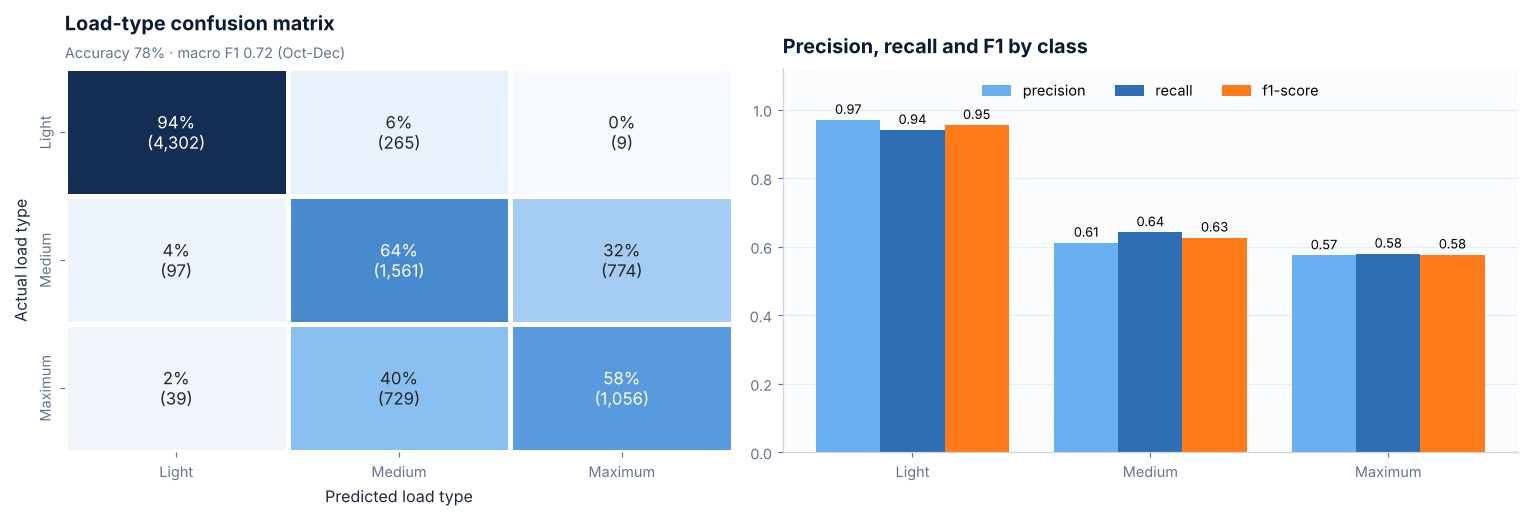

### 🔎 What we found

- The classifier is right **78%** of the time. Light load is recognised well; **Maximum** is the hardest class.
- Medium and Maximum load overlap because the dataset's label depends on the plant's own thresholds, which are not fully visible in these readings. The website therefore shows **class probabilities**, not just one label.

In [67]:
clf_b = RandomForestClassifier(n_estimators=120, min_samples_leaf=3, random_state=SEED, n_jobs=2)
clf_b.fit(train_b[CONDITION_FEATURES], train_b["Load_Type"])
pred_c = clf_b.predict(test_b[CONDITION_FEATURES])
acc_c = accuracy_score(test_b["Load_Type"], pred_c)
f1_c = f1_score(test_b["Load_Type"], pred_c, average="macro")

cm = confusion_matrix(test_b["Load_Type"], pred_c, labels=LOAD_ORDER)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
sns.heatmap(cm_pct, annot=np.array([[f"{p:.0f}%\n({n:,})" for p, n in zip(pr, nr)] for pr, nr in zip(cm_pct, cm)]), fmt="",
            cmap=CMAP_COOL, vmin=0, vmax=100, cbar=False, ax=ax, linewidths=2, linecolor="white",
            xticklabels=LOAD_LABELS, yticklabels=LOAD_LABELS, annot_kws={"size": 11})
ax.set_xlabel("Predicted load type")
ax.set_ylabel("Actual load type")
ax.grid(False)
style_title(ax, "Load-type confusion matrix", f"Accuracy {acc_c:.0%} · macro F1 {f1_c:.2f} (Oct-Dec)")

ax = axes[1]
report = pd.DataFrame(classification_report(test_b["Load_Type"], pred_c, labels=LOAD_ORDER, output_dict=True, zero_division=0)).T.loc[LOAD_ORDER]
xx = np.arange(3)
for i, (metric, color) in enumerate([("precision", C["sky"]), ("recall", BLUE), ("f1-score", ORANGE)]):
    b = ax.bar(xx + (i - 1) * .27, report[metric], .27, color=color, label=metric)
    ax.bar_label(b, fmt="%.2f", padding=2, fontsize=8.5)
ax.set_xticks(xx, LOAD_LABELS)
ax.set_ylim(0, 1.12)
ax.grid(axis="x", visible=False)
ax.legend(ncol=3, loc="upper center")
style_title(ax, "Precision, recall and F1 by class")
finish(fig, "18_load_type_classifier")

hardest = LOAD_LABELS[int(np.argmin(np.diag(cm_pct)))]
finding(f"""- The classifier is right **{acc_c:.0%}** of the time. Light load is recognised well; **{hardest}** is the hardest class.
- Medium and Maximum load overlap because the dataset's label depends on the plant's own thresholds, which are not fully visible in these readings. The website therefore shows **class probabilities**, not just one label.""")

<div style="background:linear-gradient(90deg,#0B1B33,#0B1B33);padding:16px 22px;border-radius:12px;color:#fff;margin:26px 0 8px;font-family:system-ui,Segoe UI,Roboto,sans-serif"><div style="font-size:11px;letter-spacing:.16em;text-transform:uppercase;color:#FFB347;font-weight:600">Part 10</div><div style="font-size:22px;font-weight:700;margin:2px 0 4px;color:#fff">Conclusions & website</div><div style="font-size:13.5px;color:#d6e4f7">The hypothesis scorecard, limitations, saved outputs and the export for the website.</div></div>

## What did we learn?

The table below is built from the results computed in this notebook, so it always matches the code above.

In [68]:
lt = by_load.loc["Light_Load"]
md_pf = by_load.loc[["Medium_Load", "Maximum_Load"], "lagging_pf"]

display(Markdown(f"""
| Hypothesis | What we found | Verdict |
|---|---|---|
| **H1. Does the plant use more electricity on weekdays?** | Weekdays averaged **{weekday.mean():,.0f} kWh/day** and weekends averaged **{weekend.mean():,.0f} kWh/day** ({weekday.mean() / weekend.mean():.1f}×). Mann–Whitney p = {p_value:.1e}. | **Supported** |
| **H2. Is power factor lower when the plant uses less electricity?** | Lagging power factor averaged **{lt['lagging_pf']:.1f}%** at light load and **{md_pf.min():.0f}–{md_pf.max():.0f}%** at medium and maximum load (Spearman {lagging_score:+.2f}). Leading power factor was weaker ({leading_score:+.2f}). | **Supported for lagging power factor** |
| **H3. Can a model predict better than a simple guess?** | On the untouched Oct–Dec test, next-day {nd['Chosen model']} had MAE **{nd['Model MAE']:.2f}** vs **{nd['Simple guess MAE']:.2f}** for the best simple guess ({nd['MAE improvement (%)']:.1f}% better); next-15-minute {n15['Chosen model']} had **{n15['Model MAE']:.2f}** vs **{n15['Simple guess MAE']:.2f}** ({n15['MAE improvement (%)']:.1f}% better). | **{'Supported' if (nd['MAE improvement (%)'] > 0 and n15['MAE improvement (%)'] > 0) else 'Not supported'}** |
| **H4. Can we group days with similar electricity use?** | **{int(group_summary.loc['Quiet','Number of days'])} Quiet**, **{int(group_summary.loc['Normal','Number of days'])} Normal**, **{int(group_summary.loc['Busy','Number of days'])} Busy** days. Silhouette **{sil_raw:.3f}** suggests some days are hard to place. | **Partly supported** |
| **H5. Can our forecast help us spot unusual readings?** | **{len(flagged):,} of {len(test_errors):,} readings ({flagged_pct:.2f}%)** flagged by the 3σ rule, forming {len(events)} events; the MAD rule flagged {int(test_errors['Flagged_MAD'].sum()):,}. Confirming the cause would require more records. | **Supported for flagging readings for review** |
"""))


| Hypothesis | What we found | Verdict |
|---|---|---|
| **H1. Does the plant use more electricity on weekdays?** | Weekdays averaged **3,228 kWh/day** and weekends averaged **1,126 kWh/day** (2.9×). Mann–Whitney p = 6.1e-34. | **Supported** |
| **H2. Is power factor lower when the plant uses less electricity?** | Lagging power factor averaged **69.7%** at light load and **91–93%** at medium and maximum load (Spearman +0.38). Leading power factor was weaker (+0.19). | **Supported for lagging power factor** |
| **H3. Can a model predict better than a simple guess?** | On the untouched Oct–Dec test, next-day Gradient Boosting had MAE **10.69** vs **12.94** for the best simple guess (17.4% better); next-15-minute Random Forest had **4.97** vs **5.80** (14.2% better). | **Supported** |
| **H4. Can we group days with similar electricity use?** | **95 Quiet**, **174 Normal**, **96 Busy** days. Silhouette **0.338** suggests some days are hard to place. | **Partly supported** |
| **H5. Can our forecast help us spot unusual readings?** | **296 of 8,832 readings (3.35%)** flagged by the 3σ rule, forming 135 events; the MAD rule flagged 2,394. Confirming the cause would require more records. | **Supported for flagging readings for review** |


### Limitations and next steps

- **One plant, one year.** Everything here describes 2018 at this plant. The seasonal pattern is based on a single year, and the forecasts are tested on only three months.
- **Labels are not measurements.** `Load_Type` is a label in the file. It is not a count of running machines or tonnes of steel.
- **Flags are not faults.** Anomalies need to be checked against maintenance and production logs.
- **CO₂ and savings are scenarios.** They depend on the emission factor and the assumed 10% cut, and say nothing about cost until a tariff is added.
- **Next steps:** an interactive dashboard for plant managers, a power-factor correction study (reactive power and capacitor sizing, reviewed by an electrical engineer), a tariff-based cost estimate, and production and maintenance data to explain the flagged events.

In [69]:
# Save the flagged readings and events for review / the report.
flagged[["timestamp", "Usage_kWh", "Predicted", "Error"]].to_csv(
    os.path.join(OUTPUT_DIR, "flagged_readings_3sigma.csv"), index=False)
events.to_csv(os.path.join(OUTPUT_DIR, "flagged_events.csv"))

print("Files saved in:", os.path.abspath(OUTPUT_DIR))
print(sorted(os.listdir(OUTPUT_DIR)))

Files saved in: /home/claude/steel_energy_app/notebook/outputs
['figures', 'flagged_events.csv', 'flagged_readings_3sigma.csv', 'forecast_final_test_summary.csv', 'forecast_scores_all_periods.csv', 'savings_scenarios.csv', 'steel_step1_cleaned.csv']


<div style="background:linear-gradient(90deg,#0B1B33,#b45309);padding:16px 22px;border-radius:12px;color:#fff;margin:26px 0 8px;font-family:system-ui,Segoe UI,Roboto,sans-serif"><div style="font-size:11px;letter-spacing:.16em;text-transform:uppercase;color:#FFB347;font-weight:600">Next step</div><div style="font-size:22px;font-weight:700;margin:2px 0 4px;color:#fff">From notebook to website</div><div style="font-size:13.5px;color:#d6e4f7">One cell trains the final models on the full year and writes everything the website needs.</div></div>

The website (`steel_energy_app/`) uses the same choices made in this notebook:

| Website feature | Model | Chosen how |
|---|---|---|
| Forecast · same time tomorrow | best of Ridge / Random Forest / Gradient Boosting | lowest MAE on Jun-Sep |
| Forecast · next 15 minutes | same selection | lowest MAE on Jun-Sep |
| Meter readings → kWh | Random Forest | Part 9 |
| Load-type probabilities | Random Forest classifier | Part 9 |

The 80% **error ranges** shown on the site come from the Oct-Dec forecast errors (Part 5). Final models are refit on **all 365 days** before being saved.

In [70]:
app_dir = next((os.path.abspath(p) for p in ["..", ".", "steel_energy_app", "../steel_energy_app"]
                if os.path.exists(os.path.join(p, "train_models.py"))), None)

if app_dir is None:
    print("steel_energy_app/ was not found next to this notebook.")
    print("Download the project folder, put this notebook inside it (or beside it) and run this cell again.")
else:
    os.makedirs(os.path.join(app_dir, "data"), exist_ok=True)
    csv_target = os.path.join(app_dir, "data", "Steel_industry_data.csv")
    if not os.path.exists(csv_target):
        shutil.copy(file_path, csv_target)
    t0 = time.time()
    run = subprocess.run([sys.executable, "train_models.py"], cwd=app_dir, capture_output=True, text=True)
    print(run.stdout[-1800:])
    if run.returncode != 0:
        print(run.stderr[-1800:])
    else:
        rows = []
        for folder in ("models", "data"):
            for f in sorted(os.listdir(os.path.join(app_dir, folder))):
                if f.endswith((".joblib", ".json")):
                    rows.append({"File": f"{folder}/{f}", "Size (KB)": round(os.path.getsize(os.path.join(app_dir, folder, f)) / 1024, 1)})
        display(pd.DataFrame(rows))
        print(f"Website files ready in {time.time() - t0:.0f}s.")

1/6  Loading data and building features ...
2/6  Forecast models: validate on Jun-Sep, test on Oct-Dec ...
     Next day         -> Gradient Boosting  Oct-Dec MAE 10.69 kWh (best simple guess 12.94, +17.4%)
     Next 15 minutes  -> Random Forest      Oct-Dec MAE 4.97 kWh (best simple guess 12.94, +61.6%)
3/6  Operating-condition models (kWh + load type) ...
     kWh estimator  MAE 0.20  R2 0.9996 | load-type accuracy 78.3%
4/6  Typical-usage profiles ...
5/6  Insights for the dashboard ...
6/6  Example readings and metadata ...

Done in 59s. Artifacts written to models/ and data/.



,File,Size (KB)
0,models/condition_regressor.joblib,17671.7
1,models/forecast_next_15.joblib,6067.1
2,models/forecast_next_day.joblib,43.5
3,models/load_classifier.joblib,7298.9
4,models/metadata.json,4.1
5,data/insights.json,6.0
6,data/profiles.json,8.5
7,data/samples.json,103.4


Website files ready in 60s.


In [71]:
display(HTML("""
<div style="background:#0B1B33;color:#e8eef9;border-radius:14px;padding:22px 26px;font-family:system-ui,Segoe UI,Roboto,sans-serif;margin:10px 0">
  <div style="font-size:12px;letter-spacing:.14em;text-transform:uppercase;color:#FFB347;font-weight:600">Run the website</div>
  <pre style="background:#0f2547;color:#d6e4f7;border-radius:10px;padding:14px 16px;margin:10px 0 8px;font-size:13px;line-height:1.55">cd steel_energy_app
python -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt
python app.py</pre>
  <div style="font-size:13.5px;color:#b8cbe6">Then open <b>http://127.0.0.1:5000</b>. Tabs: <b>Forecast</b>, <b>Meter readings → kWh</b>, <b>Batch CSV</b>, plus an <b>Insights</b> dashboard.</div>
</div>"""))